# FairRoute — Comprehensive Policy Analysis (v4)

This notebook computes and visualizes **all metrics** from the FairRoute analysis specification,
covering RR, LOAD, RAND, PRISM, D2LPM, FAIRROUTE, FAIRROUTE_SLACK, and FAIRROUTE_GATED across workloads W1–W5,
load levels (ρ), client counts (K), and cluster configurations.

**Local scheduling policies:** results include the per-request `local scheduling policy` column. Set `MATRIX_LOCAL_POLICY=VTC` or `DLPM` in `run_fairroute_experiments.sh` to run those local schedulers; these are distinct from the global router named by `policy_name`. The notebook's headline comparisons remain grouped by router so historical FairRoute tables stay comparable.

**Data sources used:**
- `[CSV]` Per-request CSV with routing metadata and cache-tier hit counters
- `[TS]` Per-interval timeseries CSV with per-instance running/waiting/KV metrics
- `[ROUTING]` Aggregate routing diagnostics JSON
- `[TRACE]` Workload JSONL traces with `role`, `client_id`, token IDs

**Metrics that require `[SIDE]` (decision sidecar, not yet instrumented) are skipped with a message.**

## 0. Setup & Configuration

In [1]:
import os
import re
import json
import glob
import hashlib
import warnings
from pathlib import Path
from collections import defaultdict
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.colors import TwoSlopeNorm
import seaborn as sns
from scipy import stats as sp_stats

try:
    from IPython.display import display, HTML, Markdown
except ImportError:
    def display(*args, **kwargs):
        for a in args:
            if hasattr(a, 'to_string'):
                print(a.to_string())
            else:
                print(a)


warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning, module='seaborn')

# --- Style ---
plt.rcParams.update({
    'figure.dpi': 120,
    'figure.facecolor': '#0d1117',
    'axes.facecolor': '#161b22',
    'axes.edgecolor': '#30363d',
    'axes.labelcolor': '#c9d1d9',
    'text.color': '#c9d1d9',
    'xtick.color': '#8b949e',
    'ytick.color': '#8b949e',
    'grid.color': '#21262d',
    'legend.facecolor': '#161b22',
    'legend.edgecolor': '#30363d',
    'font.family': 'sans-serif',
    'font.size': 10,
    'axes.grid': True,
    'grid.alpha': 0.5,
    'savefig.bbox': 'tight',
})

# --- Policy colour palette ---
POLICY_COLORS = {
    'RR':        '#8b949e',
    'RAND':      '#6e7681',
    'LOAD':      '#58a6ff',
    'PRISM':     '#d29922',
    'D2LPM':     '#f0883e',
    'FAIRROUTE': '#3fb950',
    'FAIRROUTE_V2': '#3fb950',  # legacy result label for FAIRROUTE
    'FAIRROUTE_SLACK': '#a371f7',
    'FAIRROUTE_GATED': '#f778ba',
}
POLICY_MARKERS = {
    'RR': 'o', 'RAND': 'v', 'LOAD': 's', 'PRISM': 'D', 'D2LPM': 'P',
    'FAIRROUTE': 'X', 'FAIRROUTE_V2': 'X', 'FAIRROUTE_SLACK': '^', 'FAIRROUTE_GATED': 'h',
}

ROUTING_POLICIES = ['RR', 'LOAD', 'RAND', 'PRISM', 'D2LPM', 'FAIRROUTE', 'FAIRROUTE_SLACK', 'FAIRROUTE_GATED']
# FAIRROUTE_V2 is retained for archived runs and shares FAIRROUTE's visual style.
# --- Core policies (for headline charts; the rest appear in detail views) ---
CORE_POLICIES = ROUTING_POLICIES
BASELINE_POLICIES = ['RR', 'LOAD','RAND']

# --- Design choices [D] ---
W_P = 1       # VTC prompt weight
W_Q = 2       # VTC output weight
SLO_K_VALUES = [5, 10]   # TTFT SLO multipliers
STALL_MULTIPLIER = 5     # ITL stall = > 5× median gap
QUEUE_DELAY_THRESHOLD_S = 1.0  # 1 second
HOT_SPOT_MULTIPLIER = 2.0
KV_HIGH_WATER = 0.90
STARVATION_MULTIPLIER = 10

NS_TO_MS = 1e-6
NS_TO_S = 1e-9

# --- Paths ---
REPO_ROOT = Path('..').resolve()
DATA_ROOT = REPO_ROOT / 'outputs' / 'fairroute' / 'main'
WORKLOAD_ROOT = REPO_ROOT / 'workloads' / 'fairroute'/ 'main'
SCALING_DATA_ROOT = REPO_ROOT / 'outputs' / 'fairroute' / 'scaling'
SCALING_WORKLOAD_ROOT = REPO_ROOT / 'workloads' / 'fairroute' / 'scaling'
FIGURE_DIR = Path('./figures')
FIGURE_DIR.mkdir(exist_ok=True, parents=True)

print(f'Data root: {DATA_ROOT}')
print(f'Workload root: {WORKLOAD_ROOT}')
print(f'Data root exists: {DATA_ROOT.exists()}')


Data root: /media/sasank-v/NewVolume/Studies/College/VIT/Sem 7/Project I /Code/LLMServingSim/outputs/fairroute/main
Workload root: /media/sasank-v/NewVolume/Studies/College/VIT/Sem 7/Project I /Code/LLMServingSim/workloads/fairroute/main
Data root exists: True


## 1. Load and Validate (A1–A12)

In [2]:
# ─── Discover all run cells ───
def discover_runs(data_root, workload_root):
    """Discover all completed (workload, cell, policy) runs."""
    runs = []
    for wdir in sorted(data_root.iterdir()):
        if not wdir.is_dir():
            continue
        workload = wdir.name  # e.g., w1
        for cell_dir in sorted(wdir.iterdir()):
            if not cell_dir.is_dir():
                continue
            cell = cell_dir.name  # e.g., K16_L0.8_s100
            # Parse cell name
            m = re.match(r'K(\d+|na)_L([\d.]+)_s(\d+)', cell)
            if not m:
                continue
            K = int(m.group(1)) if m.group(1) != 'na' else 0
            rho = float(m.group(2))
            seed = int(m.group(3))
            # Find trace
            trace_path = workload_root / workload / cell / 'trace.jsonl'
            # Find per-policy CSVs
            for csv_path in sorted(cell_dir.glob('trace_policy_*.csv')):
                if '_timeseries' in csv_path.name:
                    continue
                policy = csv_path.name.replace('trace_policy_', '').replace('.csv', '')
                local_policy = 'FCFS'
                for candidate in ('VTC', 'DLPM'):
                    suffix = f'_local_{candidate}'
                    if policy.endswith(suffix):
                        policy = policy[:-len(suffix)]
                        local_policy = candidate
                        break
                ts_path = csv_path.with_name(csv_path.stem + '_timeseries.csv')
                routing_json = csv_path.with_name(csv_path.name + '.routing.json')
                sidecar_path = csv_path.with_name(csv_path.name + '.sidecar.jsonl')
                if not sidecar_path.exists():
                    sidecar_path = csv_path.with_name(csv_path.stem + '_sidecar.jsonl')
                runs.append({
                    'workload': workload,
                    'cell': cell,
                    'K': K,
                    'rho': rho,
                    'seed': seed,
                    'policy': policy,
                    'local_policy': local_policy,
                    'csv_path': str(csv_path),
                    'ts_path': str(ts_path) if ts_path.exists() else None,
                    'routing_json_path': str(routing_json) if routing_json.exists() else None,
                    'sidecar_path': str(sidecar_path) if sidecar_path.exists() else None,
                    'trace_path': str(trace_path) if trace_path.exists() else None,
                })
    return pd.DataFrame(runs)

run_index = discover_runs(DATA_ROOT, WORKLOAD_ROOT)
print(f'Discovered {len(run_index)} completed runs')
print(f'Workloads: {sorted(run_index["workload"].unique())}')
print(f'Policies: {sorted(run_index["policy"].unique())}')
print(f'Load levels (rho): {sorted(run_index["rho"].unique())}')
print(f'Seeds: {sorted(run_index["seed"].unique())}')

# Cross-tab
# Cross-tab
if len(run_index) > 0 and 'workload' in run_index.columns and 'rho' in run_index.columns:
    ct = run_index.groupby(['workload', 'rho']).policy.nunique().unstack(fill_value=0)
    display(ct)
else:
    print('No runs found or missing columns.')


Discovered 588 completed runs
Workloads: ['w1', 'w2', 'w3', 'w4', 'w5']
Policies: ['D2LPM', 'FAIRROUTE', 'FAIRROUTE_GATED', 'FAIRROUTE_SLACK', 'LOAD', 'PRISM', 'RAND', 'RR']
Load levels (rho): [0.5, 0.8, 1.0, 1.25, 1.5]
Seeds: [100]


rho,0.50,0.80,1.00,1.25,1.50
workload,,,,,
w1,7,7,7,8,8
w2,8,8,8,8,8
w3,8,8,8,8,8
w4,8,8,8,8,8
w5,8,8,8,8,8


In [3]:
# ─── Load all per-request CSVs ───
def load_all_csvs(run_index):
    """Load and concatenate all per-request CSVs with run metadata."""
    frames = []
    for _, row in run_index.iterrows():
        try:
            df = pd.read_csv(row['csv_path'])
            df['workload'] = row['workload']
            df['cell'] = row['cell']
            df['K'] = row['K']
            df['rho'] = row['rho']
            df['seed'] = row['seed']
            df['policy_name'] = row['policy']
            df['local_policy_name'] = (df['local scheduling policy'] if 'local scheduling policy' in df else row.get('local_policy', 'FCFS'))
            # The local scheduler is part of a run's identity: RR/FCFS and
            # RR/VTC use the same trace but are distinct experimental arms.
            df['run_key'] = f"{row['workload']}/{row['cell']}/{row['policy']}/{row['local_policy']}"
            df['policy_label'] = df['policy_name'] + ' / ' + df['local_policy_name']
            frames.append(df)
        except Exception as e:
            print(f"  WARN: Failed to load {row['csv_path']}: {e}")
    if not frames:
        raise RuntimeError('No CSVs loaded!')
    all_df = pd.concat(frames, ignore_index=True)
    return all_df

requests_df = load_all_csvs(run_index)
print(f'Loaded {len(requests_df):,} request rows across {requests_df["run_key"].nunique()} runs')
print(f'Columns: {list(requests_df.columns)}')
local_policies = sorted(requests_df['local_policy_name'].dropna().unique())
print(f'Local scheduling policies: {local_policies}')
if len(local_policies) > 1:
    print('NOTE: keep local_policy_name in every groupby/filter. Do not average FCFS, VTC, and DLPM into one router result.')

Loaded 616,560 request rows across 588 runs
Columns: ['instance id', 'request id', 'client id', 'model', 'input', 'output', 'arrival', 'end_time', 'latency', 'queuing_delay', 'TTFT', 'TPOT', 'ITL', 'routing policy', 'fairness debt', 'fairness urgency', 'locality', 'prediction', 'routing score', 'routing score margin', 'routing decision ns', 'routing stage', 'routing gate size', 'routing slack size', 'routing credit exhausted', 'prefix_cache_hit', 'npu_cache_hit', 'storage_cache_hit', 'recompute_tokens', 'num_preemptions', 'session_id', 'sub_request_index', 'trace_index', 'local scheduling policy', 'workload', 'cell', 'K', 'rho', 'seed', 'policy_name', 'local_policy_name', 'run_key', 'policy_label']
Local scheduling policies: ['DLPM', 'FCFS', 'VTC']
NOTE: keep local_policy_name in every groupby/filter. Do not average FCFS, VTC, and DLPM into one router result.


In [4]:
# ─── Load trace JSONL for role annotations ───
def load_trace_roles(run_index):
    """Load client_id -> role mapping from trace JSONLs."""
    role_maps = {}  # (workload, cell) -> {client_id: role}
    for (wl, cell), grp in run_index.groupby(['workload', 'cell']):
        trace_path = grp.iloc[0]['trace_path']
        if trace_path is None or not os.path.exists(trace_path):
            continue
        client_roles = {}
        try:
            with open(trace_path) as f:
                for line in f:
                    row = json.loads(line)
                    cid = row.get('client_id', 'default')
                    role = row.get('role', 'unknown')
                    if 'sub_requests' in row:
                        # agentic session
                        pass
                    client_roles[cid] = role
        except Exception as e:
            print(f'  WARN: Failed to parse trace {trace_path}: {e}')
        role_maps[(wl, cell)] = client_roles
    return role_maps

role_maps = load_trace_roles(run_index)

# Assign role to each request
def assign_role(row):
    key = (row['workload'], row['cell'])
    rm = role_maps.get(key, {})
    return rm.get(row['client id'], 'unknown')

requests_df['role'] = requests_df.apply(assign_role, axis=1)
print(f"Role distribution: {requests_df['role'].value_counts().to_dict()}")

Role distribution: {'unknown': 268560, 'short': 118000, 'light': 95920, 'normal': 75720, 'flooder': 44280, 'heavy': 14080}


In [5]:
# ─── P1: Unit conversions ───
requests_df['TTFT_ms'] = requests_df['TTFT'] * NS_TO_MS
requests_df['TPOT_ms'] = requests_df['TPOT'] * NS_TO_MS
requests_df['latency_ms'] = requests_df['latency'] * NS_TO_MS
requests_df['latency_s'] = requests_df['latency'] * NS_TO_S
requests_df['queuing_delay_ms'] = requests_df['queuing_delay'] * NS_TO_MS
requests_df['queuing_delay_s'] = requests_df['queuing_delay'] * NS_TO_S
requests_df['arrival_s'] = requests_df['arrival'] * NS_TO_S
requests_df['end_time_s'] = requests_df['end_time'] * NS_TO_S

# B7: Prefill phase time
requests_df['prefill_time_ms'] = (requests_df['TTFT'] - requests_df['queuing_delay']) * NS_TO_MS
# B8: Decode phase time
requests_df['decode_time_ms'] = (requests_df['latency'] - requests_df['TTFT']) * NS_TO_MS
# B10: Normalised latency
requests_df['norm_latency_ms'] = requests_df['latency_ms'] / requests_df['output'].clip(lower=1)

# P4: Service cost
requests_df['hit_tokens'] = requests_df['prefix_cache_hit'].fillna(0).astype(int)
requests_df['input_eff'] = (requests_df['input'] - requests_df['hit_tokens']).clip(lower=0)
requests_df['service_cost'] = W_P * requests_df['input_eff'] + W_Q * requests_df['output']

# Parse ITL
def parse_itl(s):
    if pd.isna(s) or s == '[]' or s == '':
        return []
    try:
        return json.loads(s)
    except:
        return []

requests_df['ITL_list'] = requests_df['ITL'].apply(parse_itl)
requests_df['ITL_count'] = requests_df['ITL_list'].apply(len)
requests_df['max_ITL_ms'] = requests_df['ITL_list'].apply(lambda x: max(x) * NS_TO_MS if x else 0)

# B13: Input length bins
requests_df['input_bin'] = pd.cut(
    requests_df['input'],
    bins=[0, 512, 2048, 4096, float('inf')],
    labels=['≤512', '512–2k', '2k–4k', '>4k']
)

# F7: Hit fraction
requests_df['hit_fraction'] = requests_df['hit_tokens'] / requests_df['input'].clip(lower=1)

print('Derived columns added.')
print(f"Total requests: {len(requests_df):,}")

Derived columns added.
Total requests: 616,560


In [6]:
# ─── A: Validity checks ───
def run_validity_checks(df, run_index):
    results = []
    for run_key, grp in df.groupby('run_key'):
        checks = {}
        # A3: end_time >= arrival, TTFT <= latency, output >= 1, no NaN
        checks['A3_end_ge_arrival'] = (grp['end_time'] >= grp['arrival']).all()
        checks['A3_ttft_le_latency'] = (grp['TTFT'] <= grp['latency']).all()
        checks['A3_output_ge_1'] = (grp['output'] >= 1).all()
        checks['A3_no_nan'] = not grp[['TTFT', 'TPOT', 'latency', 'arrival', 'end_time']].isna().any().any()
        # A4: len(ITL) == output - 1
        checks['A4_itl_len'] = (grp['ITL_count'] == grp['output'] - 1).all()
        # A5: Per-instance counts sum to total
        checks['A5_instance_sum'] = grp.groupby('instance id').size().sum() == len(grp)
        # A12: Preemption flag
        checks['A12_preemptions'] = int(grp['num_preemptions'].sum())
        results.append({'run_key': run_key, **checks})
    return pd.DataFrame(results)

validity = run_validity_checks(requests_df, run_index)
failed = validity[
    ~(validity['A3_end_ge_arrival'] & validity['A3_ttft_le_latency'] &
      validity['A3_output_ge_1'] & validity['A3_no_nan'] & validity['A4_itl_len'] &
      validity['A5_instance_sum'])
]
if len(failed) > 0:
    print(f'⚠️  {len(failed)} runs have validity issues:')
    display(failed)
else:
    print(f'✅ All {len(validity)} runs pass A3–A5 validity checks')

preemptions = validity[validity['A12_preemptions'] > 0]
if len(preemptions) > 0:
    print(f'⚠️  {len(preemptions)} runs have preemptions (A12):')
    display(preemptions[['run_key', 'A12_preemptions']].head(20))
else:
    print('✅ No preemptions detected (A12)')

✅ All 588 runs pass A3–A5 validity checks
⚠️  61 runs have preemptions (A12):


,run_key,A12_preemptions
72,w1/K16_L1.25_s100/FAIRROUTE_SLACK/DLPM,1
73,w1/K16_L1.25_s100/FAIRROUTE_SLACK/FCFS,2
74,w1/K16_L1.25_s100/FAIRROUTE_SLACK/VTC,1
75,w1/K16_L1.25_s100/LOAD/DLPM,1
81,w1/K16_L1.25_s100/RAND/DLPM,1
83,w1/K16_L1.25_s100/RAND/VTC,1
84,w1/K16_L1.25_s100/RR/DLPM,1
88,w1/K16_L1.5_s100/D2LPM/VTC,3
89,w1/K16_L1.5_s100/FAIRROUTE/DLPM,1
90,w1/K16_L1.5_s100/FAIRROUTE/FCFS,2


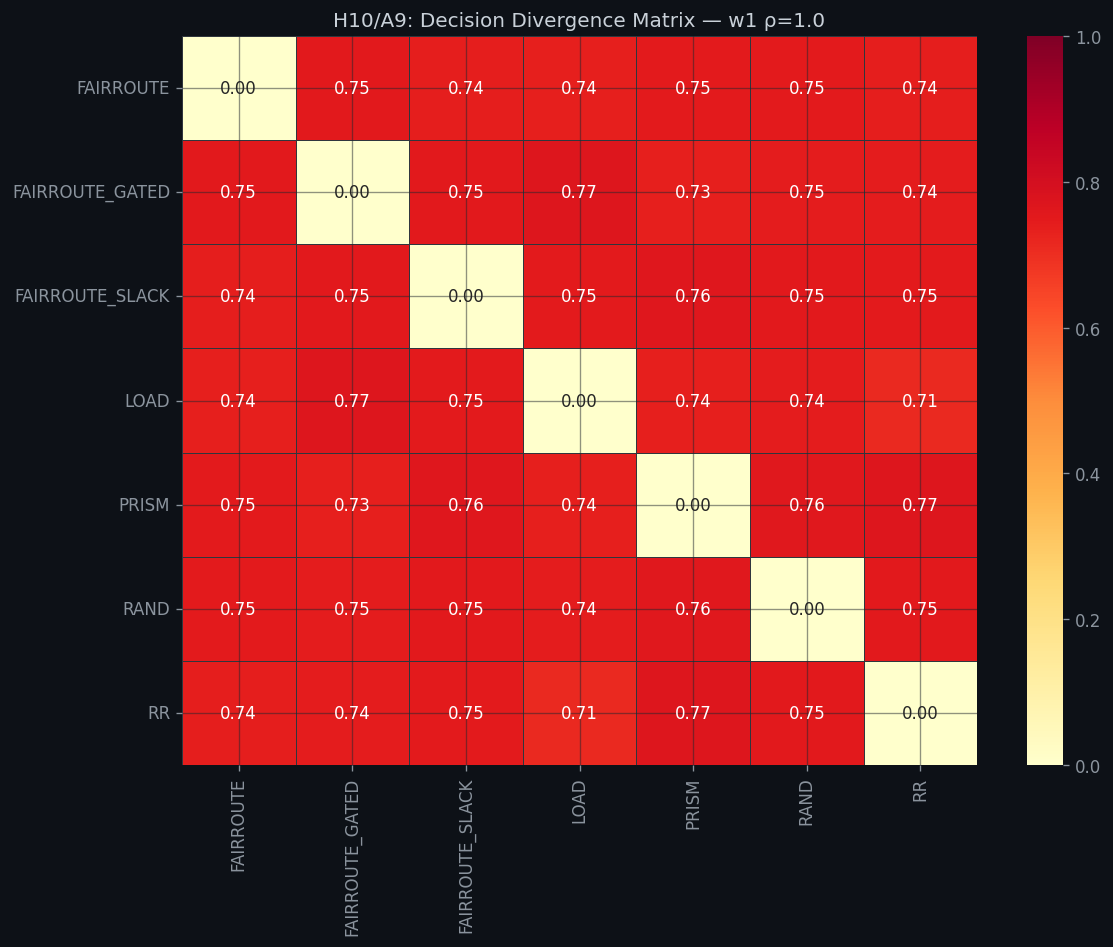

In [7]:
# ─── A9/A10: Decision divergence matrix ───
def compute_divergence_matrix(df, workload, rho, seed=None):
    """Fraction of requests routed differently between each pair of policies."""
    filt = df[(df['workload'] == workload) & (df['rho'] == rho)]
    if seed is not None:
        filt = filt[filt['seed'] == seed]
    policies = sorted(filt['policy_name'].unique())
    # Build request_id -> instance mapping per policy
    route_maps = {}
    for pol in policies:
        sub = filt[filt['policy_name'] == pol].set_index('request id')['instance id']
        route_maps[pol] = sub
    matrix = pd.DataFrame(0.0, index=policies, columns=policies)
    for p1, p2 in combinations(policies, 2):
        common = route_maps[p1].index.intersection(route_maps[p2].index)
        if len(common) == 0:
            continue
        diff = (route_maps[p1].loc[common] != route_maps[p2].loc[common]).mean()
        matrix.loc[p1, p2] = diff
        matrix.loc[p2, p1] = diff
    return matrix

# Show for the first available workload at rho=1.0
for wl in sorted(requests_df['workload'].unique()):
    if 1.0 in requests_df[requests_df['workload'] == wl]['rho'].values:
        dm = compute_divergence_matrix(requests_df, wl, 1.0)
        if dm.shape[0] > 1:
            fig, ax = plt.subplots(figsize=(10, 8))
            sns.heatmap(dm, annot=True, fmt='.2f', cmap='YlOrRd', ax=ax, vmin=0, vmax=1,
                        linewidths=0.5, linecolor='#30363d')
            ax.set_title(f'H10/A9: Decision Divergence Matrix — {wl} ρ=1.0', fontsize=12)
            plt.tight_layout()
            plt.savefig(FIGURE_DIR / f'D1_divergence_{wl}_rho1.0.png', dpi=150)
            plt.show()
            break

## 2. Per-Run Summary Metrics (B, C, D, E, F)

In [8]:
# ─── Compute per-run summary ───
def compute_run_summary(df):
    """Compute all per-run metrics from the per-request DataFrame."""
    summaries = []
    for run_key, grp in df.groupby('run_key'):
        row = {
            'run_key': run_key,
            'workload': grp['workload'].iloc[0],
            'cell': grp['cell'].iloc[0],
            'K': grp['K'].iloc[0],
            'rho': grp['rho'].iloc[0],
            'seed': grp['seed'].iloc[0],
            'policy_name': grp['policy_name'].iloc[0],
            'local_policy_name': grp['local_policy_name'].iloc[0],
            'policy_label': grp['policy_label'].iloc[0],
            'n_requests': len(grp),
            'n_instances': grp['instance id'].nunique(),
        }

        # B1: TTFT percentiles
        for p, name in [(50, 'p50'), (90, 'p90'), (95, 'p95'), (99, 'p99'), (99.9, 'p999')]:
            row[f'TTFT_{name}_ms'] = np.percentile(grp['TTFT_ms'], p)
        row['TTFT_mean_ms'] = grp['TTFT_ms'].mean()

        # B2: TPOT percentiles
        for p, name in [(50, 'p50'), (90, 'p90'), (95, 'p95'), (99, 'p99')]:
            row[f'TPOT_{name}_ms'] = np.percentile(grp['TPOT_ms'], p)
        row['TPOT_mean_ms'] = grp['TPOT_ms'].mean()

        # B3: Pooled ITL
        all_itl = [v * NS_TO_MS for lst in grp['ITL_list'] for v in lst]
        if all_itl:
            row['ITL_p50_ms'] = np.percentile(all_itl, 50)
            row['ITL_p99_ms'] = np.percentile(all_itl, 99)
            row['ITL_p999_ms'] = np.percentile(all_itl, 99.9)
            row['ITL_median_ms'] = np.median(all_itl)
        else:
            row['ITL_p50_ms'] = row['ITL_p99_ms'] = row['ITL_p999_ms'] = row['ITL_median_ms'] = 0

        # B4: Stall rate
        median_gap = row['ITL_median_ms']
        if all_itl and median_gap > 0:
            row['stall_rate'] = sum(1 for g in all_itl if g > STALL_MULTIPLIER * median_gap) / len(all_itl)
        else:
            row['stall_rate'] = 0
        row['max_ITL_p99_ms'] = np.percentile(grp['max_ITL_ms'], 99) if len(grp) > 0 else 0

        # B5: E2E latency
        for p, name in [(50, 'p50'), (90, 'p90'), (95, 'p95'), (99, 'p99')]:
            row[f'E2E_{name}_ms'] = np.percentile(grp['latency_ms'], p)
        row['E2E_mean_ms'] = grp['latency_ms'].mean()

        # B6: Queuing delay
        row['queue_delay_mean_ms'] = grp['queuing_delay_ms'].mean()
        row['queue_delay_p99_ms'] = np.percentile(grp['queuing_delay_ms'], 99)
        row['queue_delay_gt_1s'] = (grp['queuing_delay_s'] > QUEUE_DELAY_THRESHOLD_S).mean()

        # B10: Normalized latency
        row['norm_latency_mean_ms'] = grp['norm_latency_ms'].mean()

        # B11: Tail ratios
        ttft_p50 = row['TTFT_p50_ms']
        row['TTFT_tail_ratio'] = row['TTFT_p99_ms'] / ttft_p50 if ttft_p50 > 0 else float('inf')
        e2e_p50 = row['E2E_p50_ms']
        row['E2E_tail_ratio'] = row['E2E_p99_ms'] / e2e_p50 if e2e_p50 > 0 else float('inf')

        # C1: Request throughput
        arrival_span = (grp['arrival'].max() - grp['arrival'].min()) * NS_TO_S
        makespan = (grp['end_time'].max() - grp['arrival'].min()) * NS_TO_S
        row['request_throughput'] = len(grp) / makespan if makespan > 0 else 0

        # C2: Output token throughput
        row['output_tok_throughput'] = grp['output'].sum() / makespan if makespan > 0 else 0

        # C3: Input token throughput
        row['input_tok_throughput'] = grp['input'].sum() / makespan if makespan > 0 else 0
        row['input_eff_tok_throughput'] = grp['input_eff'].sum() / makespan if makespan > 0 else 0

        # C4: Total token throughput
        row['total_tok_throughput'] = (grp['input'].sum() + grp['output'].sum()) / makespan if makespan > 0 else 0

        # C6: Makespan inflation
        row['makespan_s'] = makespan
        row['arrival_span_s'] = arrival_span
        row['makespan_inflation'] = makespan / arrival_span if arrival_span > 0 else float('inf')

        # E1: Requests per replica
        inst_counts = grp.groupby('instance id').size()
        n_inst = row['n_instances']
        row['replica_jain'] = (inst_counts.sum()**2) / (n_inst * (inst_counts**2).sum()) if n_inst > 0 else 1

        # E2: Cost-weighted service per replica
        inst_service = grp.groupby('instance id')['service_cost'].sum()
        row['busiest_replica_share'] = inst_service.max() / inst_service.sum() if inst_service.sum() > 0 else 0

        # E5: Max/min service ratio
        row['replica_max_min_ratio'] = inst_service.max() / inst_service.min() if inst_service.min() > 0 else float('inf')

        # E14: Per-replica P99 TTFT
        inst_ttft_p99 = grp.groupby('instance id')['TTFT_ms'].quantile(0.99)
        row['replica_ttft_p99_max'] = inst_ttft_p99.max()
        row['replica_ttft_p99_min'] = inst_ttft_p99.min()

        # F1: Token-weighted hit rate
        total_input = grp['input'].sum()
        row['hit_rate'] = grp['hit_tokens'].sum() / total_input if total_input > 0 else 0

        # F4: Prefill tokens avoided
        row['prefill_tokens_avoided'] = grp['hit_tokens'].sum()
        row['prefill_avoided_share'] = row['hit_rate']

        # E12: Preemptions
        row['total_preemptions'] = grp['num_preemptions'].sum()
        row['total_recompute_tokens'] = grp['recompute_tokens'].sum()

        # Routing diagnostics
        row['routing_decision_ns_p50'] = np.percentile(grp['routing decision ns'], 50)
        row['routing_decision_ns_p99'] = np.percentile(grp['routing decision ns'], 99)

        summaries.append(row)
    return pd.DataFrame(summaries)

summary = compute_run_summary(requests_df)
print(f'Computed summaries for {len(summary)} runs')
display(summary[['workload', 'rho', 'policy_name', 'TTFT_p99_ms', 'TPOT_p99_ms',
                  'output_tok_throughput', 'replica_jain', 'hit_rate']].head(20))

Computed summaries for 588 runs


,workload,rho,policy_name,TTFT_p99_ms,TPOT_p99_ms,output_tok_throughput,replica_jain,hit_rate
0,w1,0.5,FAIRROUTE,408.806601,14.325192,1035.192011,0.996834,0.000021
1,w1,0.5,FAIRROUTE,401.066279,14.325192,1035.191926,0.996834,0.000021
2,w1,0.5,FAIRROUTE,428.774563,14.337190,1035.100861,0.998785,0.000021
3,w1,0.5,FAIRROUTE_GATED,396.569506,14.385891,1034.717320,0.992670,0.000021
4,w1,0.5,FAIRROUTE_GATED,393.344726,14.402739,1035.166547,0.993854,0.000021
5,w1,0.5,FAIRROUTE_GATED,393.344726,14.402739,1035.166547,0.993854,0.000021
6,w1,0.5,FAIRROUTE_SLACK,392.022767,14.120613,1034.658525,0.999736,0.000000
7,w1,0.5,FAIRROUTE_SLACK,392.028357,14.411050,1035.147393,0.999496,0.000021
8,w1,0.5,FAIRROUTE_SLACK,392.028357,14.411050,1035.147393,0.999496,0.000021
9,w1,0.5,LOAD,392.557069,14.335600,1034.715194,0.998578,0.000021


In [9]:
# ─── D: Client Fairness Metrics ───
def compute_client_fairness(df):
    """Compute per-run client fairness metrics."""
    fairness_rows = []
    for run_key, grp in df.groupby('run_key'):
        meta = grp[['workload', 'cell', 'K', 'rho', 'seed', 'policy_name', 'local_policy_name', 'policy_label']].iloc[0].to_dict()
        meta['run_key'] = run_key

        client_stats = grp.groupby('client id').agg(
            n_requests=('request id', 'size'),
            total_cost=('service_cost', 'sum'),
            mean_latency_ms=('latency_ms', 'mean'),
            p95_ttft_ms=('TTFT_ms', lambda x: np.percentile(x, 95)),
            p99_ttft_ms=('TTFT_ms', lambda x: np.percentile(x, 99) if len(x) >= 100 else np.percentile(x, 95)),
            mean_queue_delay_ms=('queuing_delay_ms', 'mean'),
            p99_queue_delay_ms=('queuing_delay_ms', lambda x: np.percentile(x, 99) if len(x) >= 100 else np.percentile(x, 95)),
            total_input=('input', 'sum'),
            total_output=('output', 'sum'),
        ).reset_index()

        total_cost = client_stats['total_cost'].sum()
        client_stats['demand_share'] = client_stats['total_cost'] / total_cost if total_cost > 0 else 0
        client_stats['service_share'] = client_stats['n_requests'] / client_stats['n_requests'].sum()
        n_clients = len(client_stats)

        # D3: Satisfaction ratio (requests completed / requests submitted)
        # All requests complete in the simulator, so satisfaction = 1.0 for all
        # But service rate may differ, so use cost-based
        ideal_share = 1.0 / n_clients
        client_stats['satisfaction'] = client_stats['service_share'] / ideal_share

        # D4: Jain over satisfaction
        x = client_stats['satisfaction'].values
        jain_satisfaction = (x.sum()**2) / (n_clients * (x**2).sum()) if n_clients > 0 and (x**2).sum() > 0 else 1
        meta['D4_jain_satisfaction'] = jain_satisfaction

        # D6: Jain over latency (inverse mean latency)
        inv_lat = 1.0 / client_stats['mean_latency_ms'].clip(lower=1e-6).values
        meta['D6_jain_latency'] = (inv_lat.sum()**2) / (n_clients * (inv_lat**2).sum()) if n_clients > 0 else 1

        # D6 alt: Jain over inverse queuing delay
        inv_q = 1.0 / client_stats['mean_queue_delay_ms'].clip(lower=1e-3).values
        meta['D6_jain_queue_delay'] = (inv_q.sum()**2) / (n_clients * (inv_q**2).sum()) if n_clients > 0 else 1

        # D7: Worst-client ratio
        ttft_values = client_stats['p95_ttft_ms'].values
        median_client = np.median(ttft_values)
        meta['D7_worst_client_ratio'] = ttft_values.max() / median_client if median_client > 0 else float('inf')

        # D8: Worst-decile ratio
        decile_idx = max(1, int(n_clients * 0.1))
        sorted_lat = np.sort(client_stats['mean_latency_ms'].values)[::-1]
        worst_decile = sorted_lat[:decile_idx].mean()
        median_val = np.median(sorted_lat)
        meta['D8_worst_decile_ratio'] = worst_decile / median_val if median_val > 0 else float('inf')

        # D11: Max/min service ratio
        costs = client_stats['total_cost'].values
        meta['D11_max_min_service'] = costs.max() / costs.min() if costs.min() > 0 else float('inf')

        # D14: Starvation
        queue_vals = client_stats['mean_queue_delay_ms'].values
        meta['D14_max_over_median_wait'] = queue_vals.max() / np.median(queue_vals) if np.median(queue_vals) > 0 else float('inf')
        all_q = grp['queuing_delay_ms'].values
        median_all_q = np.median(all_q)
        meta['D14_starvation_share'] = (all_q > STARVATION_MULTIPLIER * median_all_q).mean() if median_all_q > 0 else 0

        # D15: Gini of per-client service
        def gini(x):
            x = np.sort(x)
            n = len(x)
            if n == 0 or x.sum() == 0:
                return 0
            idx = np.arange(1, n + 1)
            return (2 * idx - n - 1).dot(x) / (n * x.sum())

        meta['D15_gini_service'] = gini(client_stats['total_cost'].values)
        meta['D15_gini_latency'] = gini(client_stats['mean_latency_ms'].values)

        fairness_rows.append(meta)
    return pd.DataFrame(fairness_rows)

fairness = compute_client_fairness(requests_df)
summary = summary.merge(fairness.drop(columns=['workload', 'cell', 'K', 'rho', 'seed', 'policy_name', 'local_policy_name', 'policy_label']),
                         on='run_key', how='left')
print(f'Added fairness metrics to summary. Columns: {[c for c in summary.columns if c.startswith("D")]}')

Added fairness metrics to summary. Columns: ['D4_jain_satisfaction', 'D6_jain_latency', 'D6_jain_queue_delay', 'D7_worst_client_ratio', 'D8_worst_decile_ratio', 'D11_max_min_service', 'D14_max_over_median_wait', 'D14_starvation_share', 'D15_gini_service', 'D15_gini_latency']


In [10]:
# ─── Load timeseries data ───
def load_all_timeseries(run_index):
    frames = []
    for _, row in run_index.iterrows():
        if row['ts_path'] is None or not os.path.exists(row['ts_path']):
            continue
        try:
            ts = pd.read_csv(row['ts_path'])
            ts['workload'] = row['workload']
            ts['cell'] = row['cell']
            ts['rho'] = row['rho']
            ts['policy_name'] = row['policy']
            ts['local_policy_name'] = row['local_policy']
            ts['policy_label'] = ts['policy_name'] + ' / ' + ts['local_policy_name']
            ts['run_key'] = f"{row['workload']}/{row['cell']}/{row['policy']}/{row['local_policy']}"
            frames.append(ts)
        except Exception as e:
            pass  # silently skip malformed timeseries
    if frames:
        return pd.concat(frames, ignore_index=True)
    return pd.DataFrame()

ts_df = load_all_timeseries(run_index)
print(f'Loaded {len(ts_df):,} timeseries rows from {ts_df["run_key"].nunique() if len(ts_df) > 0 else 0} runs')
if len(ts_df) > 0:
    print(f'Columns: {list(ts_df.columns)}')

Loaded 598,000 timeseries rows from 588 runs
Columns: ['timestamp_ns', 'timestamp_s', 'instance_id', 'running_reqs', 'waiting_reqs', 'npu_used_mb', 'npu_util_pct', 'kv_used_blocks', 'kv_num_blocks', 'kv_util_pct', 'prompt_th_toks_per_s', 'gen_th_toks_per_s', 'npu_prefix_requested_tokens', 'npu_prefix_hit_tokens', 'storage_prefix_requested_tokens', 'storage_prefix_hit_tokens', 'workload', 'cell', 'rho', 'policy_name', 'local_policy_name', 'policy_label', 'run_key']


In [11]:
# ─── E6-E13: Timeseries-based replica metrics ───
def compute_ts_metrics(ts_df, summary):
    if len(ts_df) == 0:
        print('⚠️ No timeseries data available for E6-E13 metrics')
        return summary
    ts_metrics = []
    for run_key, grp in ts_df.groupby('run_key'):
        row = {'run_key': run_key}
        # Per-interval: compute std across replicas
        per_interval = grp.groupby('timestamp_ns').agg(
            total_load=('running_reqs', 'sum'),
            mean_load=('running_reqs', 'mean'),
            std_load=('running_reqs', 'std'),
            max_running=('running_reqs', 'max'),
            std_kv=('kv_util_pct', 'std'),
            mean_kv=('kv_util_pct', 'mean'),
            max_kv=('kv_util_pct', 'max'),
        ).fillna(0)

        # E6: Queue imbalance
        waiting_std = grp.groupby('timestamp_ns')['waiting_reqs'].std().fillna(0)
        total_std = grp.groupby('timestamp_ns').apply(
            lambda x: (x['running_reqs'] + x['waiting_reqs']).std()
        ).fillna(0)
        row['E6_queue_imbalance_mean'] = total_std.mean()

        # E7: Hot-spot dwell time
        n_intervals = len(per_interval)
        if n_intervals > 0:
            hot_count = 0
            for ts, sub in grp.groupby('timestamp_ns'):
                mean_load = sub['running_reqs'].mean() + sub['waiting_reqs'].mean()
                max_load = (sub['running_reqs'] + sub['waiting_reqs']).max()
                if mean_load > 0 and max_load > HOT_SPOT_MULTIPLIER * mean_load:
                    hot_count += 1
            row['E7_hotspot_dwell'] = hot_count / n_intervals
        else:
            row['E7_hotspot_dwell'] = 0

        # E8: KV usage stats
        kv_by_inst = grp.groupby('instance_id')['kv_util_pct'].agg(['mean', 'max'])
        row['E8_kv_mean'] = float(kv_by_inst['mean'].mean()) if len(kv_by_inst) > 0 else 0
        row['E8_kv_max'] = float(kv_by_inst['max'].max()) if len(kv_by_inst) > 0 else 0
        kv_pcts = grp['kv_util_pct'].astype(float).values
        row['E8_kv_above_90'] = (kv_pcts > KV_HIGH_WATER * 100).mean() if len(kv_pcts) > 0 else 0

        # E9: KV imbalance
        row['E9_kv_imbalance'] = per_interval['std_kv'].mean()

        # E11: Waiting queue length
        wait_by_inst = grp.groupby('instance_id')['waiting_reqs'].agg(['mean', 'max'])
        row['E11_wait_mean'] = float(wait_by_inst['mean'].mean()) if len(wait_by_inst) > 0 else 0
        row['E11_wait_max'] = int(wait_by_inst['max'].max()) if len(wait_by_inst) > 0 else 0

        # E13: Activity proxy
        if len(grp) > 0:
            active = grp.groupby('instance_id').apply(lambda x: (x['running_reqs'] > 0).mean())
            row['E13_activity_min'] = active.min()
            row['E13_activity_mean'] = active.mean()
        else:
            row['E13_activity_min'] = row['E13_activity_mean'] = 0

        ts_metrics.append(row)

    ts_summary = pd.DataFrame(ts_metrics)
    summary = summary.merge(ts_summary, on='run_key', how='left')
    return summary

summary = compute_ts_metrics(ts_df, summary)
print(f'Summary now has {len(summary.columns)} columns')

Summary now has 79 columns


## 3. Isolated Latency Model (P5) & Slowdown (B9)

In [12]:
# ─── P5: Fit isolated latency from lowest-load RR run ───
min_rho = requests_df['rho'].min()
calibration = requests_df[
    (requests_df['policy_name'] == 'RR') & (requests_df['rho'] == min_rho)
].copy()

if len(calibration) > 0:
    # Use requests with near-zero queuing delay
    q_threshold = np.percentile(calibration['queuing_delay_ms'], 25)
    cal_low = calibration[calibration['queuing_delay_ms'] <= max(q_threshold, 1.0)]
    if len(cal_low) < 50:
        cal_low = calibration

    # Linear fit: TTFT_iso = a + b * input
    from numpy.polynomial import polynomial as P
    coeffs = np.polyfit(cal_low['input'], cal_low['TTFT_ms'], 1)
    ttft_iso_slope = coeffs[0]   # ms per input token
    ttft_iso_intercept = coeffs[1]

    # TPOT_iso = median TPOT
    tpot_iso = cal_low['TPOT_ms'].median()

    print(f'P5 Calibration from RR at ρ={min_rho}: {len(cal_low)} requests')
    print(f'  TTFT_iso(input) = {ttft_iso_slope:.3f} * input + {ttft_iso_intercept:.1f} ms')
    print(f'  TPOT_iso = {tpot_iso:.3f} ms')

    # Apply to all requests
    requests_df['T_iso_ttft'] = ttft_iso_slope * requests_df['input'] + ttft_iso_intercept
    requests_df['T_iso_e2e'] = requests_df['T_iso_ttft'] + (requests_df['output'] - 1).clip(lower=0) * tpot_iso
    requests_df['slowdown'] = requests_df['latency_ms'] / requests_df['T_iso_e2e'].clip(lower=1e-3)
    requests_df['ttft_slowdown'] = requests_df['TTFT_ms'] / requests_df['T_iso_ttft'].clip(lower=1e-3)

    HAS_SLOWDOWN = True
else:
    print('⚠️ No RR calibration run found. Slowdown metrics will be unavailable.')
    HAS_SLOWDOWN = False
    requests_df['slowdown'] = np.nan
    requests_df['ttft_slowdown'] = np.nan

P5 Calibration from RR at ρ=0.5: 3929 requests
  TTFT_iso(input) = 0.006 * input + 17.9 ms
  TPOT_iso = 11.248 ms


In [13]:
# ─── Add slowdown metrics to summary ───
if HAS_SLOWDOWN:
    slowdown_summary = requests_df.groupby('run_key').agg(
        slowdown_p50=('slowdown', lambda x: np.percentile(x, 50)),
        slowdown_p95=('slowdown', lambda x: np.percentile(x, 95)),
        slowdown_p99=('slowdown', lambda x: np.percentile(x, 99)),
        slowdown_mean=('slowdown', 'mean'),
        ttft_slowdown_p99=('ttft_slowdown', lambda x: np.percentile(x, 99)),
    ).reset_index()
    summary = summary.merge(slowdown_summary, on='run_key', how='left')

    # C8: SLO attainment
    for k in SLO_K_VALUES:
        col = f'slo_attain_k{k}'
        slo = requests_df.groupby('run_key').apply(
            lambda g: (g['TTFT_ms'] <= k * g['T_iso_ttft']).mean()
        ).reset_index(name=col)
        summary = summary.merge(slo, on='run_key', how='left')

    # C9: Goodput (SLO k=5)
    goodput = requests_df.groupby('run_key').apply(
        lambda g: g.loc[g['TTFT_ms'] <= 5 * g['T_iso_ttft'], 'output'].sum() /
                  ((g['end_time'].max() - g['arrival'].min()) * NS_TO_S)
        if (g['end_time'].max() - g['arrival'].min()) > 0 else 0
    ).reset_index(name='goodput_tok_s')
    summary = summary.merge(goodput, on='run_key', how='left')

    # D9: Group fairness (per-group P99 slowdown)
    for role_name in ['heavy', 'light', 'flooder', 'normal', 'short', 'long_prefill', 'long_decode']:
        role_sub = requests_df[requests_df['role'] == role_name]
        if len(role_sub) > 0:
            grp_metric = role_sub.groupby('run_key')['slowdown'].quantile(0.99).reset_index(name=f'D9_{role_name}_p99_slowdown')
            summary = summary.merge(grp_metric, on='run_key', how='left')

    print('Slowdown and SLO metrics added to summary.')

Slowdown and SLO metrics added to summary.


## 4. Cross-Run Comparison Metrics (I1–I8)

In [14]:
# ─── I1: Ratio to RR ───
rr_summary = summary[summary['policy_name'] == 'RR'][['workload', 'cell', 'rho', 'seed', 'local_policy_name',
    'TTFT_p99_ms', 'TPOT_p99_ms', 'E2E_p99_ms', 'output_tok_throughput', 'hit_rate']].copy()
rr_summary.columns = ['workload', 'cell', 'rho', 'seed', 'local_policy_name',
    'RR_TTFT_p99', 'RR_TPOT_p99', 'RR_E2E_p99', 'RR_throughput', 'RR_hit_rate']

summary = summary.merge(rr_summary, on=['workload', 'cell', 'rho', 'seed', 'local_policy_name'], how='left')

# Compute ratios
for metric, rr_col in [('TTFT_p99_ms', 'RR_TTFT_p99'), ('TPOT_p99_ms', 'RR_TPOT_p99'),
                         ('E2E_p99_ms', 'RR_E2E_p99')]:
    ratio_col = f'I1_{metric}_ratio_to_RR'
    summary[ratio_col] = summary[metric] / summary[rr_col].clip(lower=1e-6)

summary['I1_throughput_ratio_to_RR'] = summary['output_tok_throughput'] / summary['RR_throughput'].clip(lower=1e-6)

print('I1 ratio-to-RR metrics added.')

I1 ratio-to-RR metrics added.


In [15]:
# ─── I2: Paired per-request delta ───
def compute_paired_deltas(df, baseline='RR'):
    """For each (workload, cell, policy), compute log(latency_policy / latency_baseline) per request."""
    deltas = []
    for (wl, cell, local_policy), cell_grp in df.groupby(['workload', 'cell', 'local_policy_name']):
        bl = cell_grp[cell_grp['policy_name'] == baseline].set_index('request id')['latency_ms']
        if len(bl) == 0:
            continue
        for pol in cell_grp['policy_name'].unique():
            if pol == baseline:
                continue
            pol_data = cell_grp[cell_grp['policy_name'] == pol].set_index('request id')['latency_ms']
            common = bl.index.intersection(pol_data.index)
            if len(common) == 0:
                continue
            log_ratio = np.log(pol_data.loc[common].values / bl.loc[common].clip(lower=1e-6).values)
            deltas.append({
                'workload': wl, 'cell': cell, 'local_policy_name': local_policy, 'policy': pol,
                'mean_log_ratio': log_ratio.mean(),
                'p50_log_ratio': np.median(log_ratio),
                'share_improved': (log_ratio < 0).mean(),
                'n_paired': len(common),
            })
    return pd.DataFrame(deltas)

paired_deltas = compute_paired_deltas(requests_df)
if len(paired_deltas) > 0:
    print('I2 paired deltas computed:')
    display(paired_deltas.groupby('policy')[['share_improved', 'mean_log_ratio']].mean().sort_values('share_improved', ascending=False))

I2 paired deltas computed:


,share_improved,mean_log_ratio
policy,,
FAIRROUTE_SLACK,0.552766,-0.000136
FAIRROUTE_GATED,0.550020,0.006078
LOAD,0.542903,-0.031684
FAIRROUTE,0.467610,0.042222
D2LPM,0.435332,0.021388
RAND,0.428810,0.065212
PRISM,0.420666,-0.005473


In [16]:
# ─── I4: Rank per metric per cell ───
rank_metrics = {
    'TTFT_p99_ms': True,       # lower is better -> ascending
    'TPOT_p99_ms': True,
    'E2E_p99_ms': True,
    'output_tok_throughput': False,  # higher is better
    'hit_rate': False,
    'replica_jain': False,
}
if HAS_SLOWDOWN:
    rank_metrics['slowdown_p99'] = True
    rank_metrics['goodput_tok_s'] = False
if 'D6_jain_latency' in summary.columns:
    rank_metrics['D6_jain_latency'] = False

def compute_ranks(summary, metrics):
    rank_frames = []
    for (wl, rho), grp in summary.groupby(['workload', 'rho']):
        for metric, ascending in metrics.items():
            if metric not in grp.columns:
                continue
            ranked = grp[['policy_name', metric]].dropna(subset=[metric])
            ranked['rank'] = ranked[metric].rank(ascending=ascending, method='min')
            for _, r in ranked.iterrows():
                rank_frames.append({
                    'workload': wl, 'rho': rho, 'policy': r['policy_name'],
                    'metric': metric, 'rank': r['rank'], 'value': r[metric],
                })
    return pd.DataFrame(rank_frames)

ranks = compute_ranks(summary, rank_metrics)
if len(ranks) > 0:
    mean_ranks = ranks.groupby('policy')['rank'].mean().sort_values()
    print('I4 Mean rank across all (workload, ρ) cells:')
    display(mean_ranks)

I4 Mean rank across all (workload, ρ) cells:


policy
LOAD                8.917037
FAIRROUTE_SLACK    10.035556
RR                 10.091852
FAIRROUTE          11.312593
FAIRROUTE_GATED    12.339259
PRISM              12.880000
RAND               13.842963
D2LPM              13.941799
Name: rank, dtype: float64

## 5. Headline Distinction Charts (Section 3.1)

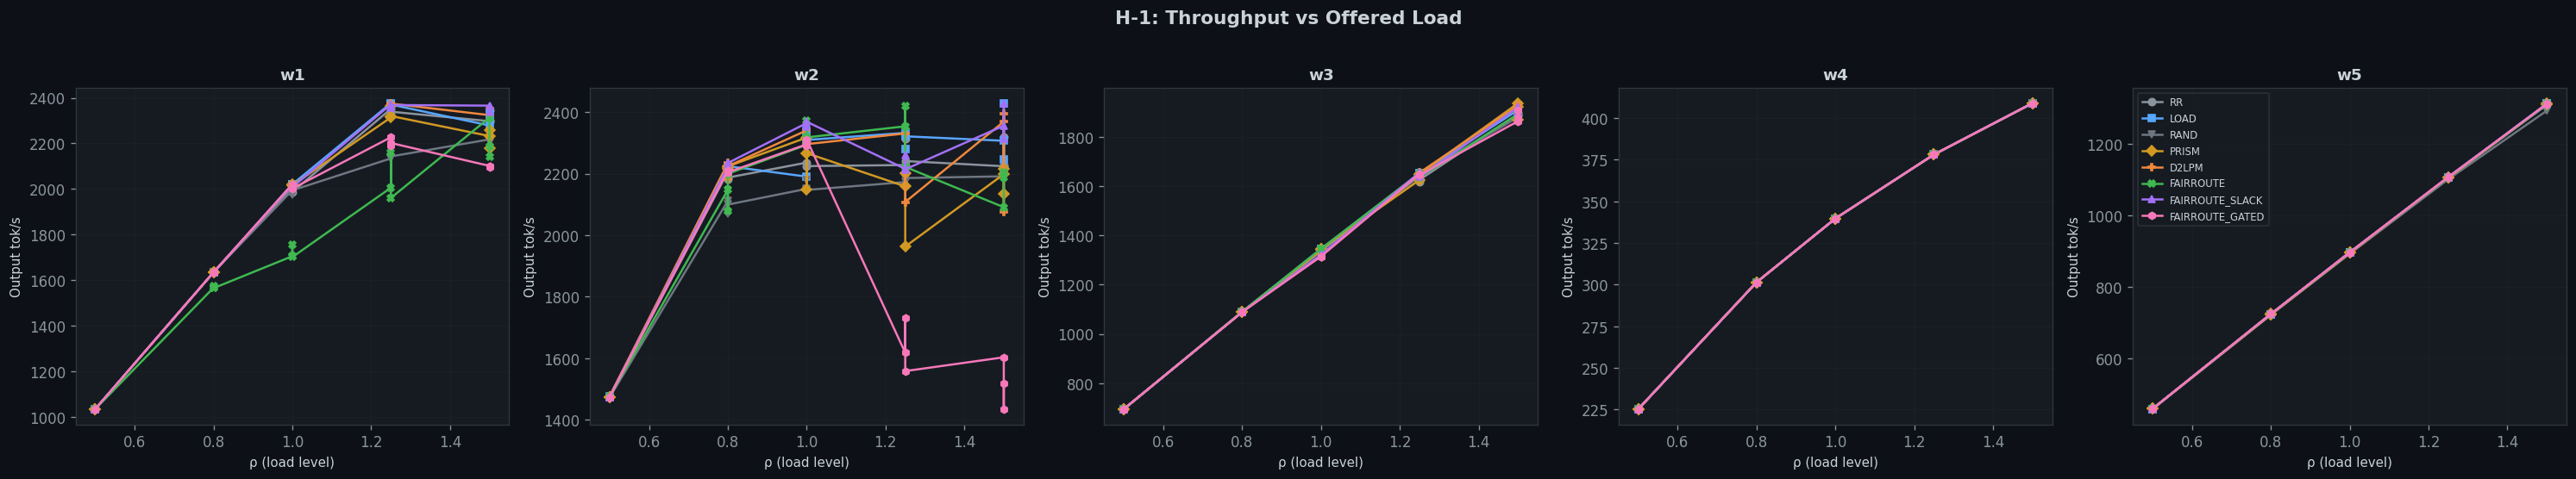

In [17]:
# ─── H-1: Throughput vs offered load ───
available_policies = [p for p in CORE_POLICIES if p in summary['policy_name'].unique()]
workloads = sorted(summary['workload'].unique())
n_wl = len(workloads)

if n_wl > 0:
    fig, axes = plt.subplots(1, n_wl, figsize=(5 * n_wl, 4.5), squeeze=False)
    for i, wl in enumerate(workloads):
        ax = axes[0, i]
        wl_data = summary[summary['workload'] == wl]
        for pol in available_policies:
            pol_data = wl_data[wl_data['policy_name'] == pol].sort_values('rho')
            if len(pol_data) == 0:
                continue
            ax.plot(pol_data['rho'], pol_data['output_tok_throughput'],
                    marker=POLICY_MARKERS.get(pol, 'o'), color=POLICY_COLORS.get(pol, '#fff'),
                    label=pol, linewidth=1.5, markersize=5)
        ax.set_xlabel('ρ (load level)', fontsize=9)
        ax.set_ylabel('Output tok/s', fontsize=9)
        ax.set_title(f'{wl}', fontsize=11, fontweight='bold')
        if i == n_wl - 1:
            ax.legend(fontsize=7, loc='best', ncol=1)
    fig.suptitle('H-1: Throughput vs Offered Load', fontsize=13, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / 'H1_throughput_vs_rho.png', dpi=150)
    plt.show()

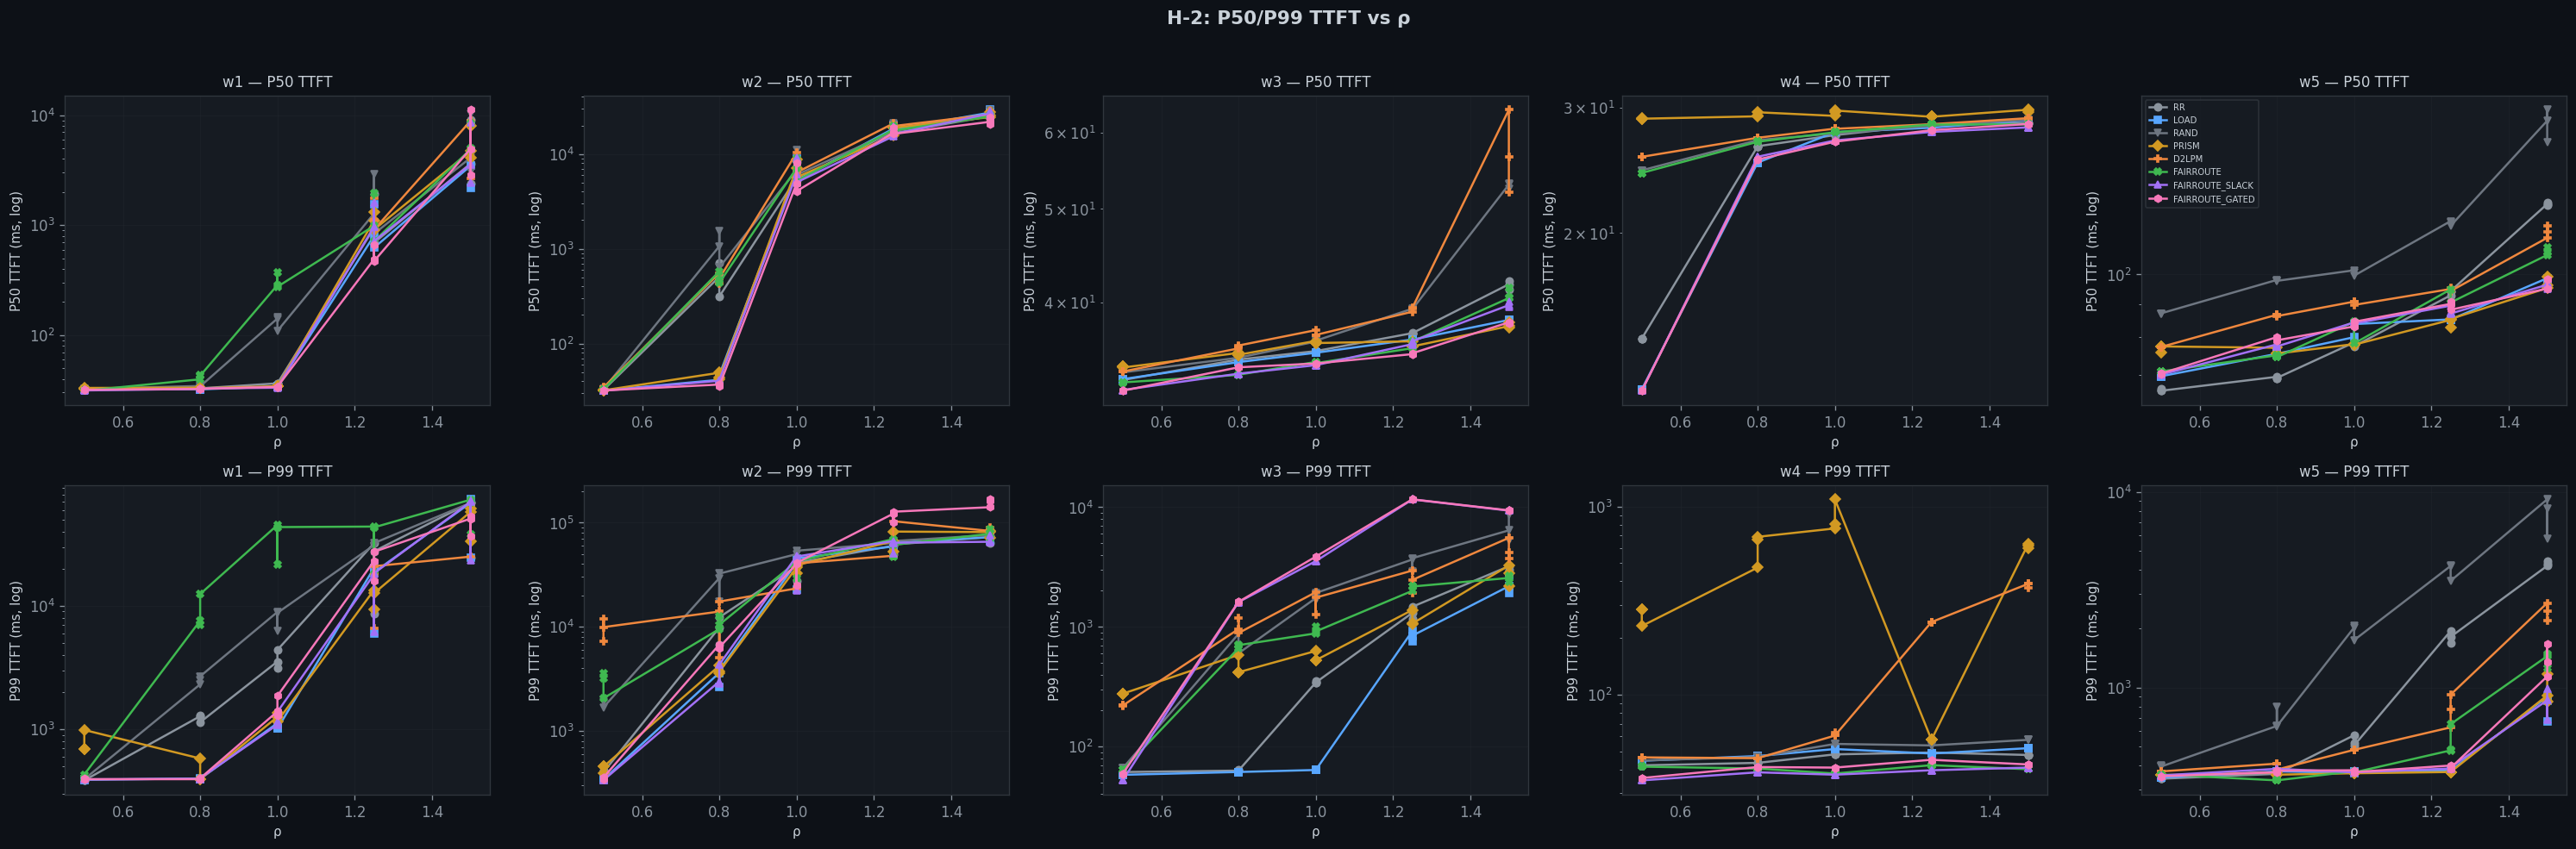

In [18]:
# ─── H-2: P99 TTFT vs ρ (and P50) ───
if n_wl > 0:
    fig, axes = plt.subplots(2, n_wl, figsize=(5 * n_wl, 8), squeeze=False)
    for col_idx, wl in enumerate(workloads):
        wl_data = summary[summary['workload'] == wl]
        for row_idx, (metric, title) in enumerate([('TTFT_p50_ms', 'P50 TTFT'), ('TTFT_p99_ms', 'P99 TTFT')]):
            ax = axes[row_idx, col_idx]
            for pol in available_policies:
                pol_data = wl_data[wl_data['policy_name'] == pol].sort_values('rho')
                if len(pol_data) == 0:
                    continue
                ax.plot(pol_data['rho'], pol_data[metric],
                        marker=POLICY_MARKERS.get(pol, 'o'), color=POLICY_COLORS.get(pol, '#fff'),
                        label=pol, linewidth=1.5, markersize=5)
            ax.set_yscale('log')
            ax.set_xlabel('ρ', fontsize=9)
            ax.set_ylabel(f'{title} (ms, log)', fontsize=9)
            ax.set_title(f'{wl} — {title}', fontsize=10)
            if col_idx == n_wl - 1 and row_idx == 0:
                ax.legend(fontsize=6, loc='best', ncol=1)
    fig.suptitle('H-2: P50/P99 TTFT vs ρ', fontsize=13, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / 'H2_ttft_vs_rho.png', dpi=150)
    plt.show()

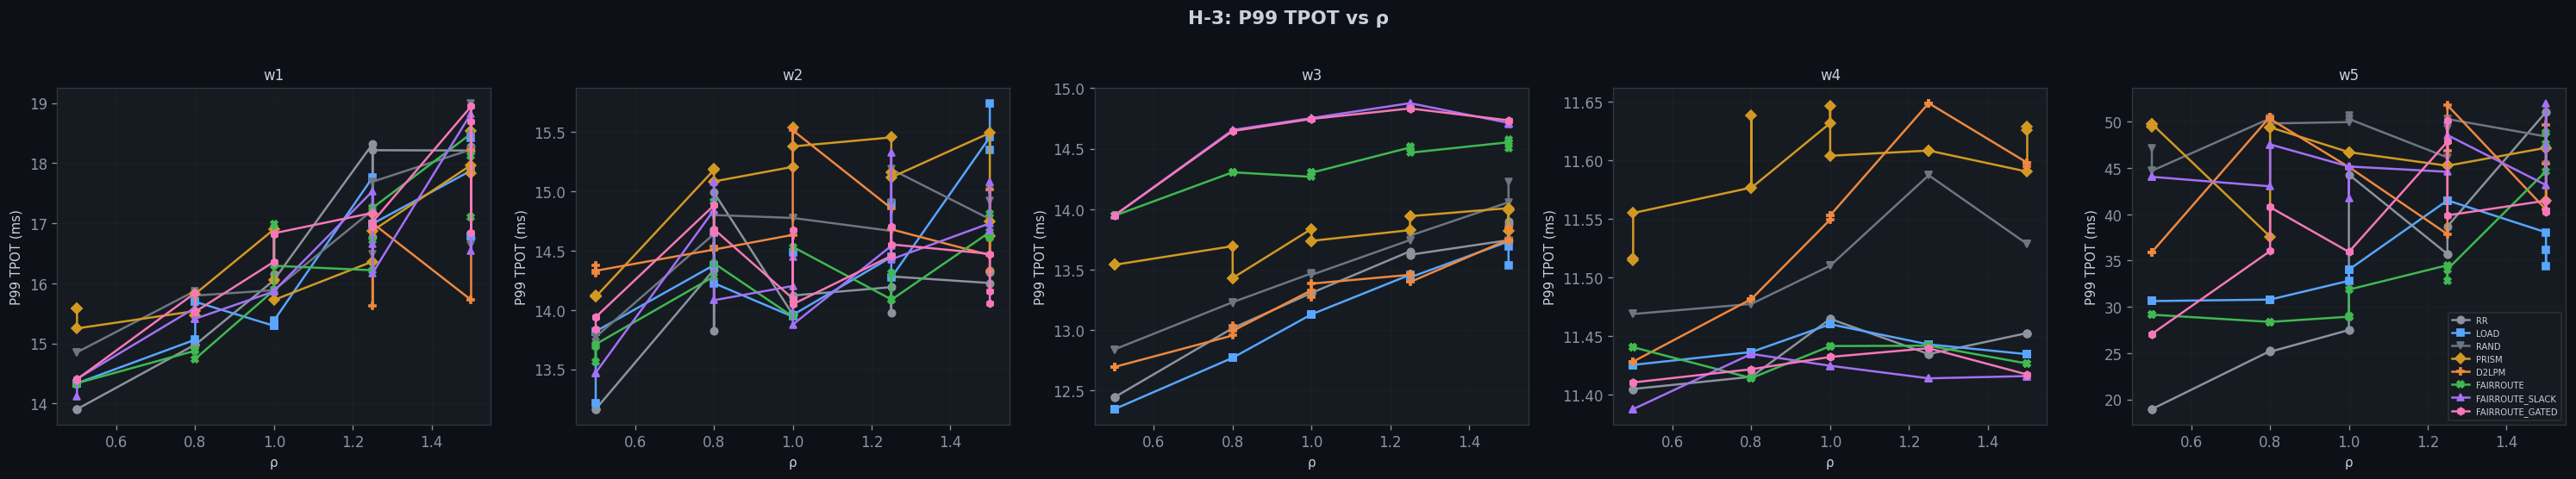

In [19]:
# ─── H-3: P99 TPOT/ITL vs ρ ───
if n_wl > 0:
    fig, axes = plt.subplots(1, n_wl, figsize=(5 * n_wl, 4.5), squeeze=False)
    for i, wl in enumerate(workloads):
        ax = axes[0, i]
        wl_data = summary[summary['workload'] == wl]
        for pol in available_policies:
            pol_data = wl_data[wl_data['policy_name'] == pol].sort_values('rho')
            if len(pol_data) == 0:
                continue
            ax.plot(pol_data['rho'], pol_data['TPOT_p99_ms'],
                    marker=POLICY_MARKERS.get(pol, 'o'), color=POLICY_COLORS.get(pol, '#fff'),
                    label=pol, linewidth=1.5, markersize=5)
        ax.set_xlabel('ρ', fontsize=9)
        ax.set_ylabel('P99 TPOT (ms)', fontsize=9)
        ax.set_title(f'{wl}', fontsize=10)
        if i == n_wl - 1:
            ax.legend(fontsize=6, loc='best')
    fig.suptitle('H-3: P99 TPOT vs ρ', fontsize=13, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / 'H3_tpot_vs_rho.png', dpi=150)
    plt.show()

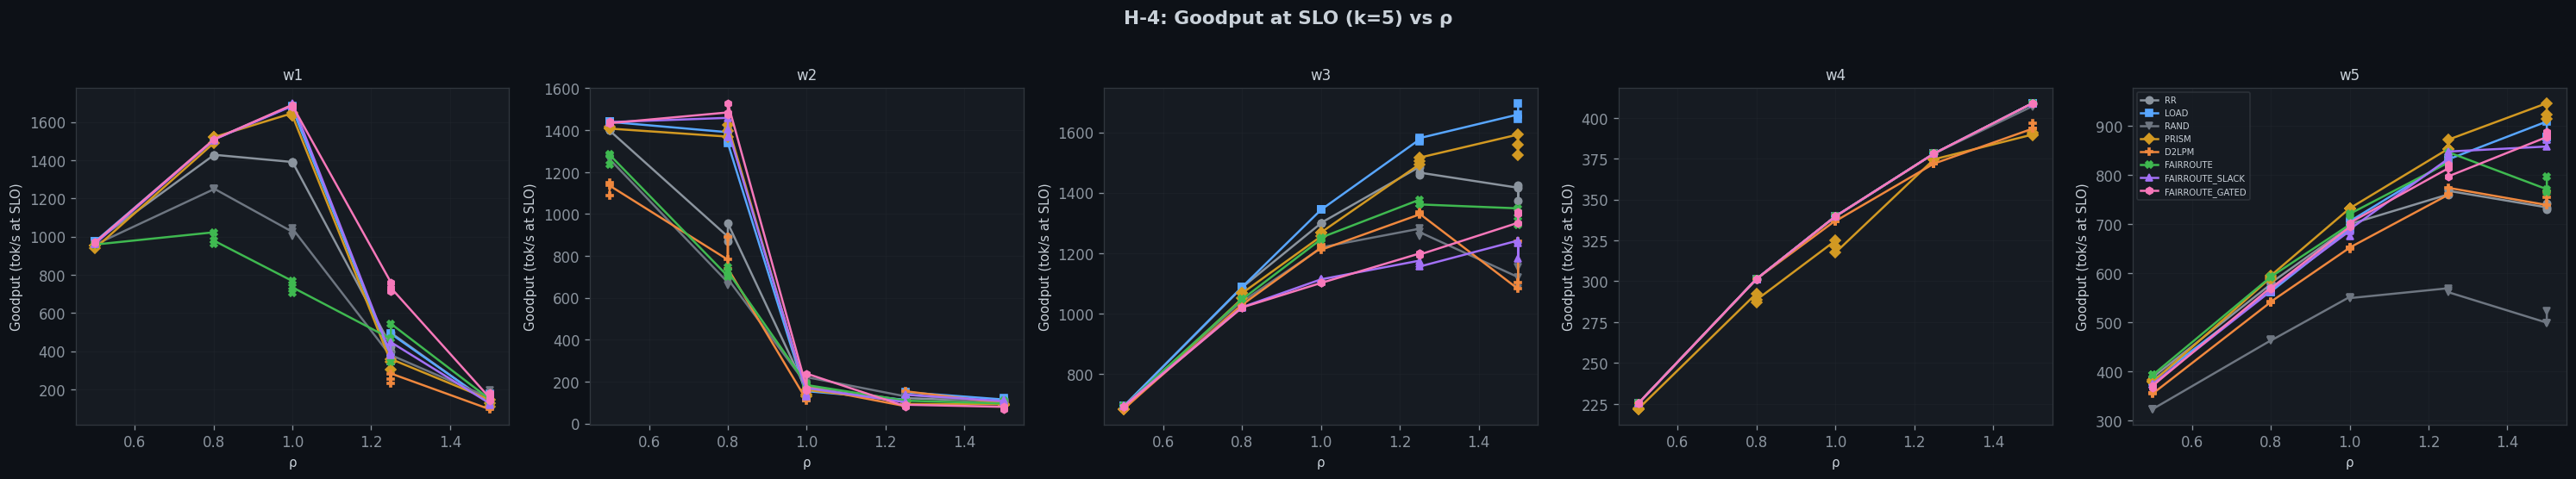

In [20]:
# ─── H-4: Goodput at SLO vs ρ ───
if HAS_SLOWDOWN and 'goodput_tok_s' in summary.columns and n_wl > 0:
    fig, axes = plt.subplots(1, n_wl, figsize=(5 * n_wl, 4.5), squeeze=False)
    for i, wl in enumerate(workloads):
        ax = axes[0, i]
        wl_data = summary[summary['workload'] == wl]
        for pol in available_policies:
            pol_data = wl_data[wl_data['policy_name'] == pol].sort_values('rho')
            if len(pol_data) == 0:
                continue
            ax.plot(pol_data['rho'], pol_data['goodput_tok_s'],
                    marker=POLICY_MARKERS.get(pol, 'o'), color=POLICY_COLORS.get(pol, '#fff'),
                    label=pol, linewidth=1.5, markersize=5)
        ax.set_xlabel('ρ', fontsize=9)
        ax.set_ylabel('Goodput (tok/s at SLO)', fontsize=9)
        ax.set_title(f'{wl}', fontsize=10)
        if i == n_wl - 1:
            ax.legend(fontsize=6, loc='best')
    fig.suptitle('H-4: Goodput at SLO (k=5) vs ρ', fontsize=13, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / 'H4_goodput_vs_rho.png', dpi=150)
    plt.show()
else:
    print('⚠️ Goodput not available (no slowdown calibration)')

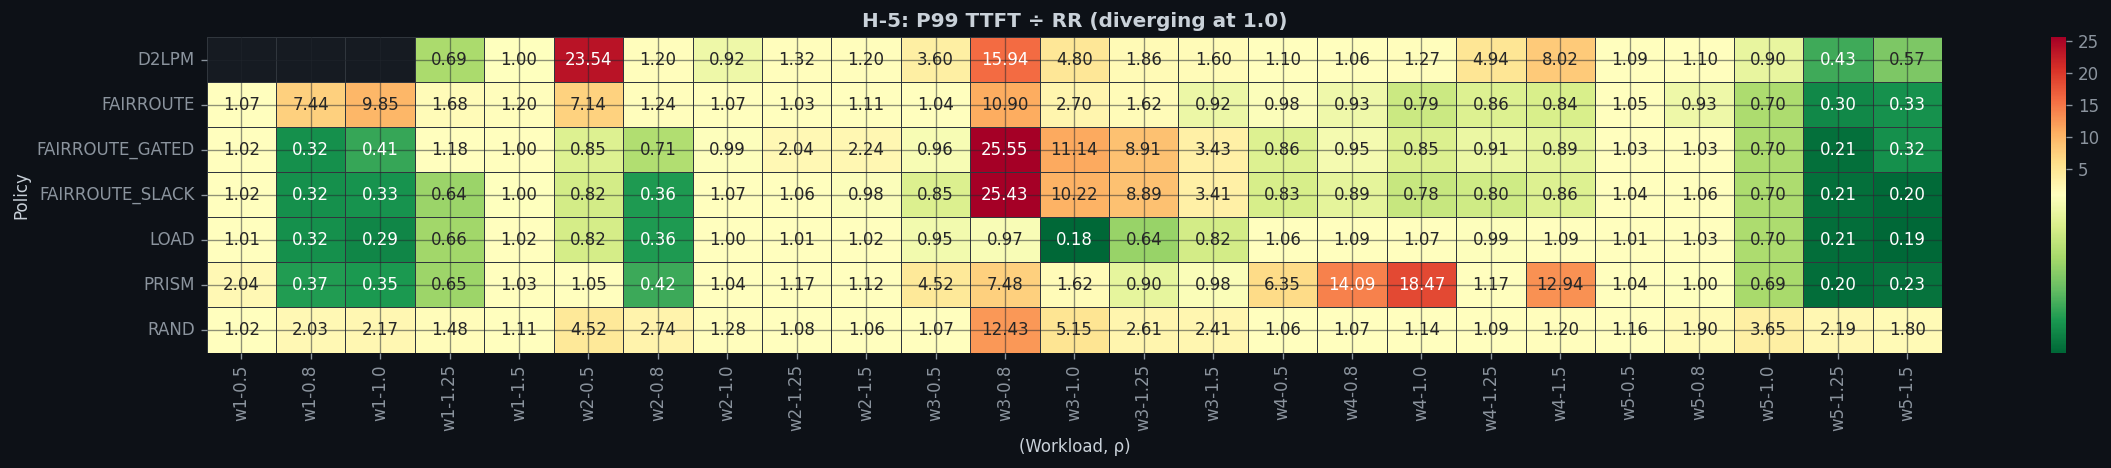

In [21]:
# ─── H-5: Ratio-to-RR heatmap ───
ratio_col = 'I1_TTFT_p99_ms_ratio_to_RR'
if ratio_col in summary.columns:
    pivot = summary[summary['policy_name'] != 'RR'].pivot_table(
        index='policy_name', columns=['workload', 'rho'],
        values=ratio_col, aggfunc='mean'
    )
    if pivot.shape[0] > 0 and pivot.shape[1] > 0:
        fig, ax = plt.subplots(figsize=(max(12, pivot.shape[1] * 0.8), max(4, pivot.shape[0] * 0.5)))
        norm = TwoSlopeNorm(vmin=pivot.min().min(), vcenter=1.0, vmax=max(pivot.max().max(), 1.5))
        sns.heatmap(pivot, annot=True, fmt='.2f', cmap='RdYlGn_r', norm=norm,
                    ax=ax, linewidths=0.5, linecolor='#30363d')
        ax.set_title('H-5: P99 TTFT ÷ RR (diverging at 1.0)', fontsize=12, fontweight='bold')
        ax.set_ylabel('Policy')
        ax.set_xlabel('(Workload, ρ)')
        plt.tight_layout()
        plt.savefig(FIGURE_DIR / 'H5_ratio_to_rr_heatmap.png', dpi=150)
        plt.show()

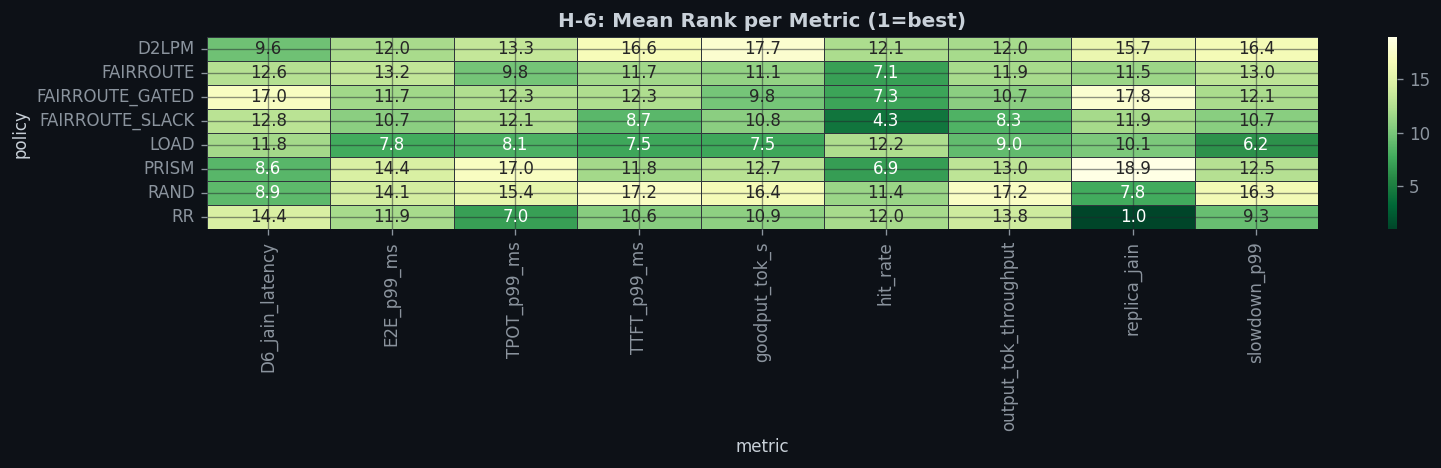

In [22]:
# ─── H-6: Mean-rank heatmap ───
if len(ranks) > 0:
    rank_pivot = ranks.pivot_table(index='policy', columns='metric', values='rank', aggfunc='mean')
    if rank_pivot.shape[0] > 0:
        fig, ax = plt.subplots(figsize=(max(10, rank_pivot.shape[1] * 1.5), max(4, rank_pivot.shape[0] * 0.5)))
        sns.heatmap(rank_pivot, annot=True, fmt='.1f', cmap='YlGn_r', ax=ax,
                    linewidths=0.5, linecolor='#30363d')
        ax.set_title('H-6: Mean Rank per Metric (1=best)', fontsize=12, fontweight='bold')
        plt.tight_layout()
        plt.savefig(FIGURE_DIR / 'H6_mean_rank_heatmap.png', dpi=150)
        plt.show()

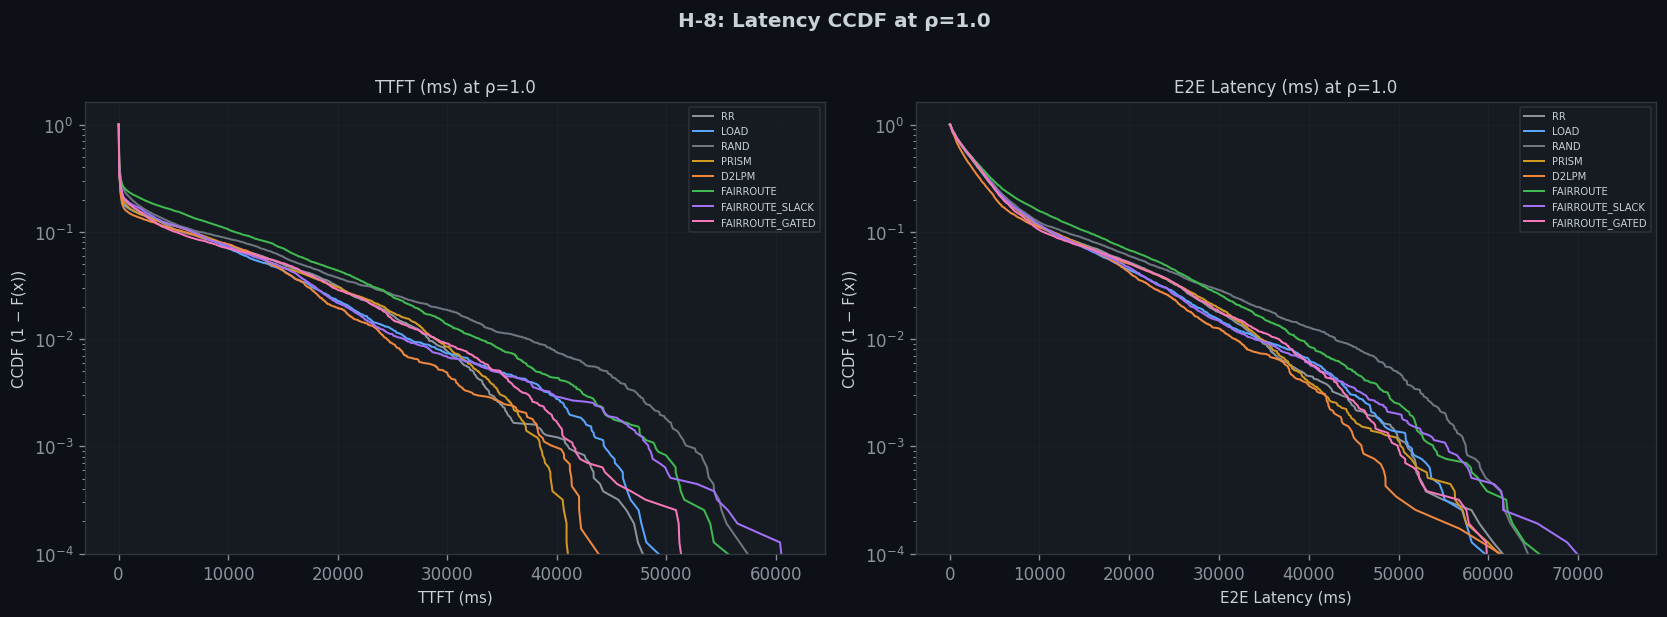

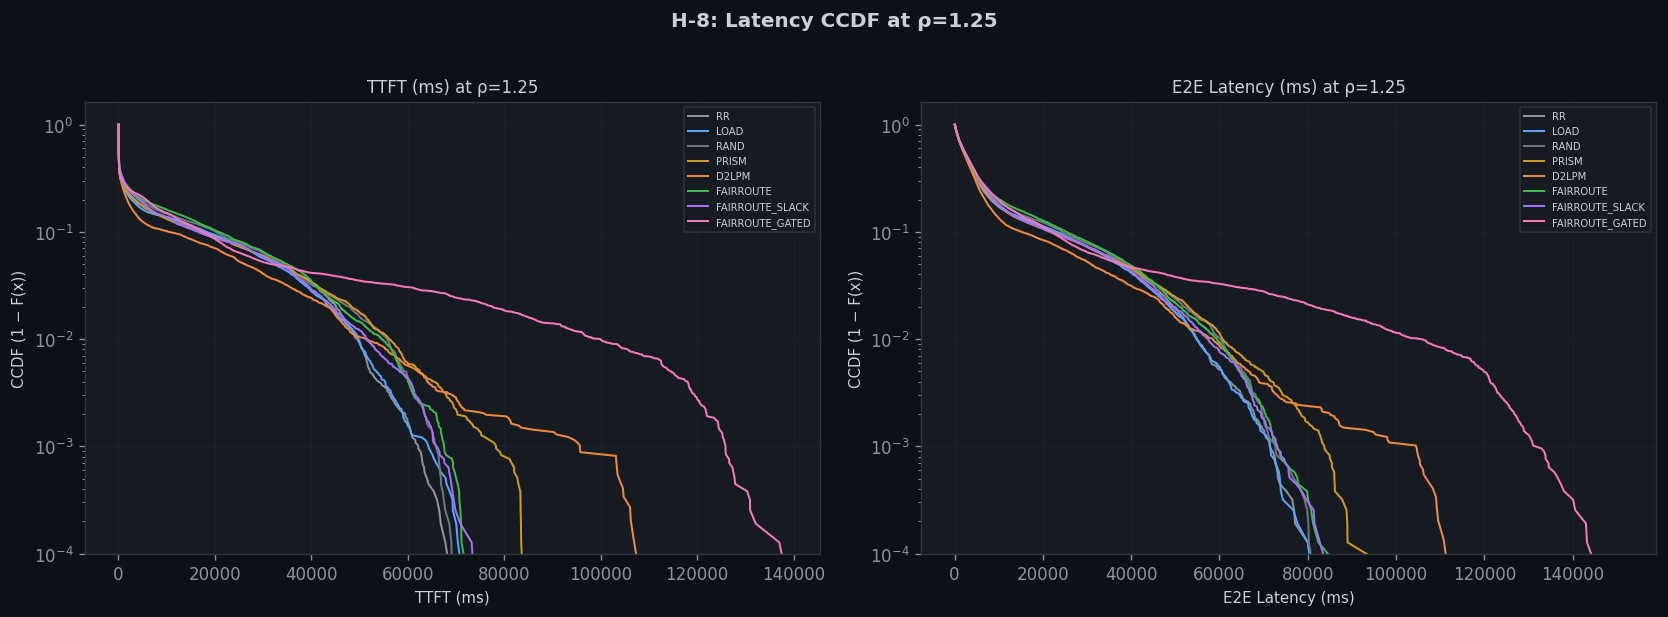

In [23]:
# ─── H-8: Latency CDF and CCDF ───
target_rhos = [r for r in [1.0, 1.25] if r in requests_df['rho'].unique()]
if target_rhos:
    for rho_val in target_rhos:
        fig, axes = plt.subplots(1, 2, figsize=(14, 5))
        for ax, metric, label in [(axes[0], 'TTFT_ms', 'TTFT (ms)'), (axes[1], 'latency_ms', 'E2E Latency (ms)')]:
            for pol in available_policies:
                data = requests_df[
                    (requests_df['policy_name'] == pol) & (requests_df['rho'] == rho_val)
                ][metric].dropna().sort_values()
                if len(data) == 0:
                    continue
                cdf = np.arange(1, len(data) + 1) / len(data)
                ax.plot(data.values, 1 - cdf, label=pol,
                        color=POLICY_COLORS.get(pol, '#fff'), linewidth=1.2)
            ax.set_yscale('log')
            ax.set_xlabel(label, fontsize=9)
            ax.set_ylabel('CCDF (1 − F(x))', fontsize=9)
            ax.set_title(f'{label} at ρ={rho_val}', fontsize=10)
            ax.legend(fontsize=6, loc='best')
            ax.set_ylim(bottom=1e-4)
        fig.suptitle(f'H-8: Latency CCDF at ρ={rho_val}', fontsize=12, fontweight='bold', y=1.02)
        plt.tight_layout()
        plt.savefig(FIGURE_DIR / f'H8_ccdf_rho{rho_val}.png', dpi=150)
        plt.show()

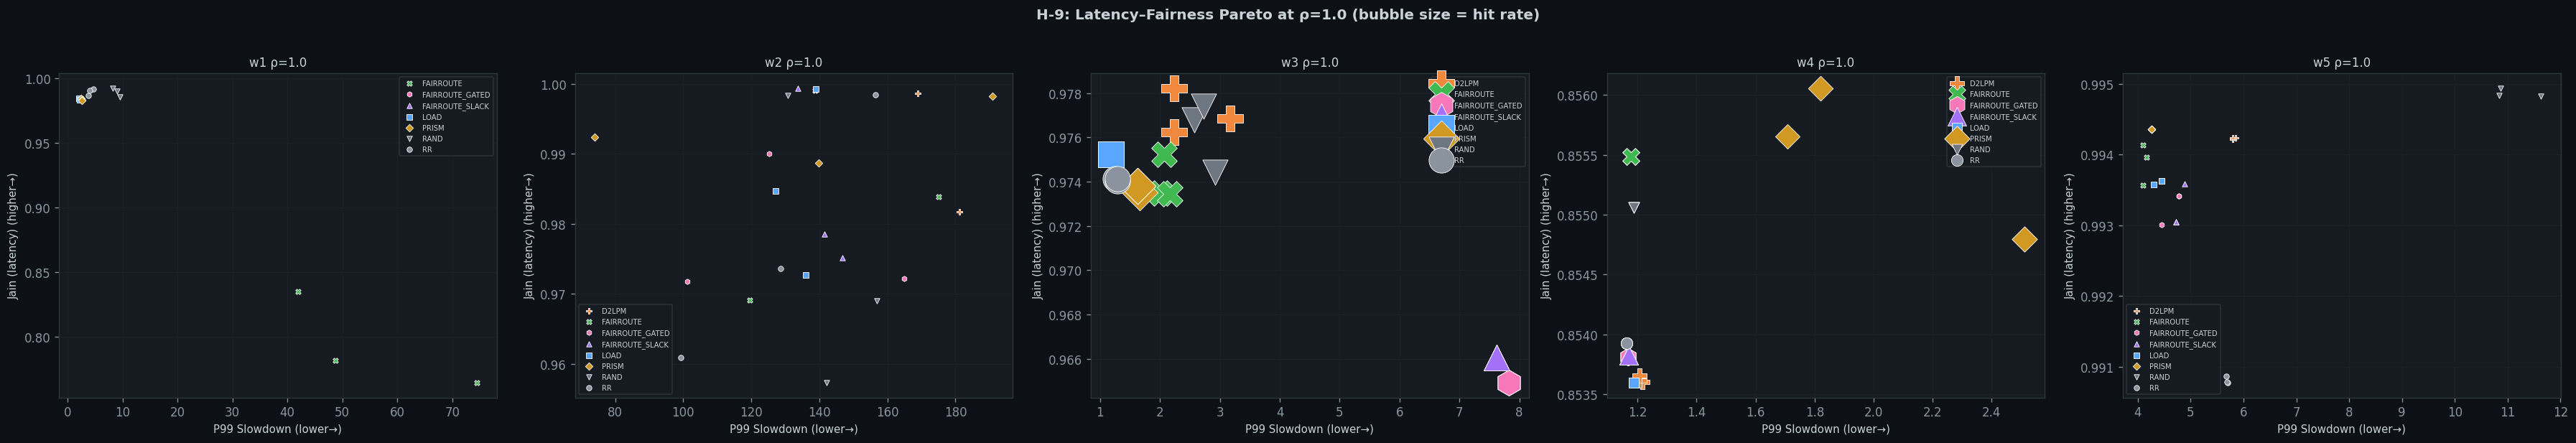

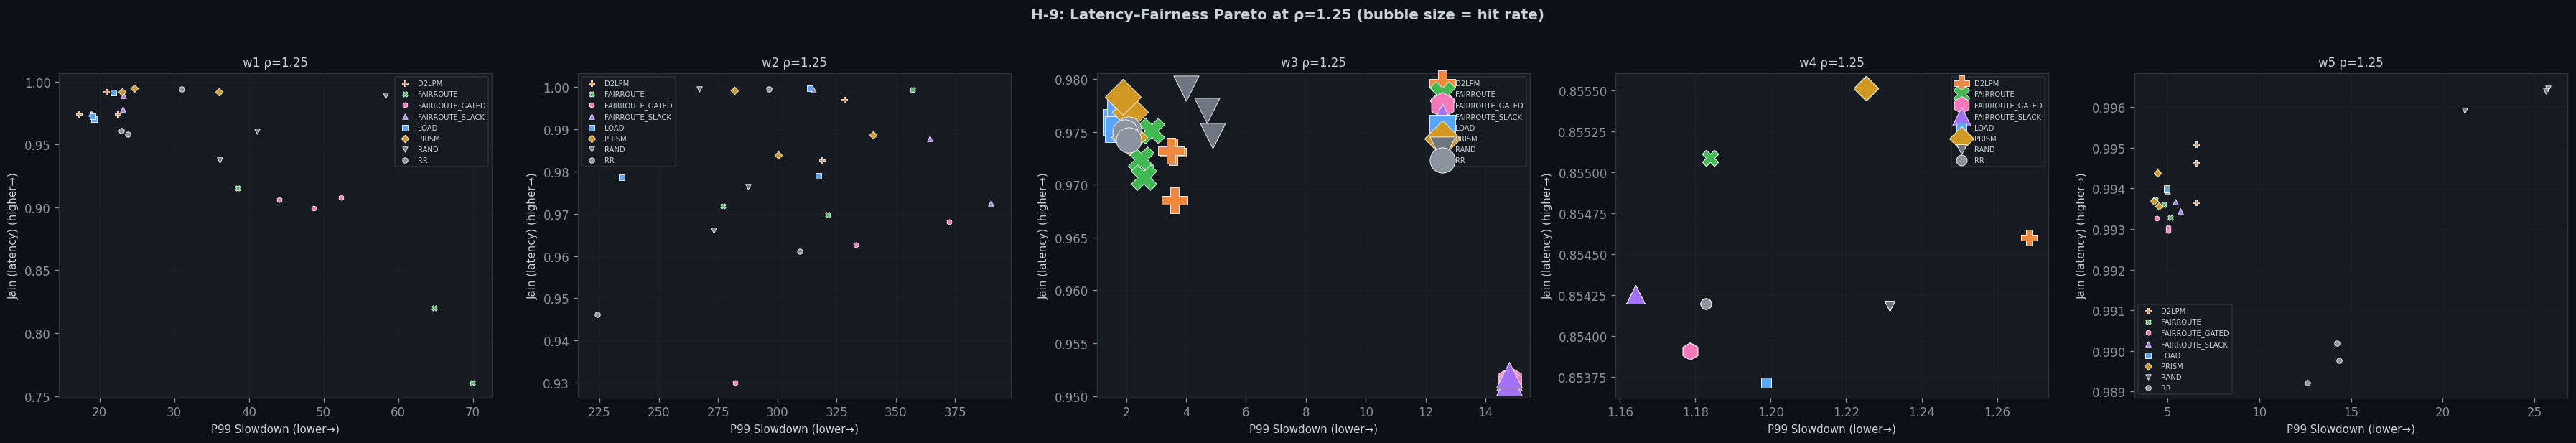

In [24]:
# ─── H-9: Latency-Fairness Pareto ───
if HAS_SLOWDOWN and 'D6_jain_latency' in summary.columns:
    for rho_val in target_rhos:
        sub = summary[(summary['rho'] == rho_val)].copy()
        if len(sub) == 0:
            continue
        wls = sorted(sub['workload'].unique())
        fig, axes = plt.subplots(1, len(wls), figsize=(6 * len(wls), 5), squeeze=False)
        for i, wl in enumerate(wls):
            ax = axes[0, i]
            wl_sub = sub[sub['workload'] == wl]
            for _, r in wl_sub.iterrows():
                pol = r['policy_name']
                ax.scatter(
                    r['slowdown_p99'], r['D6_jain_latency'],
                    s=max(20, r['hit_rate'] * 500),
                    color=POLICY_COLORS.get(pol, '#fff'),
                    marker=POLICY_MARKERS.get(pol, 'o'),
                    label=pol, edgecolors='white', linewidths=0.5, zorder=5,
                )
            ax.set_xlabel('P99 Slowdown (lower→)', fontsize=9)
            ax.set_ylabel('Jain (latency) (higher→)', fontsize=9)
            ax.set_title(f'{wl} ρ={rho_val}', fontsize=10)
            # Remove duplicate labels
            handles, labels = ax.get_legend_handles_labels()
            by_label = dict(zip(labels, handles))
            ax.legend(by_label.values(), by_label.keys(), fontsize=6, loc='best')
        fig.suptitle(f'H-9: Latency–Fairness Pareto at ρ={rho_val} (bubble size = hit rate)',
                     fontsize=12, fontweight='bold', y=1.02)
        plt.tight_layout()
        plt.savefig(FIGURE_DIR / f'H9_pareto_rho{rho_val}.png', dpi=150)
        plt.show()

## 6. Client Fairness Charts (Section 3.2)

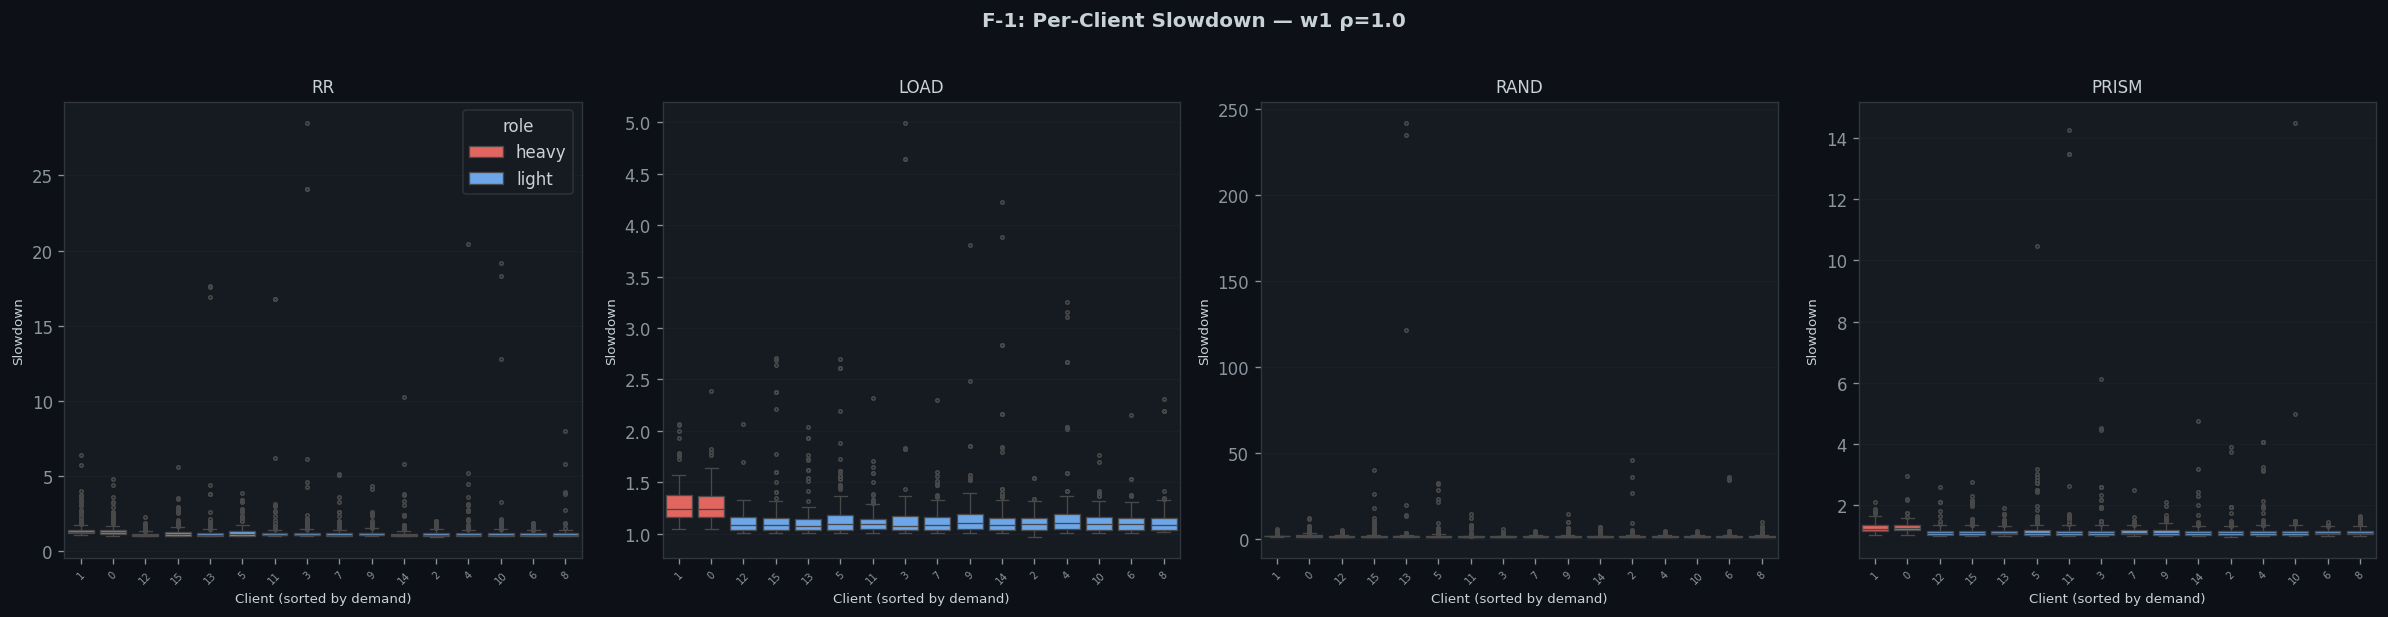

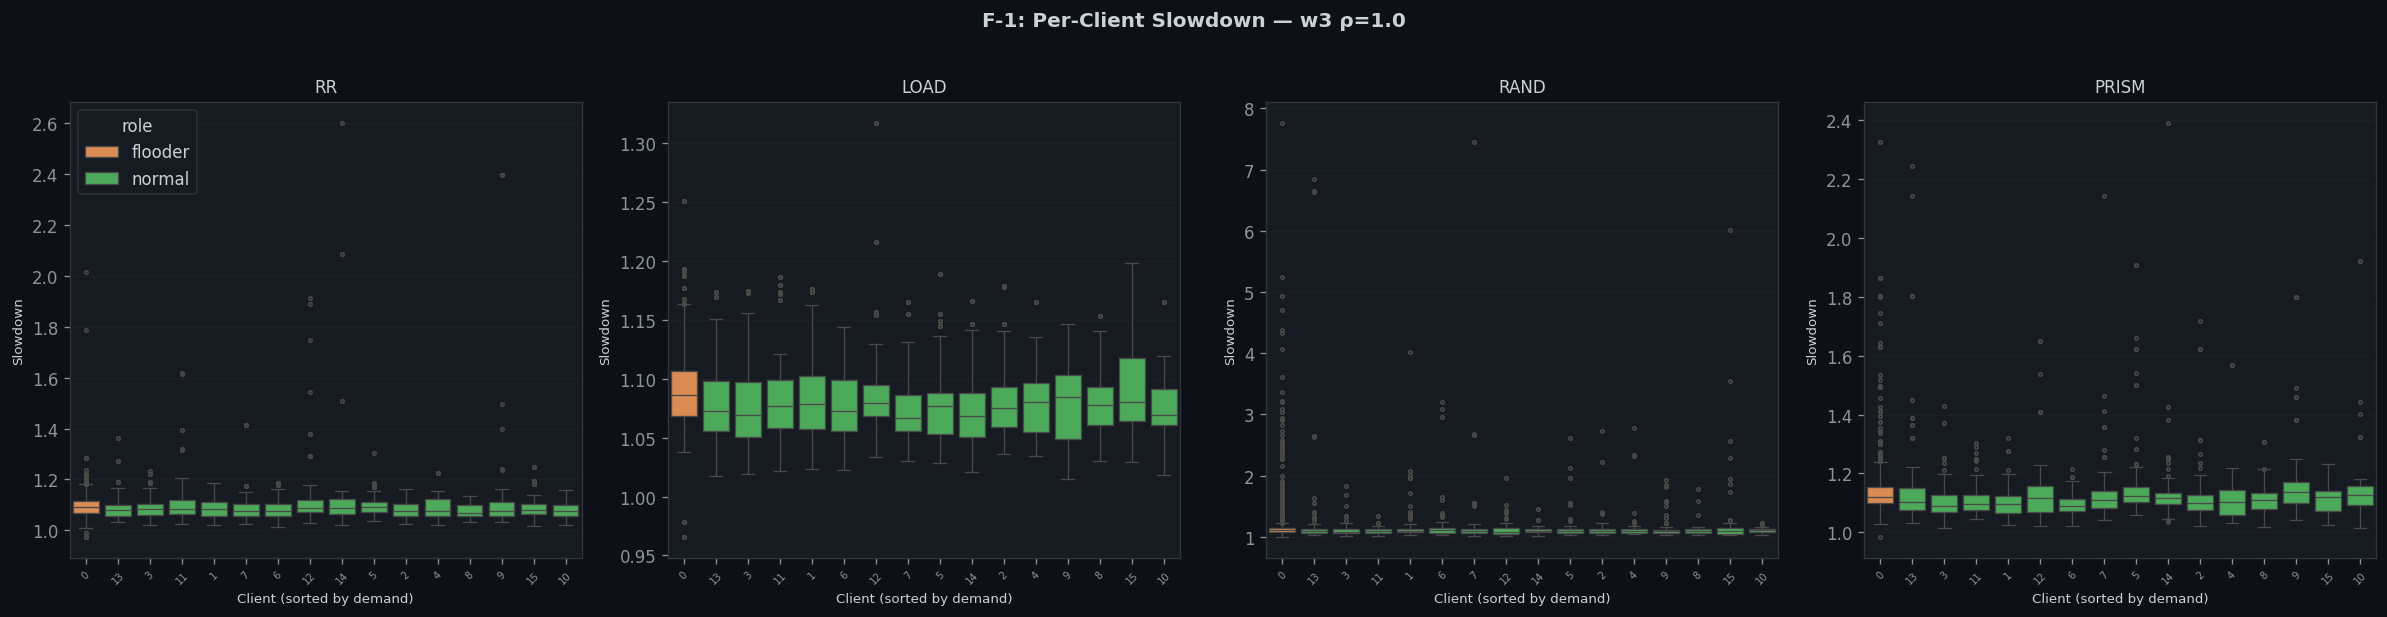

In [25]:
# ─── F-1: Per-client slowdown distributions ───
if HAS_SLOWDOWN:
    # Pick W1 at ρ=1.0 if available
    for wl in ['w1', 'w3']:
        for rho_val in [1.0, 0.8]:
            sub = requests_df[
                (requests_df['workload'] == wl) & (requests_df['rho'] == rho_val)
            ]
            if len(sub) == 0:
                continue
            policies_here = [p for p in available_policies if p in sub['policy_name'].unique()]
            if len(policies_here) == 0:
                continue
            n_pol = len(policies_here)
            fig, axes = plt.subplots(1, min(n_pol, 4), figsize=(5 * min(n_pol, 4), 5), squeeze=False)
            for j, pol in enumerate(policies_here[:4]):
                ax = axes[0, j]
                pol_data = sub[sub['policy_name'] == pol]
                client_order = pol_data.groupby('client id')['service_cost'].sum().sort_values(ascending=False).index
                plot_data = pol_data[pol_data['client id'].isin(client_order[:20])]
                # Color by role
                palette = {'heavy': '#f85149', 'light': '#58a6ff', 'flooder': '#f0883e',
                           'normal': '#3fb950', 'short': '#58a6ff', 'long_prefill': '#d29922',
                           'long_decode': '#bc8cff', 'unknown': '#8b949e'}
                sns.boxplot(data=plot_data, x='client id', y='slowdown', order=client_order[:20],
                            hue='role', palette=palette, ax=ax, fliersize=2, linewidth=0.8)
                ax.set_title(f'{pol}', fontsize=10)
                ax.set_xlabel('Client (sorted by demand)', fontsize=8)
                ax.set_ylabel('Slowdown', fontsize=8)
                ax.tick_params(axis='x', labelsize=6, rotation=45)
                if j > 0:
                    ax.get_legend().remove()
            fig.suptitle(f'F-1: Per-Client Slowdown — {wl} ρ={rho_val}', fontsize=12, fontweight='bold', y=1.02)
            plt.tight_layout()
            plt.savefig(FIGURE_DIR / f'F1_client_slowdown_{wl}_rho{rho_val}.png', dpi=150)
            plt.show()
            break  # show first available rho
else:
    print('⚠️ Slowdown not available for F-1')

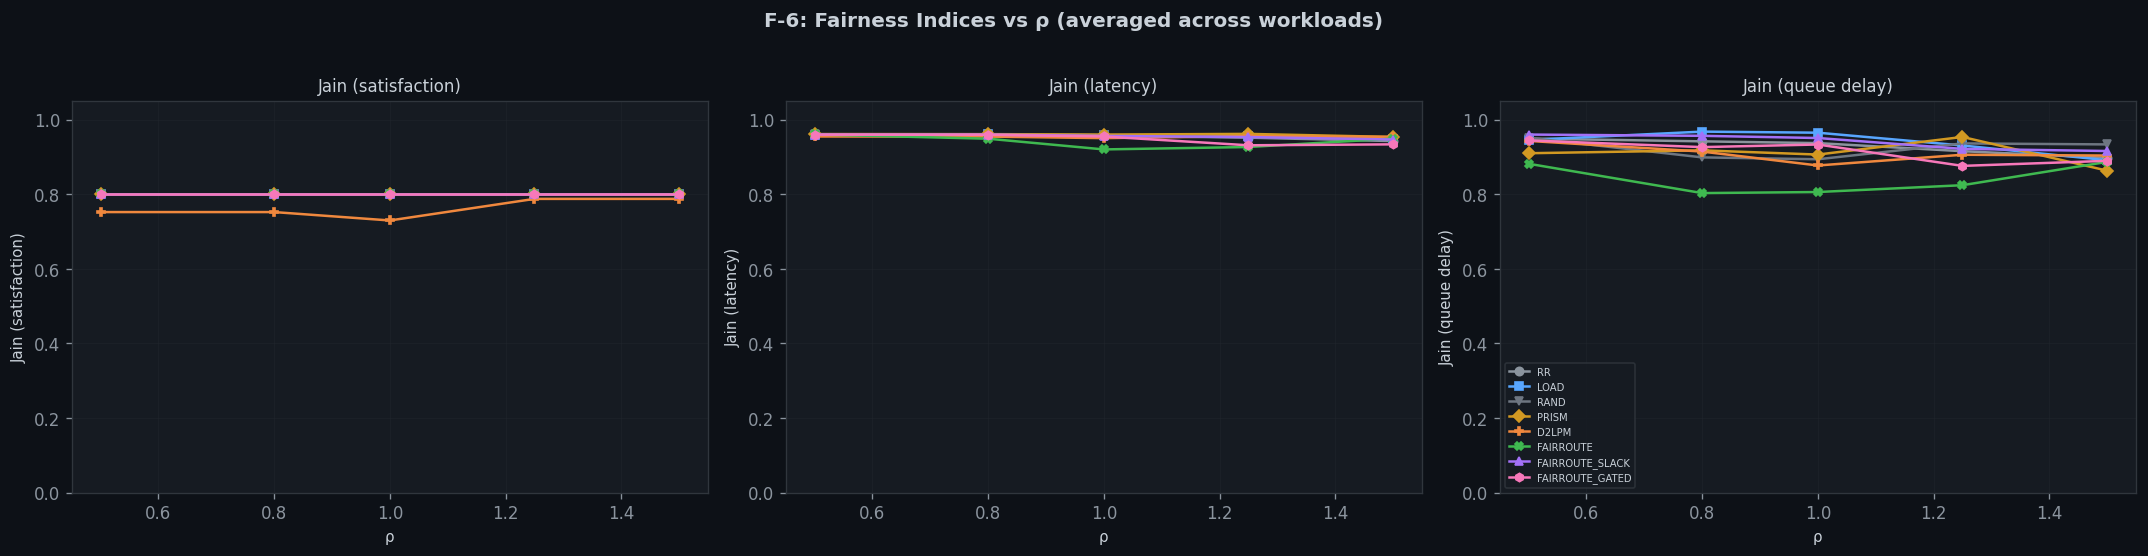

In [26]:
# ─── F-6: Jain indices vs ρ ───
jain_metrics = ['D4_jain_satisfaction', 'D6_jain_latency', 'D6_jain_queue_delay']
jain_labels = ['Jain (satisfaction)', 'Jain (latency)', 'Jain (queue delay)']
jain_available = [m for m in jain_metrics if m in summary.columns]

if jain_available:
    fig, axes = plt.subplots(1, len(jain_available), figsize=(6 * len(jain_available), 4.5), squeeze=False)
    for i, (metric, label) in enumerate(zip(jain_available, jain_labels)):
        ax = axes[0, i]
        for pol in available_policies:
            pol_data = summary[summary['policy_name'] == pol].sort_values('rho')
            # Average across workloads for this overview
            by_rho = pol_data.groupby('rho')[metric].mean().dropna()
            if len(by_rho) == 0:
                continue
            ax.plot(by_rho.index, by_rho.values,
                    marker=POLICY_MARKERS.get(pol, 'o'), color=POLICY_COLORS.get(pol, '#fff'),
                    label=pol, linewidth=1.5, markersize=5)
        ax.set_xlabel('ρ', fontsize=9)
        ax.set_ylabel(label, fontsize=9)
        ax.set_title(label, fontsize=10)
        ax.set_ylim(0, 1.05)
        if i == len(jain_available) - 1:
            ax.legend(fontsize=6, loc='best')
    fig.suptitle('F-6: Fairness Indices vs ρ (averaged across workloads)',
                 fontsize=12, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / 'F6_jain_vs_rho.png', dpi=150)
    plt.show()

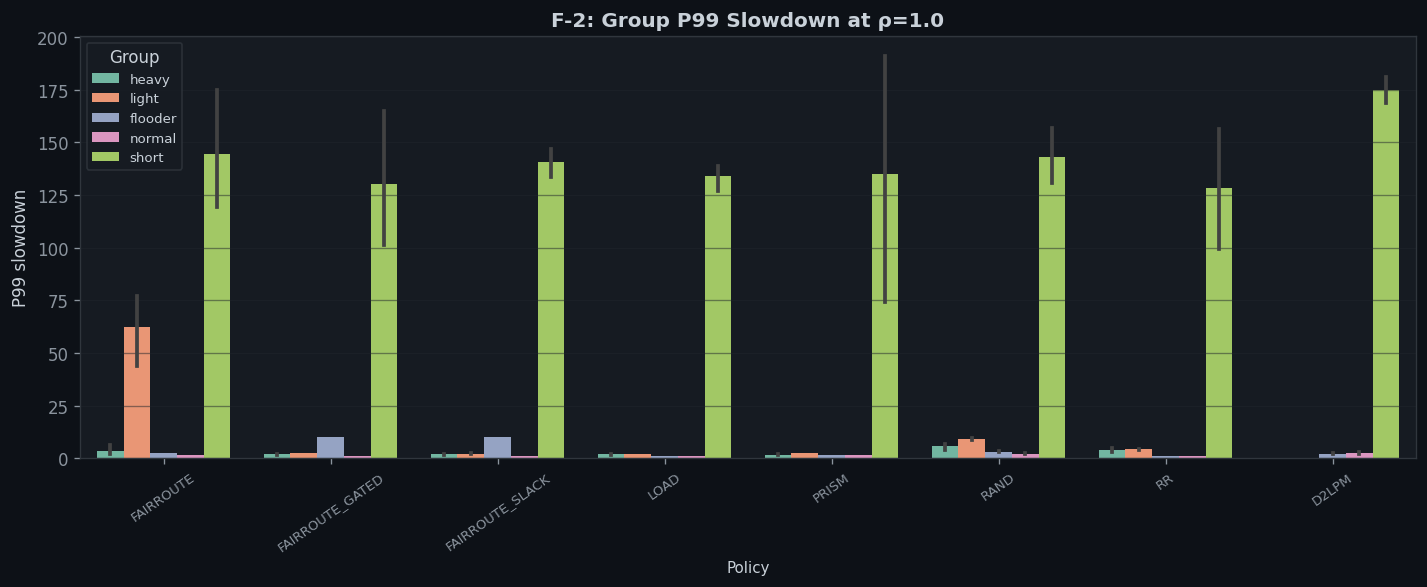

In [27]:
# ─── F-2: Group P99 slowdown ───
group_cols = [c for c in summary.columns if c.startswith('D9_') and c.endswith('_p99_slowdown')]
if group_cols and len(summary) > 0:
    for rho_val in [1.0, 0.8]:
        sub = summary[summary['rho'] == rho_val]
        if len(sub) == 0:
            continue
        # Melt for grouped bar chart
        melt_data = sub[['policy_name'] + group_cols].melt(
            id_vars='policy_name', var_name='group', value_name='P99 slowdown'
        ).dropna()
        melt_data['group'] = melt_data['group'].str.replace('D9_', '').str.replace('_p99_slowdown', '')
        if len(melt_data) > 0:
            fig, ax = plt.subplots(figsize=(12, 5))
            sns.barplot(data=melt_data, x='policy_name', y='P99 slowdown', hue='group',
                        ax=ax, palette='Set2')
            ax.set_title(f'F-2: Group P99 Slowdown at ρ={rho_val}', fontsize=12, fontweight='bold')
            ax.set_xlabel('Policy', fontsize=9)
            ax.tick_params(axis='x', rotation=35, labelsize=8)
            ax.legend(fontsize=8, title='Group')
            plt.tight_layout()
            plt.savefig(FIGURE_DIR / f'F2_group_slowdown_rho{rho_val}.png', dpi=150)
            plt.show()
            break

## 7. Replica Balance Charts (Section 3.3)

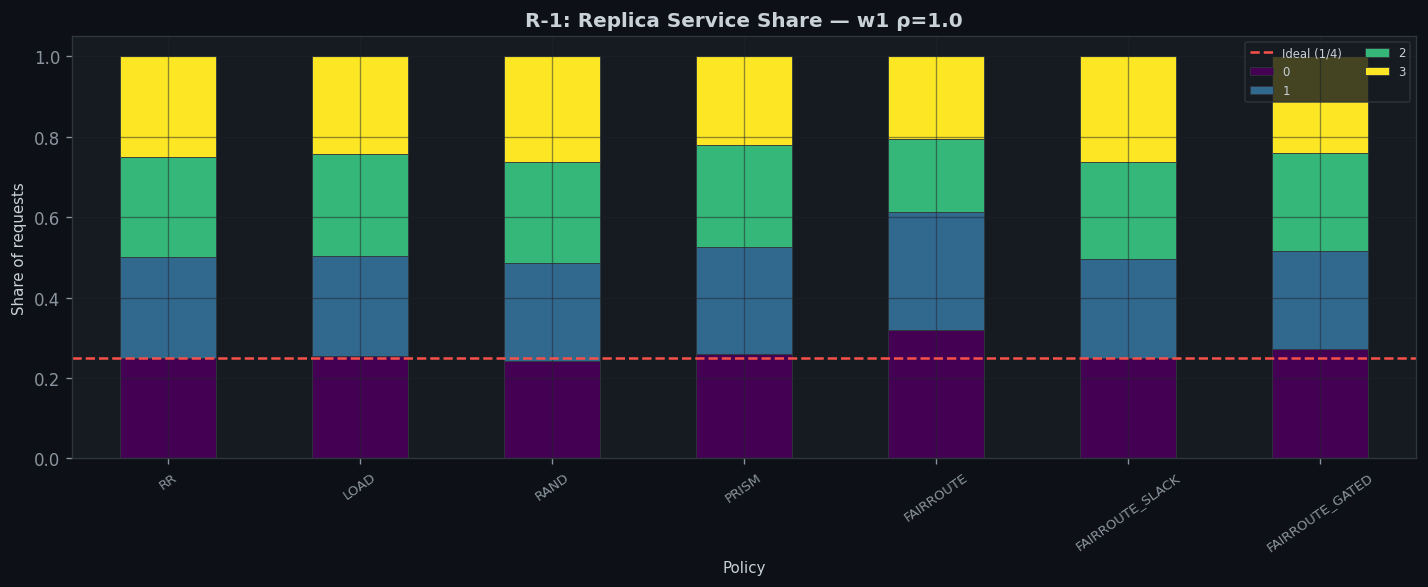

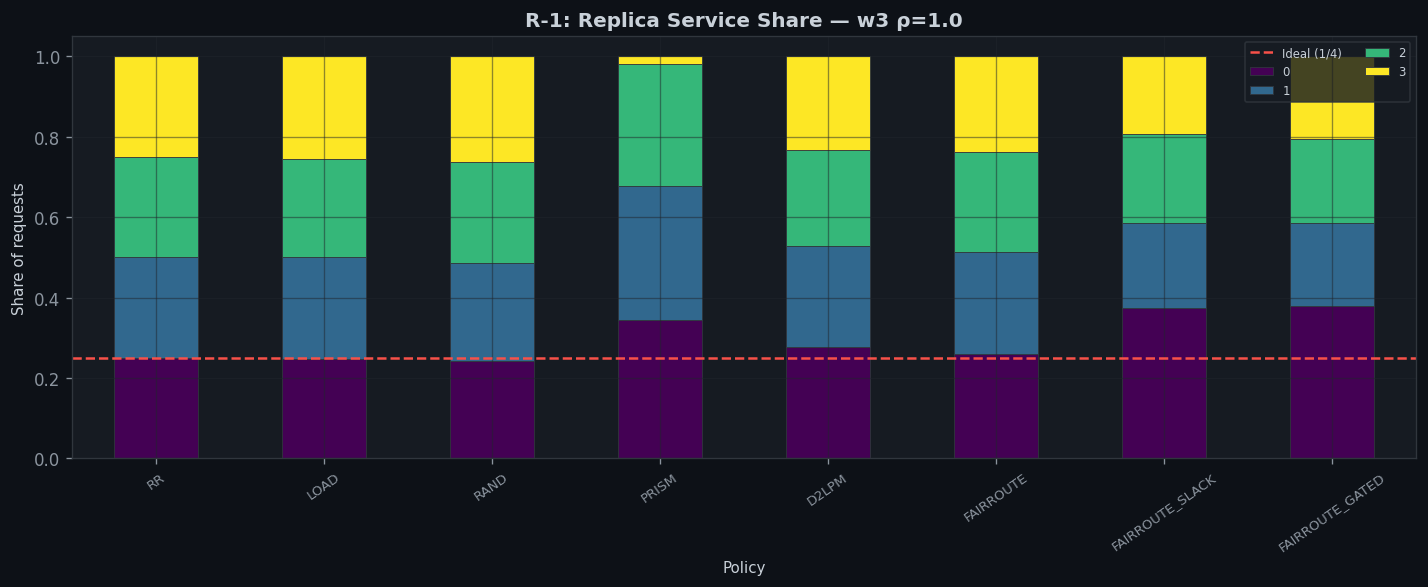

In [28]:
# ─── R-1: Replica service share ───
for wl in ['w1', 'w3']:
    for rho_val in [1.0, 0.8]:
        sub = requests_df[(requests_df['workload'] == wl) & (requests_df['rho'] == rho_val)]
        if len(sub) == 0:
            continue
        policies_here = [p for p in available_policies if p in sub['policy_name'].unique()]
        if not policies_here:
            continue
        n_inst = sub['instance id'].nunique()
        ideal = 1.0 / n_inst

        fig, ax = plt.subplots(figsize=(12, 5))
        shares = sub.groupby(['policy_name', 'instance id']).size().unstack(fill_value=0)
        shares = shares.div(shares.sum(axis=1), axis=0)
        shares = shares.reindex(index=policies_here)
        shares.plot(kind='bar', stacked=True, ax=ax, colormap='viridis', edgecolor='#30363d', linewidth=0.5)
        ax.axhline(y=ideal, color='#f85149', linestyle='--', linewidth=1.5, label=f'Ideal (1/{n_inst})')
        ax.set_title(f'R-1: Replica Service Share — {wl} ρ={rho_val}', fontsize=12, fontweight='bold')
        ax.set_xlabel('Policy', fontsize=9)
        ax.set_ylabel('Share of requests', fontsize=9)
        ax.legend(fontsize=7, loc='upper right', ncol=2)
        ax.tick_params(axis='x', rotation=35, labelsize=8)
        plt.tight_layout()
        plt.savefig(FIGURE_DIR / f'R1_replica_share_{wl}_rho{rho_val}.png', dpi=150)
        plt.show()
        break  # first available

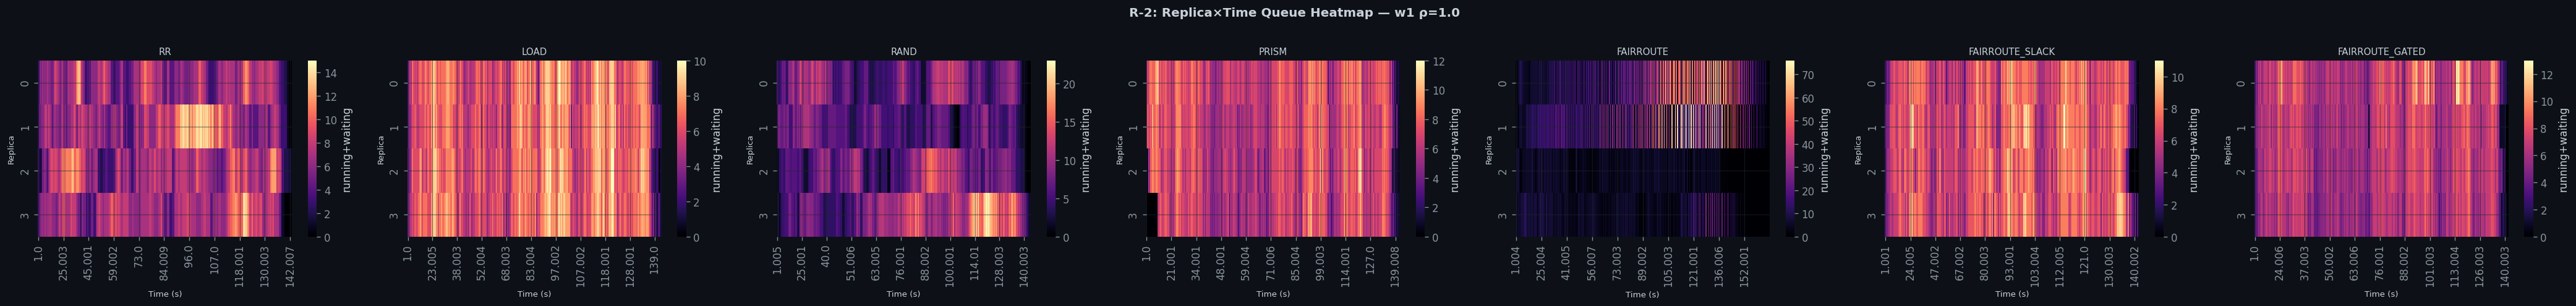

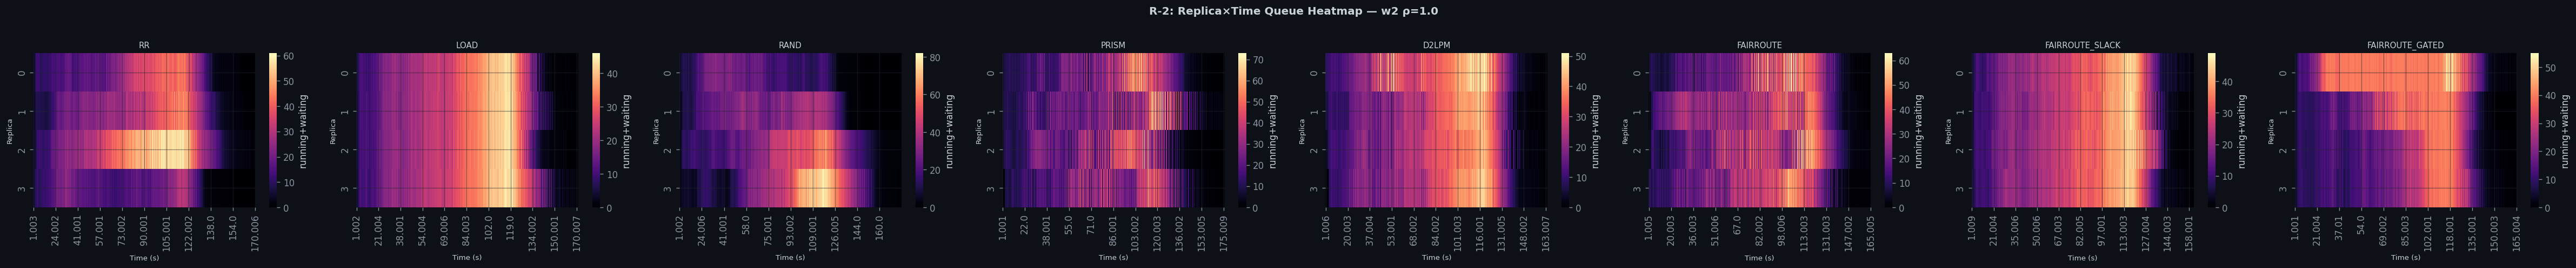

In [29]:
# ─── R-2: Replica x Time queue heatmap ───
if len(ts_df) > 0:
    for wl in workloads[:2]:
        for rho_val in [1.0, 0.8]:
            ts_sub = ts_df[(ts_df['workload'] == wl) & (ts_df['rho'] == rho_val)]
            if len(ts_sub) == 0:
                continue
            policies_here = [p for p in ROUTING_POLICIES if p in ts_sub['policy_name'].unique()]
            if not policies_here:
                policies_here = ts_sub['policy_name'].unique()[:4]
            n = len(policies_here)
            if n == 0:
                continue
            fig, axes = plt.subplots(1, n, figsize=(5 * n, 4), squeeze=False)
            for j, pol in enumerate(policies_here):
                ax = axes[0, j]
                pol_ts = ts_sub[ts_sub['policy_name'] == pol]
                pol_ts = pol_ts.copy()
                pol_ts['total_load'] = pol_ts['running_reqs'] + pol_ts['waiting_reqs']
                pivot = pol_ts.pivot_table(index='instance_id', columns='timestamp_s',
                                           values='total_load', aggfunc='mean')
                if pivot.shape[0] > 0 and pivot.shape[1] > 0:
                    sns.heatmap(pivot, ax=ax, cmap='magma', cbar_kws={'label': 'running+waiting'},
                                xticklabels=max(1, pivot.shape[1] // 10))
                ax.set_title(pol, fontsize=9)
                ax.set_xlabel('Time (s)', fontsize=8)
                ax.set_ylabel('Replica', fontsize=8)
            fig.suptitle(f'R-2: Replica×Time Queue Heatmap — {wl} ρ={rho_val}',
                         fontsize=12, fontweight='bold', y=1.02)
            plt.tight_layout()
            plt.savefig(FIGURE_DIR / f'R2_queue_heatmap_{wl}_rho{rho_val}.png', dpi=150)
            plt.show()
            break

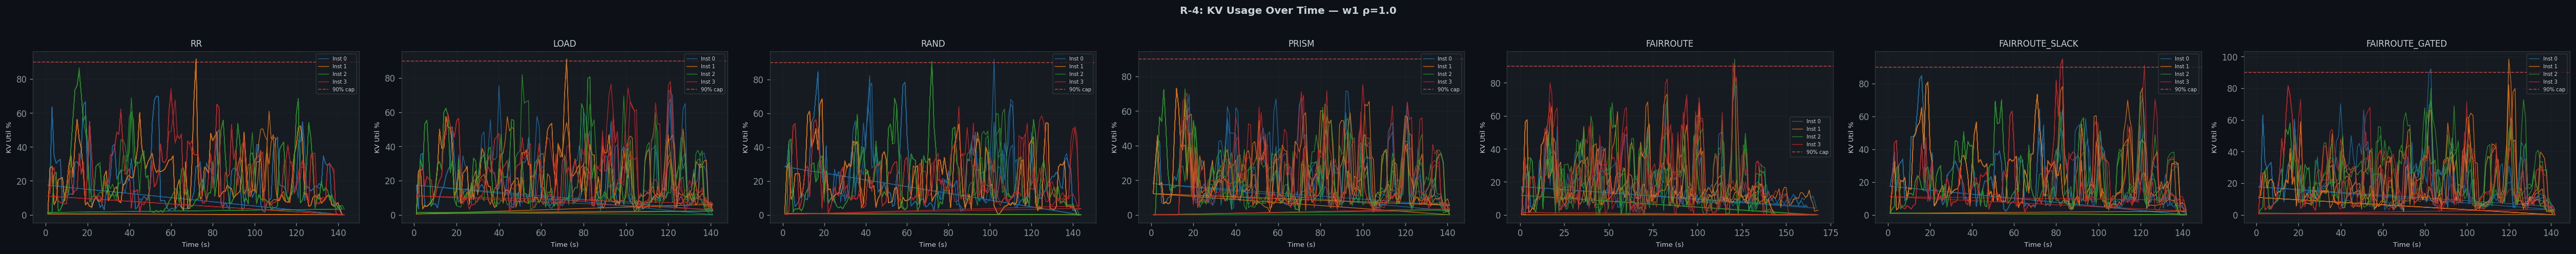

In [30]:
# ─── R-4: KV usage per replica over time ───
if len(ts_df) > 0:
    for wl in workloads[:1]:
        for rho_val in [1.0, 1.25, 0.8]:
            ts_sub = ts_df[(ts_df['workload'] == wl) & (ts_df['rho'] == rho_val)]
            if len(ts_sub) == 0:
                continue
            policies_here = [p for p in ROUTING_POLICIES if p in ts_sub['policy_name'].unique()]
            if not policies_here:
                continue
            fig, axes = plt.subplots(1, len(policies_here), figsize=(6 * len(policies_here), 4), squeeze=False)
            for j, pol in enumerate(policies_here):
                ax = axes[0, j]
                pol_ts = ts_sub[ts_sub['policy_name'] == pol]
                for inst_id in sorted(pol_ts['instance_id'].unique()):
                    inst_ts = pol_ts[pol_ts['instance_id'] == inst_id]
                    ax.plot(inst_ts['timestamp_s'].astype(float), inst_ts['kv_util_pct'].astype(float),
                            label=f'Inst {inst_id}', linewidth=0.8, alpha=0.8)
                ax.axhline(y=KV_HIGH_WATER * 100, color='#f85149', linestyle='--', linewidth=1, alpha=0.7, label='90% cap')
                ax.set_title(pol, fontsize=10)
                ax.set_xlabel('Time (s)', fontsize=8)
                ax.set_ylabel('KV Util %', fontsize=8)
                ax.legend(fontsize=6)
            fig.suptitle(f'R-4: KV Usage Over Time — {wl} ρ={rho_val}', fontsize=12, fontweight='bold', y=1.02)
            plt.tight_layout()
            plt.savefig(FIGURE_DIR / f'R4_kv_usage_{wl}_rho{rho_val}.png', dpi=150)
            plt.show()
            break

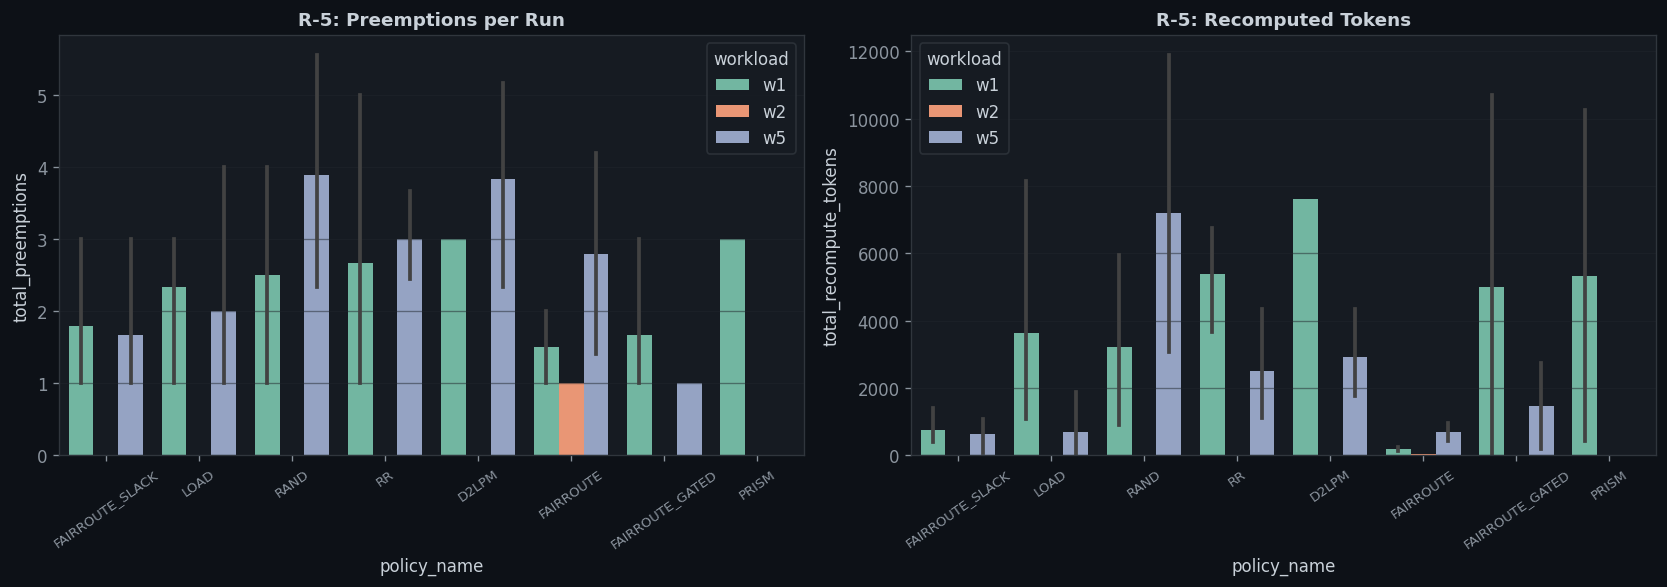

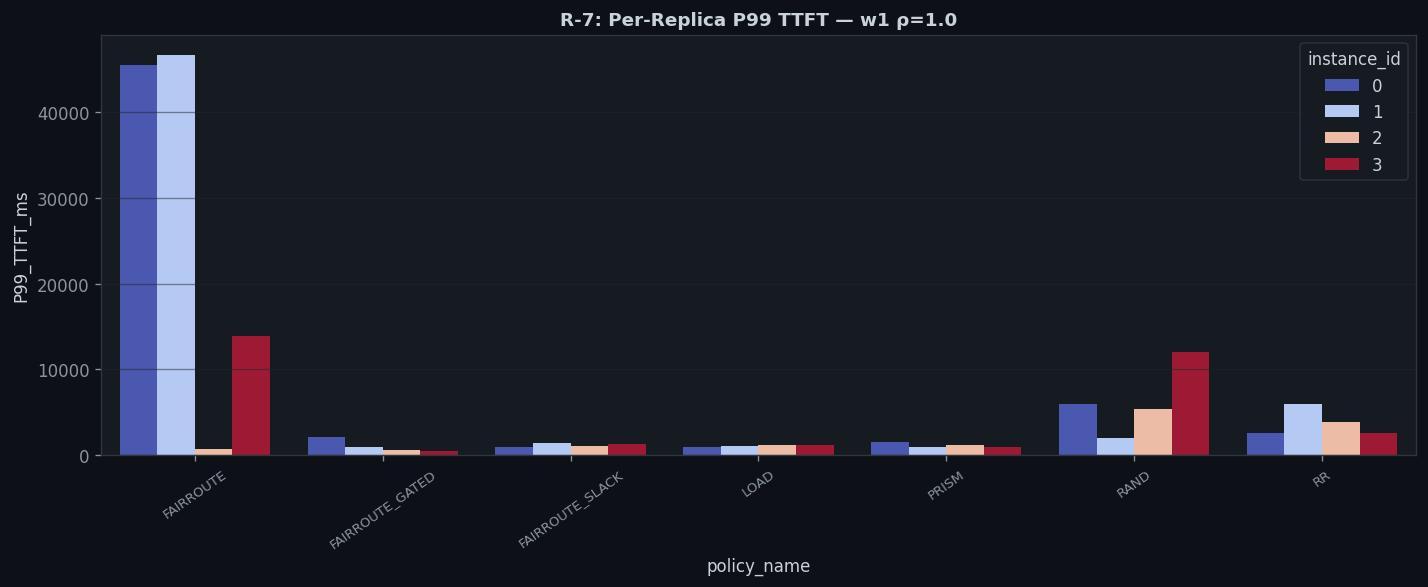

In [31]:
# ─── R-5: Preemptions and recomputed tokens ───
preempt_data = summary[summary['total_preemptions'] > 0]
if len(preempt_data) > 0:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    sns.barplot(data=preempt_data, x='policy_name', y='total_preemptions', hue='workload',
                ax=axes[0], palette='Set2')
    axes[0].set_title('R-5: Preemptions per Run', fontsize=11, fontweight='bold')
    axes[0].tick_params(axis='x', rotation=35, labelsize=8)
    sns.barplot(data=preempt_data, x='policy_name', y='total_recompute_tokens', hue='workload',
                ax=axes[1], palette='Set2')
    axes[1].set_title('R-5: Recomputed Tokens', fontsize=11, fontweight='bold')
    axes[1].tick_params(axis='x', rotation=35, labelsize=8)
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / 'R5_preemptions.png', dpi=150)
    plt.show()
else:
    print('✅ No preemptions in any run (R-5)')

# ─── R-7: Per-replica P99 TTFT ───
for wl in workloads[:1]:
    for rho_val in [1.0, 0.8]:
        sub = requests_df[(requests_df['workload'] == wl) & (requests_df['rho'] == rho_val)]
        if len(sub) == 0:
            continue
        inst_ttft = sub.groupby(['policy_name', 'instance id'])['TTFT_ms'].quantile(0.99).reset_index()
        inst_ttft.columns = ['policy_name', 'instance_id', 'P99_TTFT_ms']
        fig, ax = plt.subplots(figsize=(12, 5))
        sns.barplot(data=inst_ttft, x='policy_name', y='P99_TTFT_ms', hue='instance_id',
                    ax=ax, palette='coolwarm')
        ax.set_title(f'R-7: Per-Replica P99 TTFT — {wl} ρ={rho_val}', fontsize=11, fontweight='bold')
        ax.tick_params(axis='x', rotation=35, labelsize=8)
        plt.tight_layout()
        plt.savefig(FIGURE_DIR / f'R7_replica_ttft_{wl}_rho{rho_val}.png', dpi=150)
        plt.show()
        break

## 8. Locality Charts (Section 3.4)

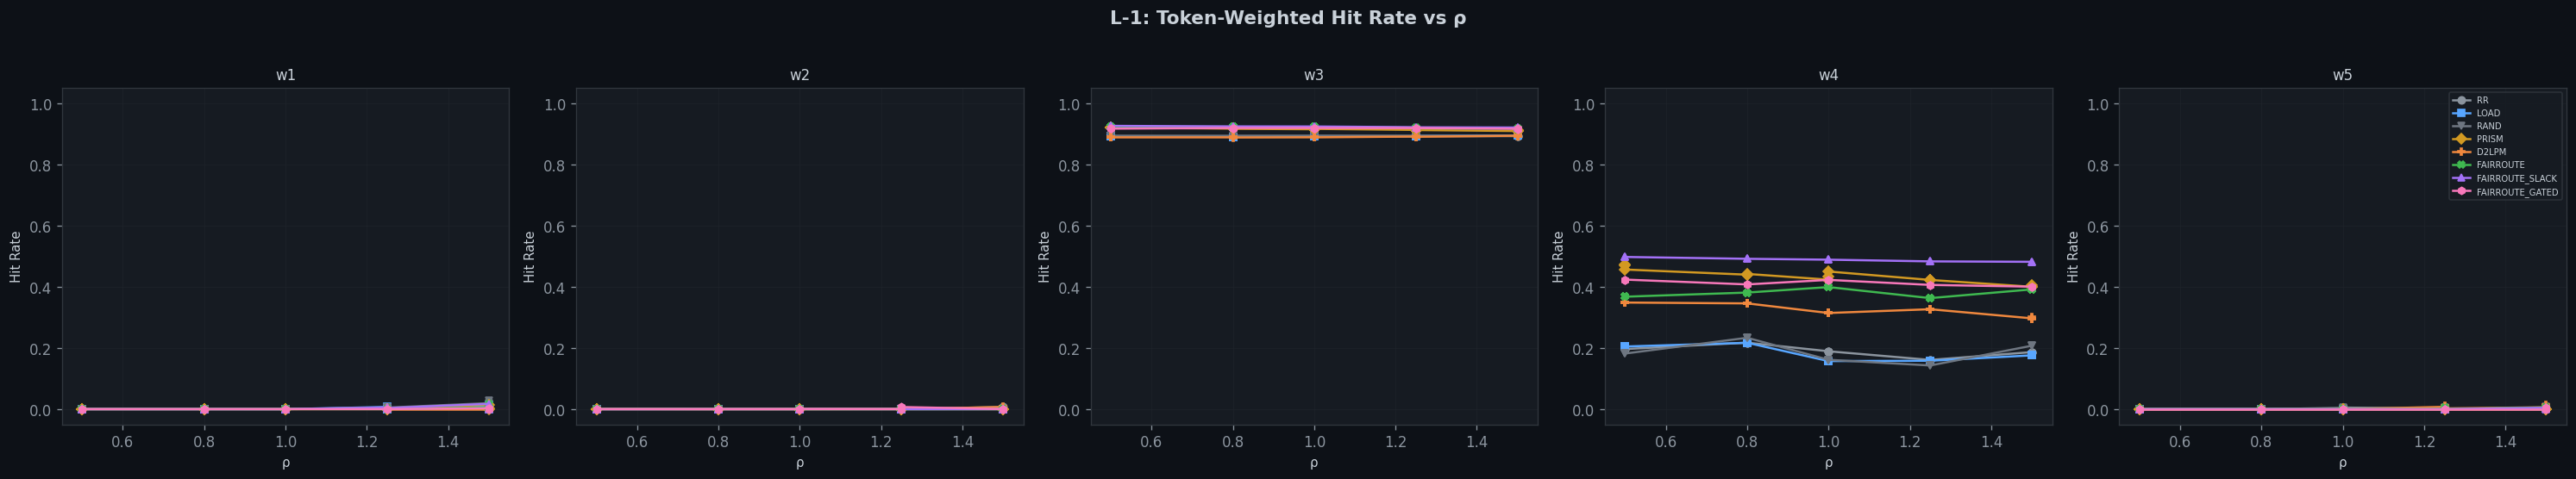

In [32]:
# ─── L-1: Hit rate vs ρ ───
if n_wl > 0:
    fig, axes = plt.subplots(1, n_wl, figsize=(5 * n_wl, 4.5), squeeze=False)
    for i, wl in enumerate(workloads):
        ax = axes[0, i]
        wl_data = summary[summary['workload'] == wl]
        for pol in available_policies:
            pol_data = wl_data[wl_data['policy_name'] == pol].sort_values('rho')
            if len(pol_data) == 0:
                continue
            ax.plot(pol_data['rho'], pol_data['hit_rate'],
                    marker=POLICY_MARKERS.get(pol, 'o'), color=POLICY_COLORS.get(pol, '#fff'),
                    label=pol, linewidth=1.5, markersize=5)
        ax.set_xlabel('ρ', fontsize=9)
        ax.set_ylabel('Hit Rate', fontsize=9)
        ax.set_title(f'{wl}', fontsize=10)
        ax.set_ylim(-0.05, 1.05)
        if i == n_wl - 1:
            ax.legend(fontsize=6, loc='best')
    fig.suptitle('L-1: Token-Weighted Hit Rate vs ρ', fontsize=13, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / 'L1_hit_rate_vs_rho.png', dpi=150)
    plt.show()

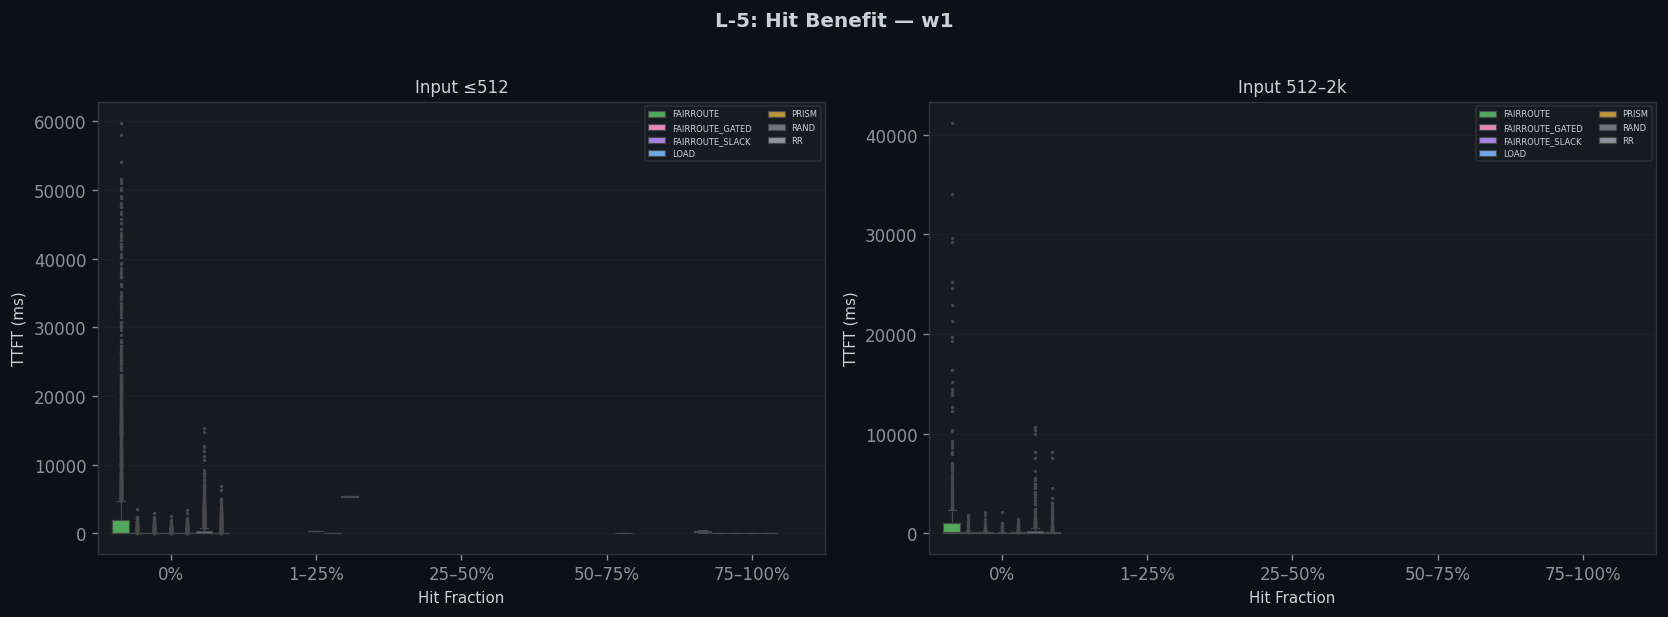

In [33]:
# ─── L-5: Hit benefit — TTFT by hit fraction bin within input-length strata ───
requests_df['hit_bin'] = pd.cut(
    requests_df['hit_fraction'],
    bins=[-0.01, 0.01, 0.25, 0.50, 0.75, 1.01],
    labels=['0%', '1–25%', '25–50%', '50–75%', '75–100%']
)

for wl in workloads[:2]:
    sub = requests_df[(requests_df['workload'] == wl) & (requests_df['rho'].isin([1.0, 0.8]))]
    if len(sub) == 0:
        continue
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    for ax, ib in zip(axes, ['≤512', '512–2k']):
        data = sub[sub['input_bin'] == ib]
        if len(data) > 10:
            sns.boxplot(data=data, x='hit_bin', y='TTFT_ms', hue='policy_name',
                        ax=ax, palette=POLICY_COLORS, fliersize=1, linewidth=0.7)
            ax.set_title(f'Input {ib}', fontsize=10)
            ax.set_xlabel('Hit Fraction', fontsize=9)
            ax.set_ylabel('TTFT (ms)', fontsize=9)
            ax.legend(fontsize=5, loc='best', ncol=2)
    fig.suptitle(f'L-5: Hit Benefit — {wl}', fontsize=12, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / f'L5_hit_benefit_{wl}.png', dpi=150)
    plt.show()
    break

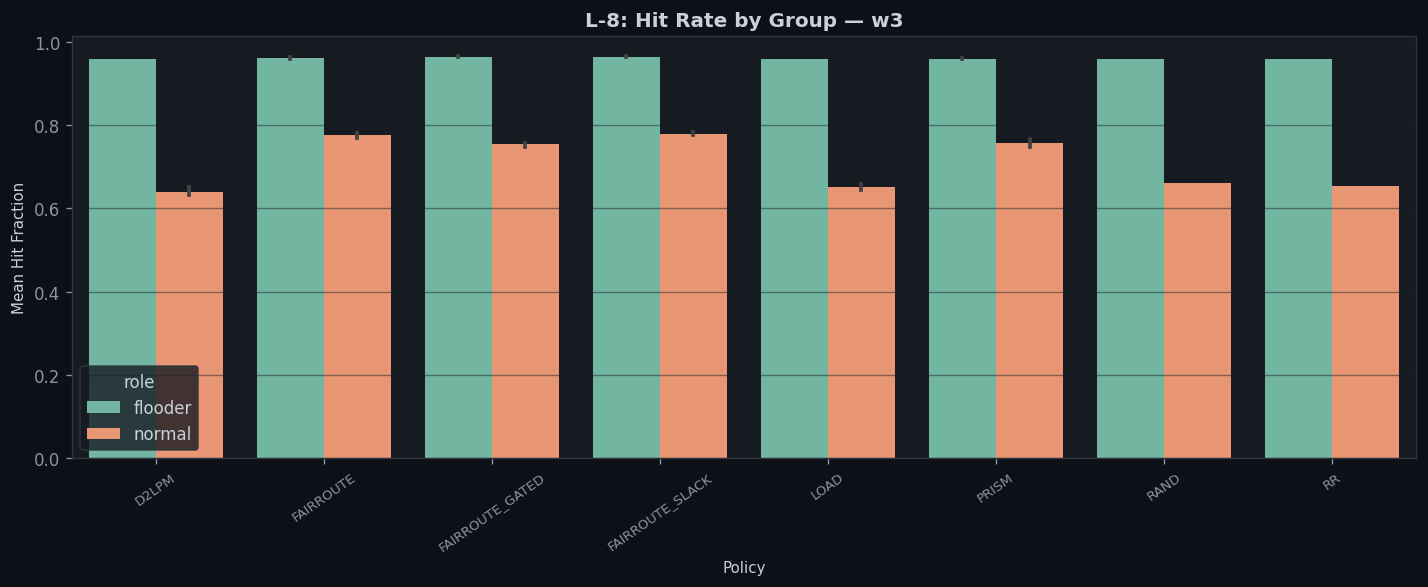

In [34]:
# ─── L-8: Flooder vs normal hit rates ───
for wl in ['w3']:
    sub = requests_df[(requests_df['workload'] == wl)]
    if len(sub) == 0 or sub['role'].nunique() <= 1:
        print(f'⚠️ No role data for {wl}')
        continue
    hit_by_group = sub.groupby(['policy_name', 'role', 'rho'])['hit_fraction'].mean().reset_index()
    fig, ax = plt.subplots(figsize=(12, 5))
    sns.barplot(data=hit_by_group, x='policy_name', y='hit_fraction', hue='role',
                ax=ax, palette='Set2')
    ax.set_title(f'L-8: Hit Rate by Group — {wl}', fontsize=12, fontweight='bold')
    ax.set_xlabel('Policy', fontsize=9)
    ax.set_ylabel('Mean Hit Fraction', fontsize=9)
    ax.tick_params(axis='x', rotation=35, labelsize=8)
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / f'L8_group_hit_rate_{wl}.png', dpi=150)
    plt.show()

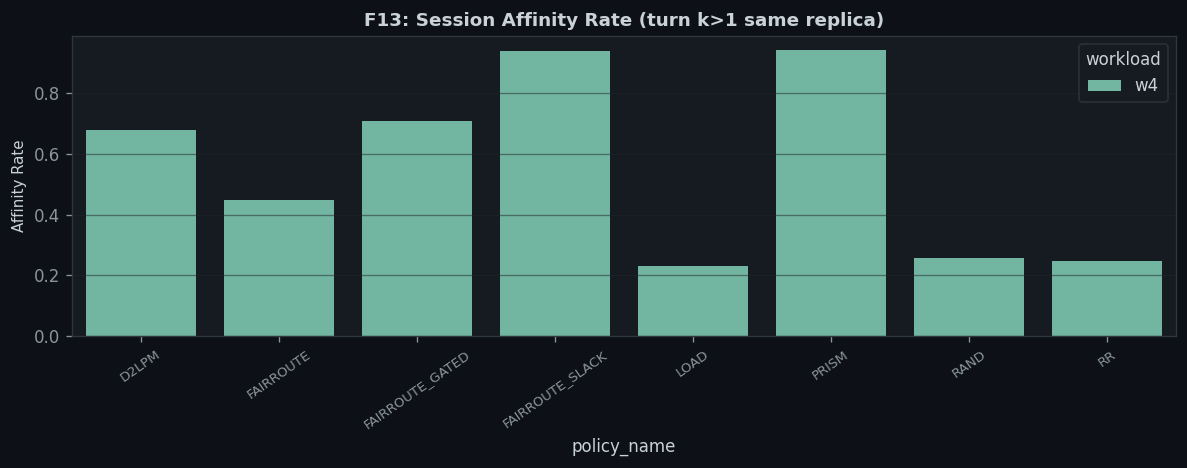

In [35]:
# ─── F13: Session affinity rate (W4 multi-turn) ───
session_df = requests_df[requests_df['session_id'].notna() & (requests_df['session_id'] != '')].copy()
if len(session_df) > 0:
    session_df = session_df.sort_values(['run_key', 'session_id', 'sub_request_index'])
    session_df['prev_instance'] = session_df.groupby(['run_key', 'session_id'])['instance id'].shift(1)
    turns_gt_0 = session_df[session_df['sub_request_index'].astype(float) > 0]
    if len(turns_gt_0) > 0:
        turns_gt_0 = turns_gt_0.copy()
        turns_gt_0['same_replica'] = turns_gt_0['instance id'] == turns_gt_0['prev_instance']
        affinity = turns_gt_0.groupby(['policy_name', 'workload'])['same_replica'].mean().reset_index()
        fig, ax = plt.subplots(figsize=(10, 4))
        sns.barplot(data=affinity, x='policy_name', y='same_replica', hue='workload',
                    ax=ax, palette='Set2')
        ax.set_title('F13: Session Affinity Rate (turn k>1 same replica)', fontsize=11, fontweight='bold')
        ax.set_ylabel('Affinity Rate', fontsize=9)
        ax.tick_params(axis='x', rotation=35, labelsize=8)
        plt.tight_layout()
        plt.savefig(FIGURE_DIR / 'F13_session_affinity.png', dpi=150)
        plt.show()
    else:
        print('⚠️ No multi-turn sessions found for F13')
else:
    print('⚠️ No session data available for F13')

## 9. Prediction & Decision Diagnostics (Sections 3.5, 3.6)

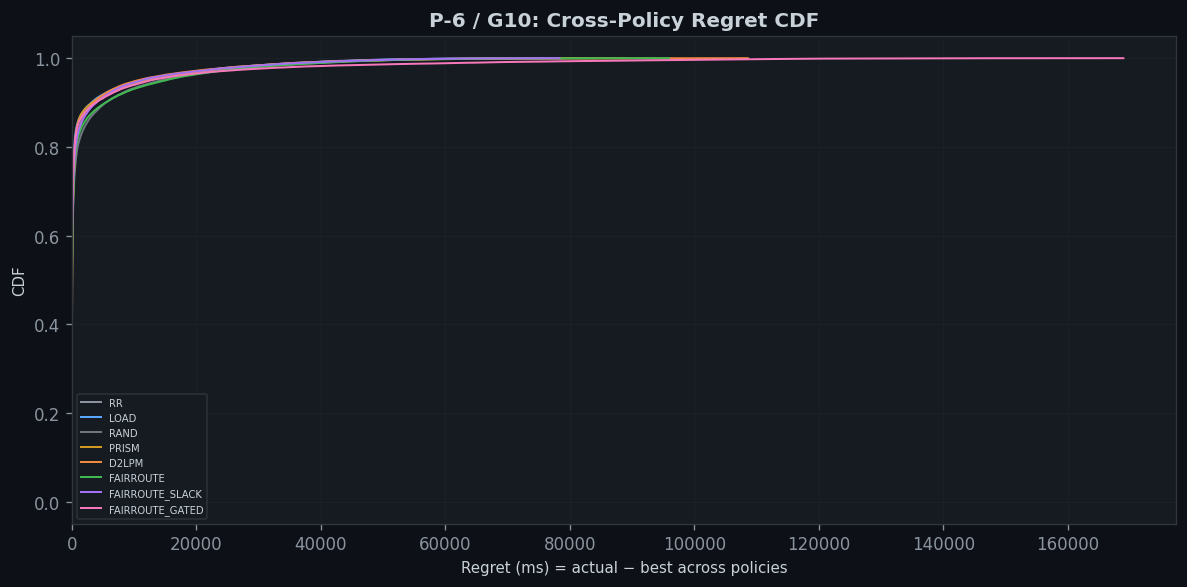

In [36]:
# ─── G10/P-6: Cross-policy regret CDF ───
def compute_cross_policy_regret(df):
    """For each request, compute actual_policy - min(actual across all policies)."""
    regret_frames = []
    for (wl, cell, local_policy), cell_grp in df.groupby(['workload', 'cell', 'local_policy_name']):
        # Get per-request latency for each router within one local scheduler.
        pivot = cell_grp.pivot_table(index='request id', columns='policy_name',
                                      values='latency_ms', aggfunc='first')
        if pivot.shape[1] < 2:
            continue
        best = pivot.min(axis=1)
        for pol in pivot.columns:
            regret = pivot[pol] - best
            regret_frames.append(pd.DataFrame({
                'workload': wl, 'cell': cell, 'local_policy_name': local_policy, 'policy': pol,
                'regret_ms': regret.values,
            }))
    if regret_frames:
        return pd.concat(regret_frames, ignore_index=True)
    return pd.DataFrame()

regret_df = compute_cross_policy_regret(requests_df)
if len(regret_df) > 0:
    fig, ax = plt.subplots(figsize=(10, 5))
    for pol in available_policies:
        data = regret_df[regret_df['policy'] == pol]['regret_ms'].dropna().sort_values()
        if len(data) == 0:
            continue
        cdf = np.arange(1, len(data) + 1) / len(data)
        ax.plot(data.values, cdf, label=pol,
                color=POLICY_COLORS.get(pol, '#fff'), linewidth=1.2)
    ax.set_xlabel('Regret (ms) = actual − best across policies', fontsize=9)
    ax.set_ylabel('CDF', fontsize=9)
    ax.set_title('P-6 / G10: Cross-Policy Regret CDF', fontsize=12, fontweight='bold')
    ax.set_xlim(left=-1)
    ax.legend(fontsize=6, loc='best')
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / 'P6_regret_cdf.png', dpi=150)
    plt.show()
else:
    print('⚠️ Not enough policies per cell for regret computation')

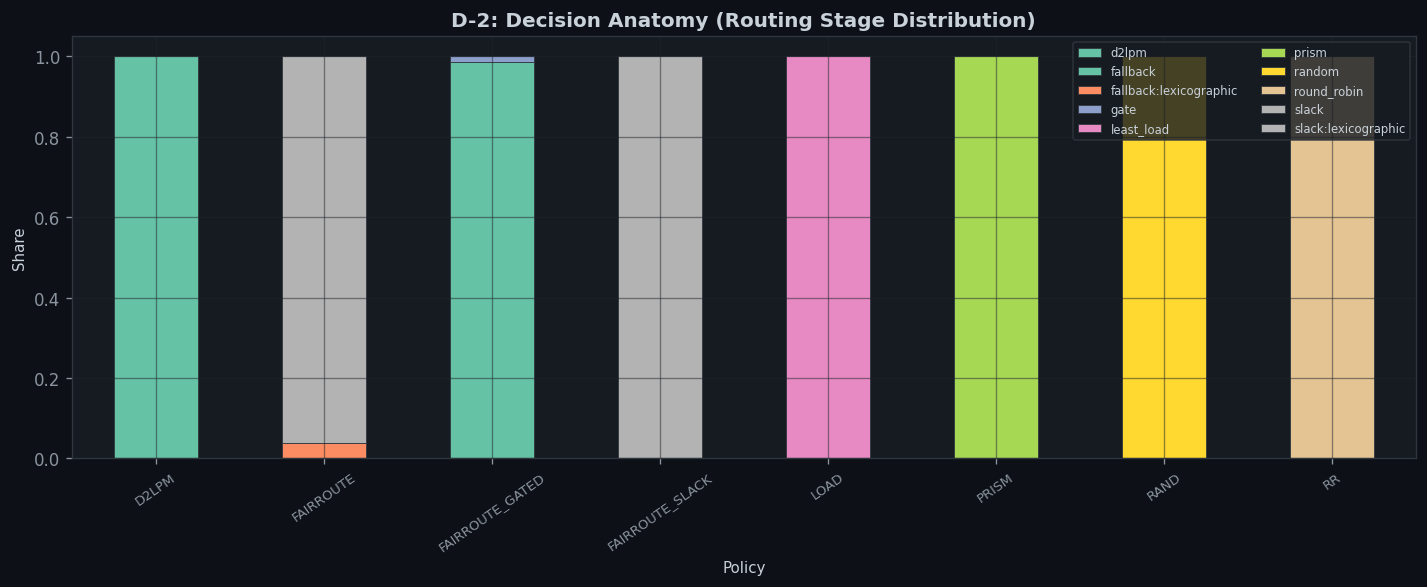

In [37]:
# ─── D-2: Decision anatomy — routing stage distribution ───
stage_col = 'routing stage'
if stage_col in requests_df.columns:
    stage_data = requests_df[requests_df[stage_col].notna() & (requests_df[stage_col] != '')]
    if len(stage_data) > 0:
        stage_counts = stage_data.groupby(['policy_name', stage_col]).size().unstack(fill_value=0)
        stage_pcts = stage_counts.div(stage_counts.sum(axis=1), axis=0)
        fig, ax = plt.subplots(figsize=(12, 5))
        stage_pcts.plot(kind='bar', stacked=True, ax=ax, colormap='Set2',
                        edgecolor='#30363d', linewidth=0.5)
        ax.set_title('D-2: Decision Anatomy (Routing Stage Distribution)', fontsize=12, fontweight='bold')
        ax.set_xlabel('Policy', fontsize=9)
        ax.set_ylabel('Share', fontsize=9)
        ax.tick_params(axis='x', rotation=35, labelsize=8)
        ax.legend(fontsize=7, loc='best', ncol=2)
        plt.tight_layout()
        plt.savefig(FIGURE_DIR / 'D2_decision_anatomy.png', dpi=150)
        plt.show()

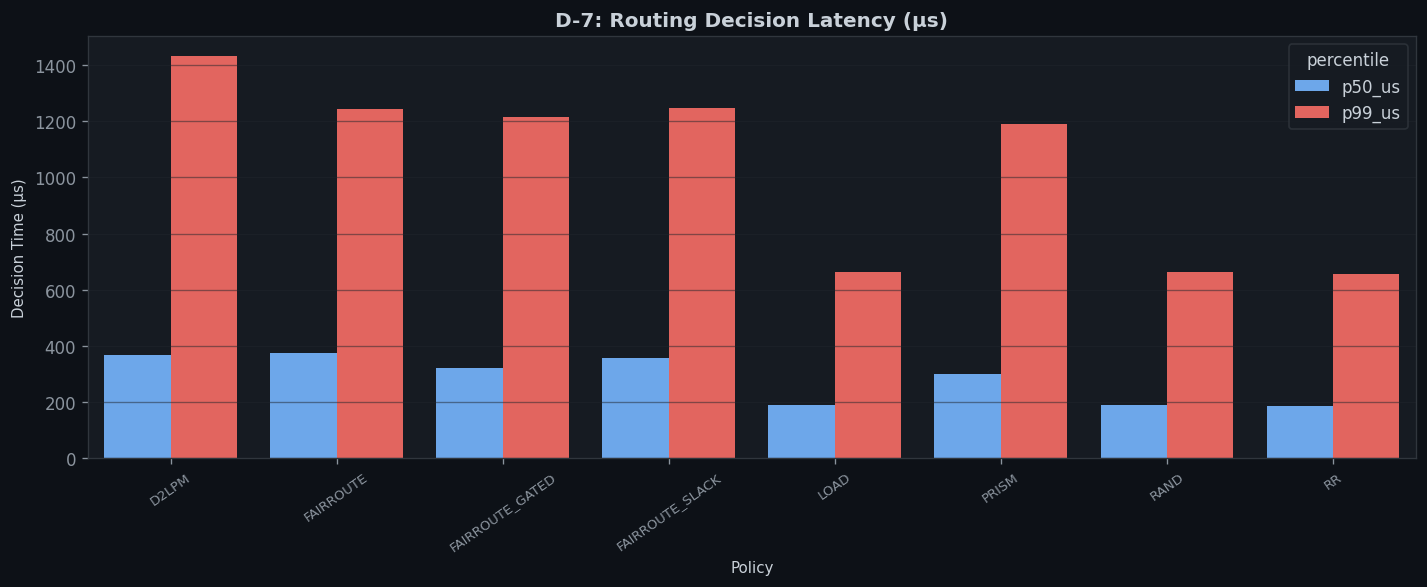

In [38]:
# ─── D-7: Decision latency ───
routing_json_data = []
for _, row in run_index.iterrows():
    if row['routing_json_path'] and os.path.exists(row['routing_json_path']):
        try:
            with open(row['routing_json_path']) as f:
                rj = json.load(f)
            rj['workload'] = row['workload']
            rj['rho'] = row['rho']
            rj['policy_name'] = row['policy']
            routing_json_data.append(rj)
        except:
            pass

if routing_json_data:
    rj_df = pd.DataFrame(routing_json_data)
    rj_df['p50_us'] = rj_df['decision_ns'].apply(lambda x: x.get('p50', 0) / 1000)
    rj_df['p99_us'] = rj_df['decision_ns'].apply(lambda x: x.get('p99', 0) / 1000)

    fig, ax = plt.subplots(figsize=(12, 5))
    # Show p50 and p99 per policy
    decision_summary = rj_df.groupby('policy_name').agg(
        p50_us=('p50_us', 'median'),
        p99_us=('p99_us', 'median'),
    ).reset_index().melt(id_vars='policy_name', var_name='percentile', value_name='µs')
    sns.barplot(data=decision_summary, x='policy_name', y='µs', hue='percentile',
                ax=ax, palette=['#58a6ff', '#f85149'])
    ax.set_title('D-7: Routing Decision Latency (µs)', fontsize=12, fontweight='bold')
    ax.set_xlabel('Policy', fontsize=9)
    ax.set_ylabel('Decision Time (µs)', fontsize=9)
    ax.tick_params(axis='x', rotation=35, labelsize=8)
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / 'D7_decision_latency.png', dpi=150)
    plt.show()

Loaded 616,560 decision sidecar records across 588 runs
Computing and plotting [SIDE] decision metrics...


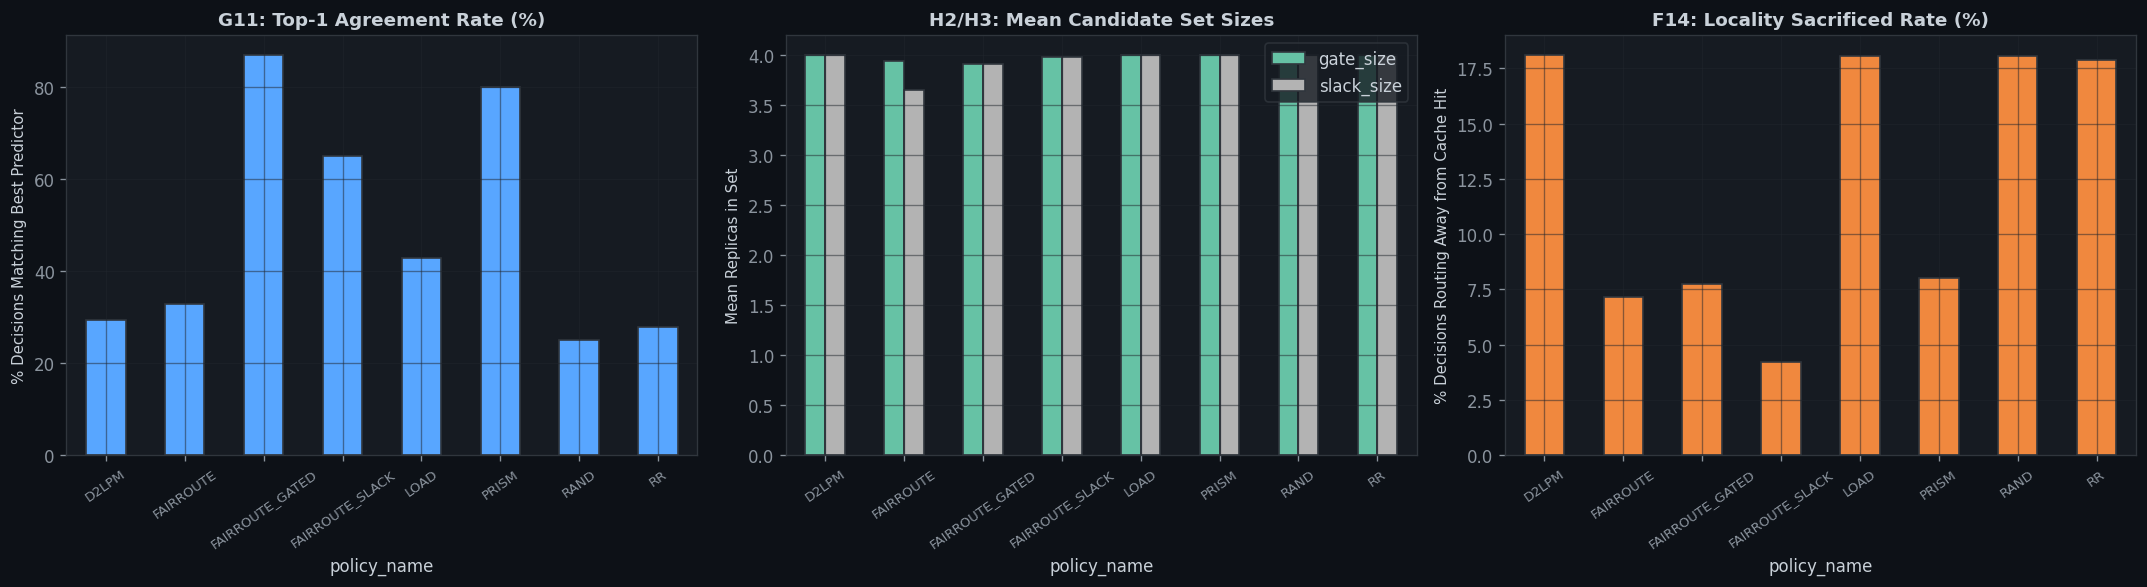

G1–G7 & H5–H7: Predictor & Fairness Decision Summary:


,MAE_ms,RMSE_ms,MAPE,Mean_Urgency,Credit_Exhaust_Rate
policy_name,,,,,
D2LPM,2800.270,9822.800,0.569,0.000,0.000
FAIRROUTE,3180.531,10244.926,0.546,0.183,0.000
FAIRROUTE_GATED,3562.897,14509.052,1.000,0.182,0.265
FAIRROUTE_SLACK,2857.090,9658.827,1.000,0.184,0.262
LOAD,2713.969,9515.054,0.505,0.000,0.000
PRISM,2810.925,9845.216,0.455,0.000,0.000
RAND,3158.716,10170.711,0.571,0.000,0.000
RR,2807.556,9572.779,0.522,0.000,0.000


In [47]:
# ─── Load Decision Sidecars ([SIDE]) and Compute Sidecar-Dependent Metrics ───
def load_all_sidecars(run_index):
    """Load per-request decision sidecars if available."""
    frames = []
    for _, row in run_index.iterrows():
        if not row.get('sidecar_path') or not os.path.exists(row['sidecar_path']):
            continue
        records = []
        try:
            with open(row['sidecar_path']) as f:
                for line in f:
                    if line.strip():
                        records.append(json.loads(line))
            if records:
                df_side = pd.DataFrame(records)
                df_side['workload'] = row['workload']
                df_side['cell'] = row['cell']
                df_side['K'] = row['K']
                df_side['rho'] = row['rho']
                df_side['seed'] = row['seed']
                df_side['policy_name'] = row['policy']
                df_side['local_policy_name'] = row['local_policy']
                df_side['policy_label'] = df_side['policy_name'] + ' / ' + df_side['local_policy_name']
                df_side['run_key'] = f"{row['workload']}/{row['cell']}/{row['policy']}/{row['local_policy']}"
                frames.append(df_side)
        except Exception as e:
            print(f"  WARN: Failed to load sidecar {row['sidecar_path']}: {e}")
    if frames:
        return pd.concat(frames, ignore_index=True)
    return pd.DataFrame()

sidecars_df = load_all_sidecars(run_index)
print(f'Loaded {len(sidecars_df):,} decision sidecar records across {sidecars_df["run_key"].nunique() if len(sidecars_df) > 0 else 0} runs')

if len(sidecars_df) == 0:
    print('═' * 70)
    print('Note: No [SIDE] decision sidecars found yet in existing run outputs.')
    print('When simulations are executed with the updated Router, decision sidecars')
    print('(*.sidecar.jsonl) are automatically saved and will be analyzed here.')
    print('═' * 70)
else:
    print('Computing and plotting [SIDE] decision metrics...')

    # Merge with requests_df to get actual TTFT and latency
    side_merged = sidecars_df.merge(
        requests_df[['run_key', 'request id', 'TTFT_ms', 'latency_ms', 'input', 'input_bin']],
        left_on=['run_key', 'request_id'],
        right_on=['run_key', 'request id'],
        how='inner'
    )

    if len(side_merged) > 0:
        # Extract chosen replica predicted TTFT in ms
        def get_chosen_pred_ttft_ms(row):
            pred_ttfts = row.get('per_replica_predicted_ttft', [])
            chosen = int(row.get('chosen_replica', 0))
            if pred_ttfts and 0 <= chosen < len(pred_ttfts):
                predicted = pred_ttfts[chosen]
                if predicted is not None and np.isfinite(predicted):
                    return float(predicted) * 1000.0
            return 0.0

        side_merged['pred_ttft_ms'] = side_merged.apply(get_chosen_pred_ttft_ms, axis=1)
        side_merged['ttft_err_ms'] = side_merged['pred_ttft_ms'] - side_merged['TTFT_ms']
        side_merged['abs_ttft_err_ms'] = side_merged['ttft_err_ms'].abs()
        side_merged['mape_ttft'] = side_merged['abs_ttft_err_ms'] / side_merged['TTFT_ms'].clip(lower=1.0)

        # ─── G1–G9: Predictor Quality ───
        fig, axes = plt.subplots(1, 3, figsize=(18, 5))

        # 1. Top-1 Agreement Rate (G11)
        top1 = sidecars_df.groupby('policy_name')['top1_agreement'].mean() * 100.0
        top1.plot(kind='bar', ax=axes[0], color='#58a6ff', edgecolor='#30363d')
        axes[0].set_title('G11: Top-1 Agreement Rate (%)', fontsize=11, fontweight='bold')
        axes[0].set_ylabel('% Decisions Matching Best Predictor', fontsize=9)
        axes[0].tick_params(axis='x', rotation=35, labelsize=8)

        # 2. Gate & Slack Set Sizes (H2, H3)
        sizes = sidecars_df.groupby('policy_name')[['gate_size', 'slack_size']].mean()
        sizes.plot(kind='bar', ax=axes[1], colormap='Set2', edgecolor='#30363d')
        axes[1].set_title('H2/H3: Mean Candidate Set Sizes', fontsize=11, fontweight='bold')
        axes[1].set_ylabel('Mean Replicas in Set', fontsize=9)
        axes[1].tick_params(axis='x', rotation=35, labelsize=8)

        # 3. Locality Sacrificed Rate (F14)
        loc_sac = sidecars_df.groupby('policy_name')['locality_sacrificed'].mean() * 100.0
        loc_sac.plot(kind='bar', ax=axes[2], color='#f0883e', edgecolor='#30363d')
        axes[2].set_title('F14: Locality Sacrificed Rate (%)', fontsize=11, fontweight='bold')
        axes[2].set_ylabel('% Decisions Routing Away from Cache Hit', fontsize=9)
        axes[2].tick_params(axis='x', rotation=35, labelsize=8)

        plt.tight_layout()
        plt.savefig(FIGURE_DIR / 'SIDE_decision_dynamics.png', dpi=150)
        plt.show()

        # Prediction Accuracy Summary Table
        pred_summary = side_merged.groupby('policy_name').agg(
            MAE_ms=('abs_ttft_err_ms', 'mean'),
            RMSE_ms=('ttft_err_ms', lambda x: np.sqrt((x**2).mean())),
            MAPE=('mape_ttft', 'median'),
            Mean_Urgency=('urgency', 'mean'),
            Credit_Exhaust_Rate=('credit_exhausted', 'mean'),
        ).round(3)
        print('G1–G7 & H5–H7: Predictor & Fairness Decision Summary:')
        display(pred_summary)


## 10. Cross-Run Comparison Charts (Section 3.7, 3.8)

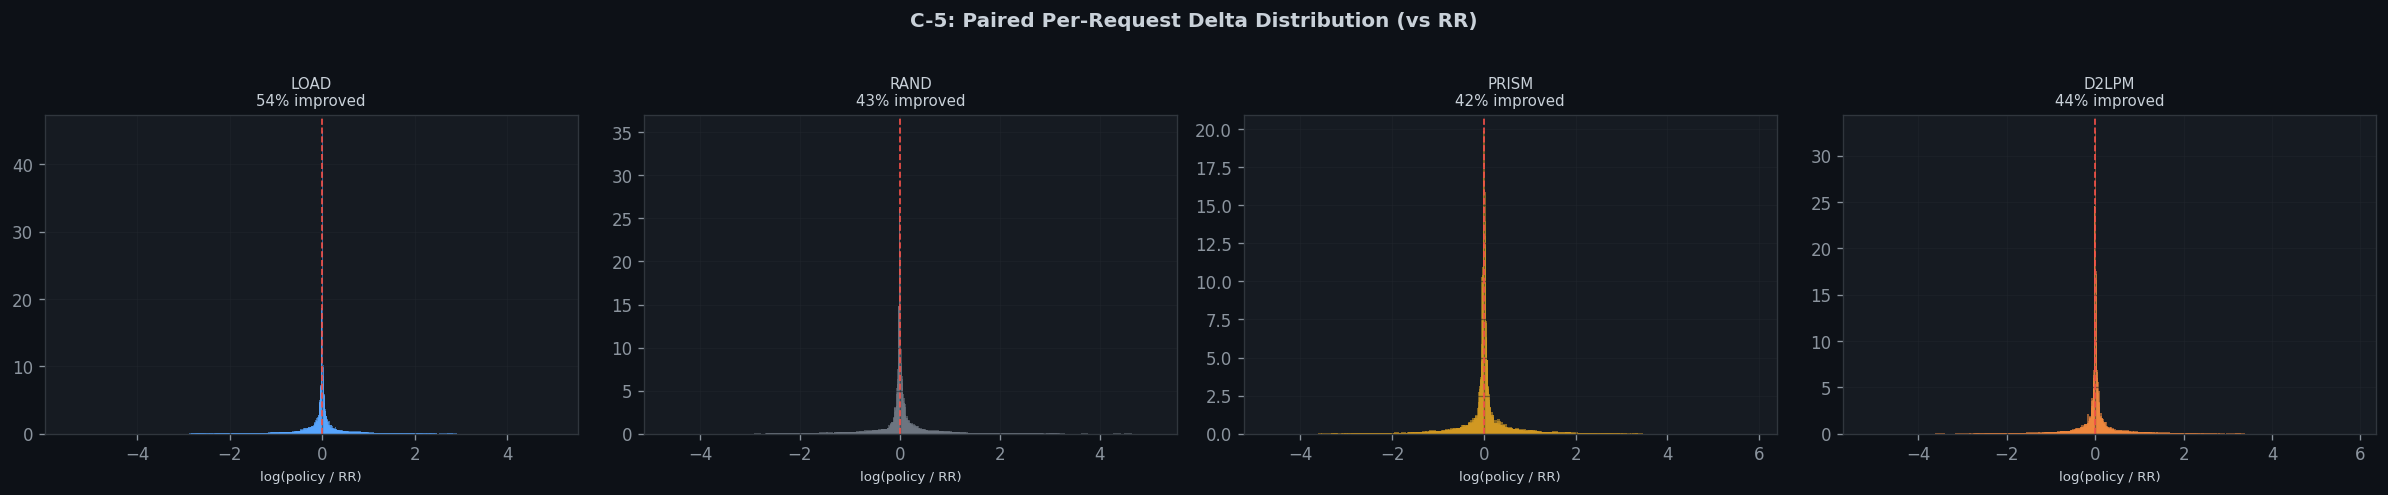

In [40]:
# ─── C-5: Paired per-request delta distribution ───
if len(paired_deltas) > 0:
    policies_to_show = [p for p in CORE_POLICIES if p in paired_deltas['policy'].unique() and p != 'RR']
    if policies_to_show:
        n = len(policies_to_show)
        fig, axes = plt.subplots(1, min(n, 4), figsize=(5 * min(n, 4), 4), squeeze=False)
        for j, pol in enumerate(policies_to_show[:4]):
            ax = axes[0, j]
            # Get per-request log ratios for this policy
            for (wl, cell, local_policy), cell_grp in requests_df.groupby(['workload', 'cell', 'local_policy_name']):
                bl = cell_grp[cell_grp['policy_name'] == 'RR'].set_index('request id')['latency_ms']
                pol_data = cell_grp[cell_grp['policy_name'] == pol].set_index('request id')['latency_ms']
                common = bl.index.intersection(pol_data.index)
                if len(common) < 10:
                    continue
                lr = np.log(pol_data.loc[common].values / bl.loc[common].clip(lower=1e-6).values)
                ax.hist(lr, bins=50, alpha=0.6, color=POLICY_COLORS.get(pol, '#fff'),
                        edgecolor='none', density=True, label=f'{wl} / {local_policy}')
            ax.axvline(x=0, color='#f85149', linestyle='--', linewidth=1)
            share_imp = paired_deltas[paired_deltas['policy'] == pol]['share_improved'].mean()
            ax.set_title(f'{pol}\n{share_imp:.0%} improved', fontsize=9)
            ax.set_xlabel('log(policy / RR)', fontsize=8)
        fig.suptitle('C-5: Paired Per-Request Delta Distribution (vs RR)',
                     fontsize=12, fontweight='bold', y=1.02)
        plt.tight_layout()
        plt.savefig(FIGURE_DIR / 'C5_paired_delta.png', dpi=150)
        plt.show()

In [41]:
# ─── I7/I8: Effect size and significance ───
def compute_effect_sizes(df, baseline='RR'):
    results = []
    for (wl, cell, local_policy), cell_grp in df.groupby(['workload', 'cell', 'local_policy_name']):
        bl = cell_grp[cell_grp['policy_name'] == baseline].set_index('request id')['latency_ms']
        if len(bl) == 0:
            continue
        for pol in cell_grp['policy_name'].unique():
            if pol == baseline:
                continue
            pol_data = cell_grp[cell_grp['policy_name'] == pol].set_index('request id')['latency_ms']
            common = bl.index.intersection(pol_data.index)
            if len(common) < 20:
                continue
            x, y = bl.loc[common].values, pol_data.loc[common].values
            # Cliff's delta
            n_more = sum(1 for i in range(len(x)) for j in range(len(y)) if y[j] < x[i])
            n_less = sum(1 for i in range(len(x)) for j in range(len(y)) if y[j] > x[i])
            n_total = len(x) * len(y)
            cliff_d = (n_more - n_less) / n_total if n_total > 0 else 0
            # Wilcoxon (only on subset for speed)
            sample_size = min(len(common), 5000)
            idx = np.random.choice(len(common), sample_size, replace=False)
            try:
                stat, pval = sp_stats.wilcoxon(x[idx], y[idx], alternative='two-sided')
            except:
                pval = 1.0
            results.append({
                'workload': wl, 'cell': cell, 'local_policy_name': local_policy, 'policy': pol,
                'cliff_delta': cliff_d, 'wilcoxon_p': pval,
                'significant': pval < 0.05,
            })
    return pd.DataFrame(results)

effects = compute_effect_sizes(requests_df)
if len(effects) > 0:
    effect_summary = effects.groupby('policy').agg(
        mean_cliff_delta=('cliff_delta', 'mean'),
        pct_significant=('significant', 'mean'),
    ).sort_values('mean_cliff_delta')
    print('I7/I8: Effect Size and Significance (vs RR):')
    display(effect_summary)

I7/I8: Effect Size and Significance (vs RR):


,mean_cliff_delta,pct_significant
policy,,
RAND,-0.041439,0.840000
FAIRROUTE,-0.026995,0.560000
D2LPM,-0.014731,0.857143
FAIRROUTE_GATED,-0.005799,0.800000
FAIRROUTE_SLACK,-0.002007,0.693333
PRISM,0.003193,0.746667
LOAD,0.020276,0.706667


## 11. B13: Length-Stratified TTFT

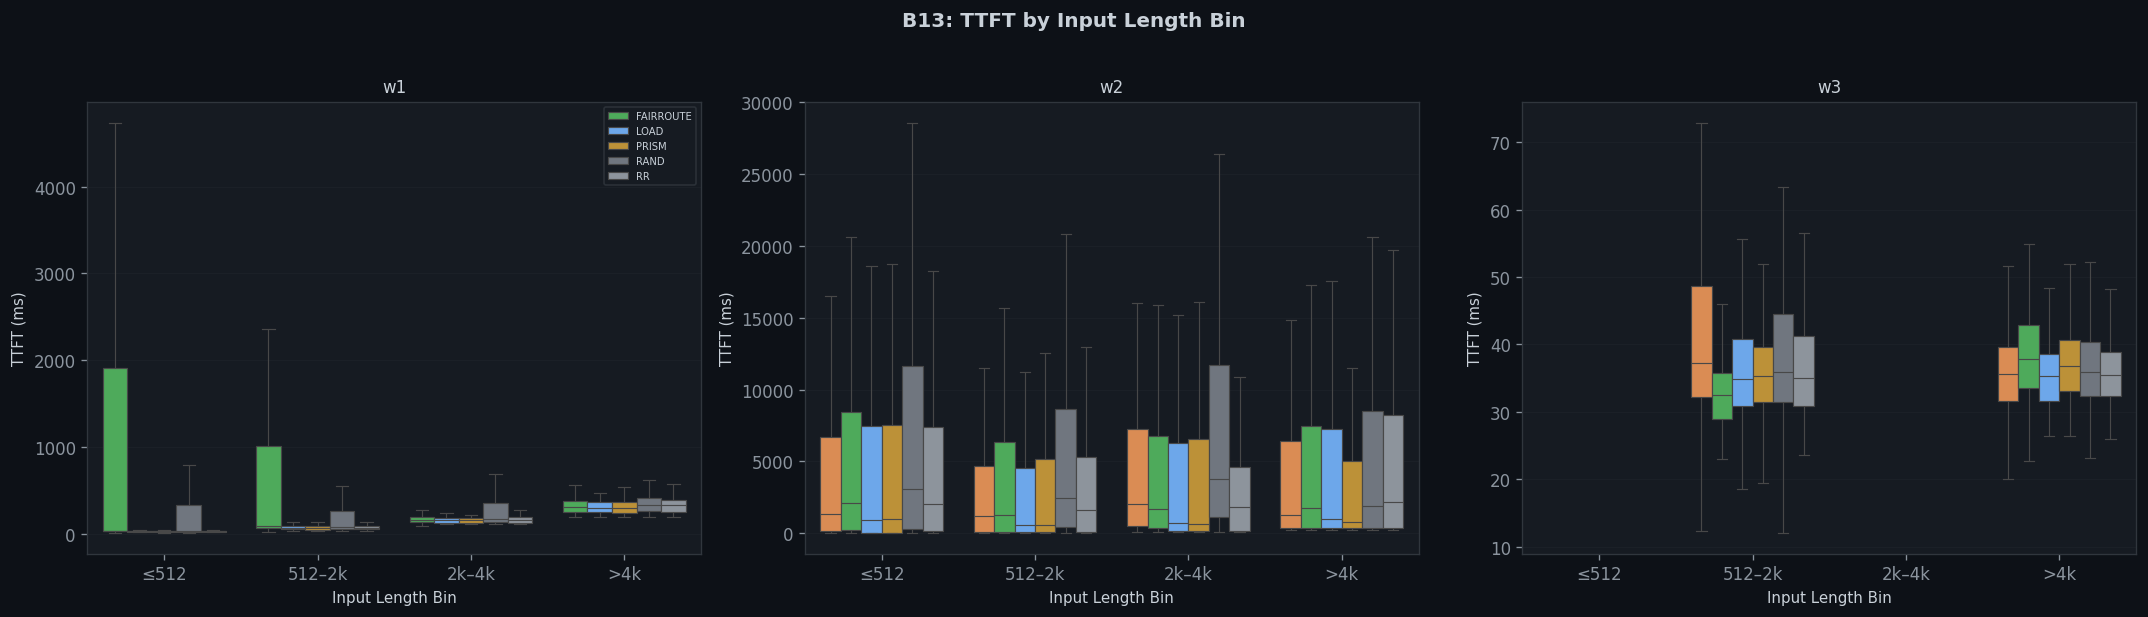

In [42]:
# ─── B13: TTFT by input length bin ───
fig, axes = plt.subplots(1, min(n_wl, 3), figsize=(6 * min(n_wl, 3), 5), squeeze=False)
for i, wl in enumerate(workloads[:3]):
    ax = axes[0, i]
    sub = requests_df[(requests_df['workload'] == wl) & (requests_df['rho'].isin([1.0, 0.8]))]
    if len(sub) == 0:
        continue
    # Show only core policies
    core_sub = sub[sub['policy_name'].isin(available_policies[:6])]
    if len(core_sub) > 0:
        sns.boxplot(data=core_sub, x='input_bin', y='TTFT_ms', hue='policy_name',
                    ax=ax, palette=POLICY_COLORS, fliersize=1, linewidth=0.7,
                    showfliers=False)
    ax.set_title(f'{wl}', fontsize=10)
    ax.set_xlabel('Input Length Bin', fontsize=9)
    ax.set_ylabel('TTFT (ms)', fontsize=9)
    if i == 0:
        ax.legend(fontsize=6, loc='best')
    else:
        ax.get_legend().remove() if ax.get_legend() else None
fig.suptitle('B13: TTFT by Input Length Bin', fontsize=12, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'B13_ttft_by_length.png', dpi=150)
plt.show()

## 12. Throughput Timeseries (C5)

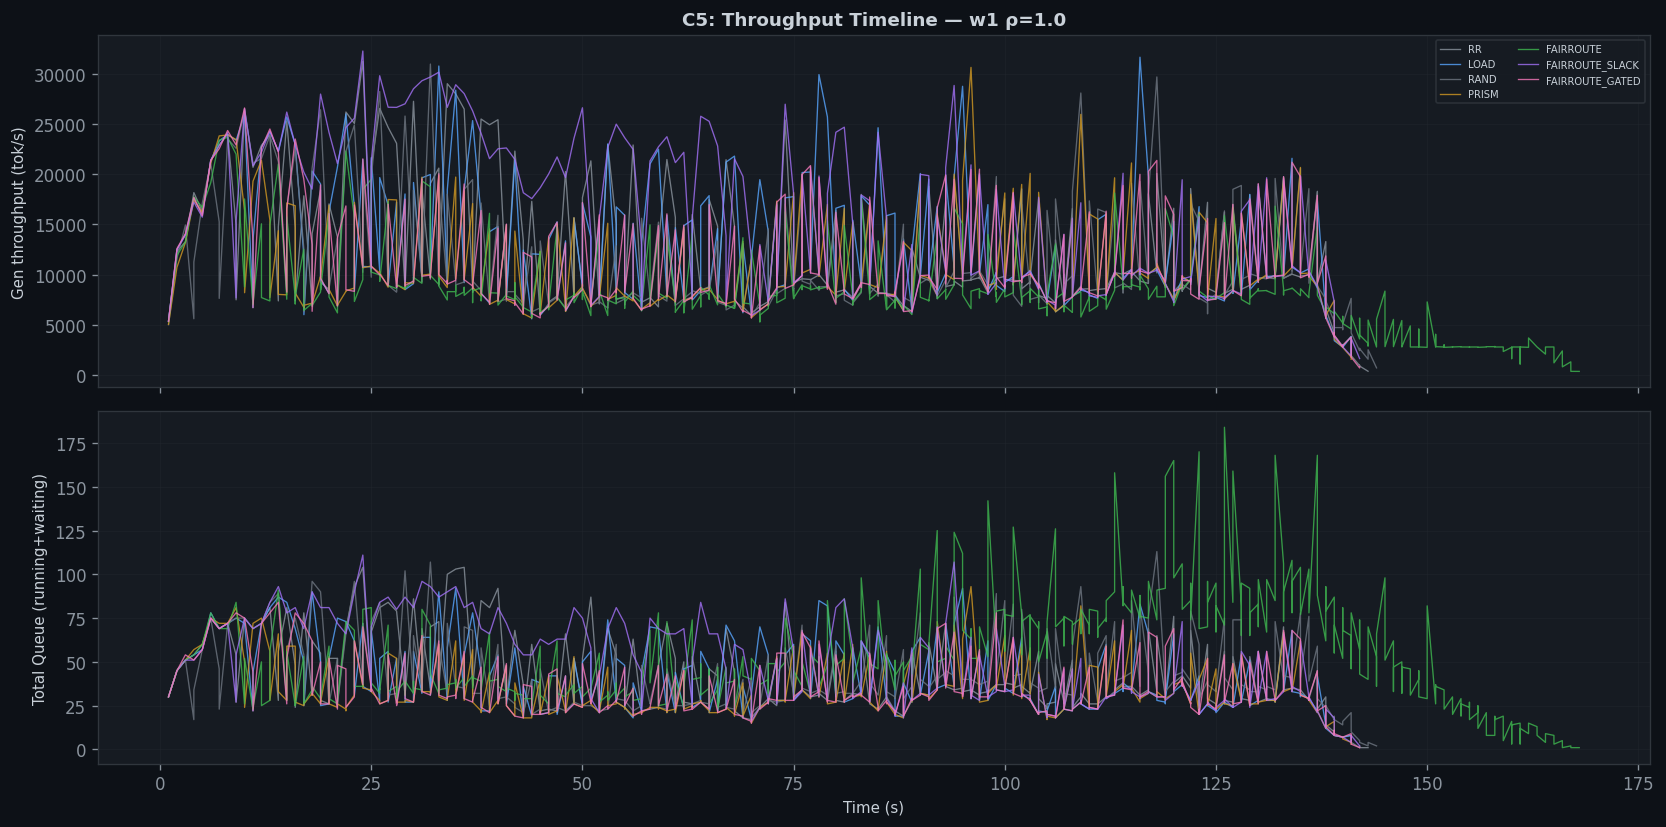

In [43]:
# ─── C5 / S-6: Throughput timeline ───
if len(ts_df) > 0:
    for wl in workloads[:1]:
        for rho_val in [1.0, 1.25, 0.8]:
            ts_sub = ts_df[(ts_df['workload'] == wl) & (ts_df['rho'] == rho_val)]
            if len(ts_sub) == 0:
                continue
            fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
            for pol in available_policies:
                pol_ts = ts_sub[ts_sub['policy_name'] == pol]
                if len(pol_ts) == 0:
                    continue
                # Aggregate across instances per timestamp
                agg = pol_ts.groupby('timestamp_s').agg(
                    gen_th=('gen_th_toks_per_s', 'sum'),
                    total_running=('running_reqs', 'sum'),
                    total_waiting=('waiting_reqs', 'sum'),
                ).reset_index()
                axes[0].plot(agg['timestamp_s'].astype(float), agg['gen_th'].astype(float),
                             label=pol, color=POLICY_COLORS.get(pol, '#fff'), linewidth=0.8, alpha=0.8)
                axes[1].plot(agg['timestamp_s'].astype(float), (agg['total_running'] + agg['total_waiting']).astype(float),
                             label=pol, color=POLICY_COLORS.get(pol, '#fff'), linewidth=0.8, alpha=0.8)
            axes[0].set_ylabel('Gen throughput (tok/s)', fontsize=9)
            axes[0].set_title(f'C5: Throughput Timeline — {wl} ρ={rho_val}', fontsize=11, fontweight='bold')
            axes[0].legend(fontsize=6, loc='best', ncol=2)
            axes[1].set_ylabel('Total Queue (running+waiting)', fontsize=9)
            axes[1].set_xlabel('Time (s)', fontsize=9)
            plt.tight_layout()
            plt.savefig(FIGURE_DIR / f'C5_throughput_timeline_{wl}_rho{rho_val}.png', dpi=150)
            plt.show()
            break

## 13. Policy Scorecard (Section 4 — the 12 core metrics)

In [44]:
# ─── H-10: Policy Scorecard Table ───
scorecard_metrics = {
    'P99 TTFT (ms)': ('TTFT_p99_ms', True),          # lower better
    'P99 TPOT (ms)': ('TPOT_p99_ms', True),
    'Throughput (tok/s)': ('output_tok_throughput', False),  # higher better
    'Replica Jain': ('replica_jain', False),
    'Hit Rate': ('hit_rate', False),
    'Decision p99 (ns)': ('routing_decision_ns_p99', True),
    'Makespan Inflation': ('makespan_inflation', True),
    'Busiest Replica %': ('busiest_replica_share', True),
}

if HAS_SLOWDOWN:
    scorecard_metrics['P99 Slowdown'] = ('slowdown_p99', True)
    scorecard_metrics['Goodput (tok/s)'] = ('goodput_tok_s', False)
if 'D6_jain_latency' in summary.columns:
    scorecard_metrics['Jain (latency)'] = ('D6_jain_latency', False)
if 'D7_worst_client_ratio' in summary.columns:
    scorecard_metrics['Worst-Client Ratio'] = ('D7_worst_client_ratio', True)

# Keep router and local scheduler separate; pooling them would hide scheduling effects.
scorecard = summary.groupby(['policy_name', 'local_policy_name']).agg(
    **{label: (col, 'mean') for label, (col, _) in scorecard_metrics.items()}
).round(3)

# Highlight best
def highlight_best(s, ascending=True):
    if ascending:
        is_best = s == s.min()
    else:
        is_best = s == s.max()
    return ['font-weight: bold; color: #3fb950' if v else '' for v in is_best]

styled = scorecard.style
for label, (_, ascending) in scorecard_metrics.items():
    if label in scorecard.columns:
        styled = styled.apply(highlight_best, ascending=ascending, subset=[label])

print('H-10: Policy Scorecard (mean across all workloads & ρ)')
display(styled)

H-10: Policy Scorecard (mean across all workloads & ρ)


In [45]:
# ─── Per-workload scorecard ───
for wl in workloads:
    wl_summary = summary[summary['workload'] == wl]
    if len(wl_summary) == 0:
        continue
    sc = wl_summary.groupby(['policy_name', 'local_policy_name']).agg(
        **{label: (col, 'mean') for label, (col, _) in scorecard_metrics.items()}
    ).round(3)
    print(f'\n--- Scorecard: {wl} ---')
    display(sc)


--- Scorecard: w1 ---


P99 TTFT (ms)  P99 TPOT (ms)  \
policy_name     local_policy_name                                 
D2LPM           DLPM                   18080.216         16.850   
                FCFS                   15808.203         15.677   
                VTC                    44034.387         17.611   
FAIRROUTE       DLPM                   33912.408         15.959   
                FCFS                   16956.090         16.006   
                VTC                    33605.940         16.149   
FAIRROUTE_GATED DLPM                   15245.707         16.540   
                FCFS                   10913.235         16.106   
                VTC                    16665.723         16.494   
FAIRROUTE_SLACK DLPM                   17917.900         16.388   
                FCFS                    6297.278         15.776   
                VTC                    18248.645         16.073   
LOAD            DLPM                   18107.919         16.065   
                FCFS                    6490.158         15.818   
                VTC                    18696.519         16.164   
PRISM           DLPM                   14743.877         16.470   
                FCFS                    9007.967         16.421   
                VTC                    15367.223         16.441   
RAND            DLPM                   22183.793         16.411   
                FCFS                   12299.525         15.965   
                VTC                    22619.805         16.644   
RR              DLPM                   21180.554         16.293   
                FCFS                    7602.418         15.714   
                VTC                    20456.617         16.287   

                                   Throughput (tok/s)  Replica Jain  Hit Rate  \
policy_name     local_policy_name                                               
D2LPM           DLPM                         2366.480         0.997     0.000   
                FCFS                         2348.372         0.999     0.000   
                VTC                          2363.572         0.996     0.001   
FAIRROUTE       DLPM                         1725.149         0.968     0.001   
                FCFS                         1742.371         0.976     0.003   
                VTC                          1680.824         0.967     0.000   
FAIRROUTE_GATED DLPM                         1803.934         0.992     0.001   
                FCFS                         1794.455         0.991     0.000   
                VTC                          1793.853         0.992     0.000   
FAIRROUTE_SLACK DLPM                         1884.466         0.999     0.005   
                FCFS                         1880.070         0.999     0.001   
                VTC                          1876.902         0.999     0.001   
LOAD            DLPM                         1868.904         0.999     0.003   
                FCFS                         1878.602         0.999     0.000   
                VTC                          1874.061         0.999     0.002   
PRISM           DLPM                         1846.271         0.949     0.003   
                FCFS                         1846.475         0.952     0.000   
                VTC                          1853.086         0.951     0.000   
RAND            DLPM                         1803.370         0.999     0.005   
                FCFS                         1798.260         0.999     0.000   
                VTC                          1803.351         0.999     0.007   
RR              DLPM                         1864.607         1.000     0.004   
                FCFS                         1869.062         1.000     0.000   
                VTC                          1859.339         1.000     0.001   

                                   Decision p99 (ns)  Makespan Inflation  \
policy_name     local_policy_name                                          
D2LPM           DLPM             


--- Scorecard: w2 ---


P99 TTFT (ms)  P99 TPOT (ms)  \
policy_name     local_policy_name                                 
D2LPM           DLPM                   34832.922         14.448   
                FCFS                   33763.702         14.670   
                VTC                    52266.282         14.673   
FAIRROUTE       DLPM                   40565.991         14.133   
                FCFS                   32630.062         14.336   
                VTC                    40558.717         14.267   
FAIRROUTE_GATED DLPM                   61960.653         14.349   
                FCFS                   58896.536         14.424   
                VTC                    68506.713         14.255   
FAIRROUTE_SLACK DLPM                   36579.951         14.357   
                FCFS                   28512.197         14.599   
                VTC                    38351.555         14.187   
LOAD            DLPM                   35318.529         14.288   
                FCFS                   28521.220         14.641   
                VTC                    37869.761         14.404   
PRISM           DLPM                   37837.558         15.092   
                FCFS                   32269.522         14.949   
                VTC                    41578.623         14.863   
RAND            DLPM                   44165.413         14.515   
                FCFS                   35414.229         14.654   
                VTC                    46319.449         14.691   
RR              DLPM                   36198.024         13.977   
                FCFS                   29623.702         13.850   
                VTC                    37948.026         14.179   

                                   Throughput (tok/s)  Replica Jain  Hit Rate  \
policy_name     local_policy_name                                               
D2LPM           DLPM                         2024.638         0.996     0.002   
                FCFS                         2080.901         0.995     0.000   
                VTC                          2099.947         0.996     0.000   
FAIRROUTE       DLPM                         2072.076         0.998     0.000   
                FCFS                         2106.801         0.994     0.000   
                VTC                          2083.449         0.992     0.000   
FAIRROUTE_GATED DLPM                         1840.010         0.965     0.000   
                FCFS                         1827.119         0.952     0.000   
                VTC                          1813.231         0.954     0.002   
FAIRROUTE_SLACK DLPM                         2126.480         0.998     0.000   
                FCFS                         2123.846         0.997     0.000   
                VTC                          2143.905         0.998     0.000   
LOAD            DLPM                         2104.808         0.997     0.000   
                FCFS                         2112.673         0.996     0.000   
                VTC                          2151.606         0.995     0.000   
PRISM           DLPM                         2074.181         0.993     0.000   
                FCFS                         2050.543         0.992     0.000   
                VTC                          2012.137         0.992     0.000   
RAND            DLPM                         2019.633         0.999     0.000   
                FCFS                         2018.477         0.999     0.000   
                VTC                          2020.463         0.999     0.000   
RR              DLPM                         2073.877         1.000     0.001   
                FCFS                         2118.654         1.000     0.000   
                VTC                          2070.829         1.000     0.000   

                                   Decision p99 (ns)  Makespan Inflation  \
policy_name     local_policy_name                                          
D2LPM           DLPM             


--- Scorecard: w3 ---


P99 TTFT (ms)  P99 TPOT (ms)  \
policy_name     local_policy_name                                 
D2LPM           DLPM                    2322.879         13.238   
                FCFS                    1658.803         13.241   
                VTC                     1899.005         13.264   
FAIRROUTE       DLPM                    1233.586         14.316   
                FCFS                    1268.318         14.316   
                VTC                     1304.334         14.319   
FAIRROUTE_GATED DLPM                    5309.656         14.581   
                FCFS                    5309.656         14.581   
                VTC                     5309.656         14.582   
FAIRROUTE_SLACK DLPM                    5229.064         14.589   
                FCFS                    5229.064         14.587   
                VTC                     5229.064         14.588   
LOAD            DLPM                     657.689         13.088   
                FCFS                     572.470         13.072   
                VTC                      752.639         13.045   
PRISM           DLPM                    1225.949         13.781   
                FCFS                     895.427         13.694   
                VTC                     1014.811         13.728   
RAND            DLPM                    2546.231         13.468   
                FCFS                    2163.606         13.401   
                VTC                     2985.729         13.507   
RR              DLPM                     996.275         13.233   
                FCFS                     772.203         13.258   
                VTC                      990.515         13.253   

                                   Throughput (tok/s)  Replica Jain  Hit Rate  \
policy_name     local_policy_name                                               
D2LPM           DLPM                         1340.504         0.996     0.890   
                FCFS                         1333.203         0.996     0.890   
                VTC                          1342.342         0.996     0.890   
FAIRROUTE       DLPM                         1335.417         0.971     0.921   
                FCFS                         1336.681         0.971     0.920   
                VTC                          1326.391         0.971     0.920   
FAIRROUTE_GATED DLPM                         1322.533         0.933     0.918   
                FCFS                         1331.033         0.933     0.918   
                VTC                          1323.657         0.933     0.918   
FAIRROUTE_SLACK DLPM                         1336.192         0.947     0.923   
                FCFS                         1332.666         0.947     0.923   
                VTC                          1332.752         0.947     0.923   
LOAD            DLPM                         1338.048         0.998     0.892   
                FCFS                         1338.930         0.999     0.892   
                VTC                          1341.450         0.999     0.893   
PRISM           DLPM                         1337.569         0.861     0.915   
                FCFS                         1339.265         0.861     0.915   
                VTC                          1329.331         0.861     0.915   
RAND            DLPM                         1330.508         0.999     0.893   
                FCFS                         1328.518         0.999     0.893   
                VTC                          1331.110         0.999     0.893   
RR              DLPM                         1330.079         1.000     0.892   
                FCFS                         1324.717         1.000     0.892   
                VTC                          1328.339         1.000     0.892   

                                   Decision p99 (ns)  Makespan Inflation  \
policy_name     local_policy_name                                          
D2LPM           DLPM             


--- Scorecard: w4 ---


P99 TTFT (ms)  P99 TPOT (ms)  \
policy_name     local_policy_name                                 
D2LPM           DLPM                     156.659         11.541   
                FCFS                     153.548         11.541   
                VTC                      157.388         11.542   
FAIRROUTE       DLPM                      40.415         11.433   
                FCFS                      40.415         11.433   
                VTC                       40.415         11.433   
FAIRROUTE_GATED DLPM                      41.115         11.424   
                FCFS                      41.115         11.424   
                VTC                       41.115         11.424   
FAIRROUTE_SLACK DLPM                      38.316         11.415   
                FCFS                      38.316         11.415   
                VTC                       38.316         11.415   
LOAD            DLPM                      48.673         11.440   
                FCFS                      48.673         11.440   
                VTC                       48.673         11.440   
PRISM           DLPM                     441.847         11.585   
                FCFS                     488.184         11.607   
                VTC                      534.152         11.595   
RAND            DLPM                      51.384         11.514   
                FCFS                      51.384         11.514   
                VTC                       51.384         11.514   
RR              DLPM                      46.071         11.434   
                FCFS                      46.071         11.434   
                VTC                       46.071         11.434   

                                   Throughput (tok/s)  Replica Jain  Hit Rate  \
policy_name     local_policy_name                                               
D2LPM           DLPM                          330.674         0.955     0.326   
                FCFS                          330.674         0.955     0.327   
                VTC                           330.674         0.955     0.326   
FAIRROUTE       DLPM                          330.687         0.999     0.380   
                FCFS                          330.687         0.999     0.380   
                VTC                           330.687         0.999     0.380   
FAIRROUTE_GATED DLPM                          330.693         0.985     0.412   
                FCFS                          330.693         0.985     0.412   
                VTC                           330.693         0.985     0.412   
FAIRROUTE_SLACK DLPM                          330.685         0.999     0.488   
                FCFS                          330.685         0.999     0.488   
                VTC                           330.685         0.999     0.488   
LOAD            DLPM                          330.685         0.999     0.183   
                FCFS                          330.685         0.999     0.183   
                VTC                           330.685         0.999     0.183   
PRISM           DLPM                          330.674         0.902     0.431   
                FCFS                          330.663         0.832     0.435   
                VTC                           330.671         0.876     0.434   
RAND            DLPM                          330.676         0.999     0.185   
                FCFS                          330.676         0.999     0.185   
                VTC                           330.676         0.999     0.185   
RR              DLPM                          330.682         1.000     0.190   
                FCFS                          330.682         1.000     0.190   
                VTC                           330.682         1.000     0.190   

                                   Decision p99 (ns)  Makespan Inflation  \
policy_name     local_policy_name                                          
D2LPM           DLPM             


--- Scorecard: w5 ---


P99 TTFT (ms)  P99 TPOT (ms)  \
policy_name     local_policy_name                                 
D2LPM           DLPM                     917.190         41.983   
                FCFS                     895.761         44.770   
                VTC                      867.619         46.548   
FAIRROUTE       DLPM                     597.868         33.126   
                FCFS                     603.442         33.631   
                VTC                      594.683         34.209   
FAIRROUTE_GATED DLPM                     527.053         37.670   
                FCFS                     628.091         38.842   
                VTC                      567.614         36.826   
FAIRROUTE_SLACK DLPM                     470.450         43.995   
                FCFS                     437.743         47.111   
                VTC                      496.508         46.525   
LOAD            DLPM                     471.362         34.758   
                FCFS                     427.232         34.263   
                VTC                      464.155         34.629   
PRISM           DLPM                     473.669         45.246   
                FCFS                     459.386         46.515   
                VTC                      522.796         47.660   
RAND            DLPM                    3276.438         48.394   
                FCFS                    2639.825         48.603   
                VTC                     2900.086         48.099   
RR              DLPM                    1480.026         31.688   
                FCFS                    1437.827         30.940   
                VTC                     1488.297         35.627   

                                   Throughput (tok/s)  Replica Jain  Hit Rate  \
policy_name     local_policy_name                                               
D2LPM           DLPM                          898.859         0.996     0.003   
                FCFS                          899.039         0.996     0.005   
                VTC                           899.059         0.997     0.001   
FAIRROUTE       DLPM                          899.138         0.998     0.001   
                FCFS                          899.303         0.999     0.001   
                VTC                           900.000         0.999     0.001   
FAIRROUTE_GATED DLPM                          900.343         0.984     0.000   
                FCFS                          900.407         0.992     0.001   
                VTC                           899.987         0.993     0.000   
FAIRROUTE_SLACK DLPM                          900.163         0.997     0.001   
                FCFS                          900.438         0.998     0.001   
                VTC                           900.551         0.996     0.000   
LOAD            DLPM                          900.017         0.998     0.000   
                FCFS                          900.025         0.998     0.000   
                VTC                           900.175         0.998     0.001   
PRISM           DLPM                          899.708         0.946     0.000   
                FCFS                          899.921         0.958     0.000   
                VTC                           900.339         0.959     0.000   
RAND            DLPM                          893.596         0.999     0.001   
                FCFS                          893.591         0.999     0.004   
                VTC                           893.644         0.999     0.001   
RR              DLPM                          899.637         1.000     0.002   
                FCFS                          899.636         1.000     0.003   
                VTC                           899.636         1.000     0.002   

                                   Decision p99 (ns)  Makespan Inflation  \
policy_name     local_policy_name                                          
D2LPM           DLPM             

## 14. Findings (auto-generated)

In [48]:
# ─── Auto-generated findings ───
print('═' * 70)
print('AUTO-GENERATED FINDINGS')
print('═' * 70)

for wl in workloads:
    print(f'\n── {wl} ──')
    wl_data = summary[summary['workload'] == wl]
    if len(wl_data) == 0:
        print('  No data.')
        continue

    for label, (col, ascending) in scorecard_metrics.items():
        if col not in wl_data.columns:
            continue
        avg = wl_data.groupby(['policy_name', 'local_policy_name'])[col].mean()
        if ascending:
            best_pol = avg.idxmin()
            best_val = avg.min()
            rr_val = avg.get(('RR', best_pol[1]), None)
        else:
            best_pol = avg.idxmax()
            best_val = avg.max()
            rr_val = avg.get(('RR', best_pol[1]), None)

        improvement = ''
        if rr_val is not None and rr_val != 0:
            if ascending:
                imp = (rr_val - best_val) / rr_val * 100
            else:
                imp = (best_val - rr_val) / rr_val * 100
            improvement = f' ({imp:+.1f}% vs RR)'

        best_label = ' / '.join(best_pol) if isinstance(best_pol, tuple) else str(best_pol)
        print(f'  {label:30s}: best = {best_label:30s} ({best_val:.3f}){improvement}')

print(f'\n\nTotal runs analysed: {len(summary)}')
print(f'Total requests: {len(requests_df):,}')
print(f'Workloads: {workloads}')
print(f'Policies: {sorted(summary["policy_name"].unique())}')

══════════════════════════════════════════════════════════════════════
AUTO-GENERATED FINDINGS
══════════════════════════════════════════════════════════════════════

── w1 ──
  P99 TTFT (ms)                 : best = FAIRROUTE_SLACK / FCFS         (6297.278) (+17.2% vs RR)
  P99 TPOT (ms)                 : best = D2LPM / FCFS                   (15.677) (+0.2% vs RR)
  Throughput (tok/s)            : best = D2LPM / DLPM                   (2366.480) (+26.9% vs RR)
  Replica Jain                  : best = RR / DLPM                      (1.000) (+0.0% vs RR)
  Hit Rate                      : best = RAND / VTC                     (0.007) (+373.2% vs RR)
  Decision p99 (ns)             : best = LOAD / VTC                     (732826.320) (+3.0% vs RR)
  Makespan Inflation            : best = FAIRROUTE_SLACK / DLPM         (1.109) (+1.0% vs RR)
  Busiest Replica %             : best = RAND / FCFS                    (0.255) (+3.0% vs RR)
  P99 Slowdown                  : best = LOAD / DLPM    

## 15. Export

In [49]:
# ─── Export ───
os.makedirs('./outputs', exist_ok=True)
summary.to_csv('./outputs/fairroute_full_summary.csv', index=False)
summary.to_parquet('./outputs/fairroute_full_summary.parquet', index=False)
if len(paired_deltas) > 0:
    paired_deltas.to_csv('./outputs/fairroute_paired_deltas.csv', index=False)
if len(effects) > 0:
    effects.to_csv('./outputs/fairroute_effect_sizes.csv', index=False)

print(f'Exported summary ({len(summary)} rows, {len(summary.columns)} columns)')
print(f'Figures saved to {FIGURE_DIR}')
print(f'Files: {sorted(os.listdir(str(FIGURE_DIR)))}')

# Data dictionary
dd = pd.DataFrame([
    {'column': col, 'dtype': str(summary[col].dtype)}
    for col in summary.columns
])
dd.to_csv('./outputs/data_dictionary.csv', index=False)
print(f'Data dictionary: {len(dd)} columns')

Exported summary (588 rows, 101 columns)
Figures saved to figures
Files: ['B13_ttft_by_length.png', 'C5_paired_delta.png', 'C5_throughput_timeline_w1_rho1.0.png', 'D1_divergence_w1_rho1.0.png', 'D2_decision_anatomy.png', 'D7_decision_latency.png', 'F13_session_affinity.png', 'F1_client_slowdown_w1_rho1.0.png', 'F1_client_slowdown_w3_rho1.0.png', 'F2_group_slowdown_rho1.0.png', 'F6_jain_vs_rho.png', 'H1_throughput_vs_rho.png', 'H2_ttft_vs_rho.png', 'H3_tpot_vs_rho.png', 'H4_goodput_vs_rho.png', 'H5_ratio_to_rr_heatmap.png', 'H6_mean_rank_heatmap.png', 'H8_ccdf_rho1.0.png', 'H8_ccdf_rho1.25.png', 'H9_pareto_rho1.0.png', 'H9_pareto_rho1.25.png', 'L1_hit_rate_vs_rho.png', 'L5_hit_benefit_w1.png', 'L8_group_hit_rate_w3.png', 'P6_regret_cdf.png', 'R1_replica_share_w1_rho1.0.png', 'R1_replica_share_w3_rho1.0.png', 'R2_queue_heatmap_w1_rho1.0.png', 'R2_queue_heatmap_w2_rho1.0.png', 'R4_kv_usage_w1_rho1.0.png', 'R5_preemptions.png', 'R7_replica_ttft_w1_rho1.0.png', 'SIDE_decision_dynamics.png']